In [1]:
# =====================================================================================
# Author: B. Ülgen Kılıç, Ph.D. · https://ulgenklc.github.io/
# Copyright (c) 2026 B. Ülgen Kılıç
# SPDX-License-Identifier: CC-BY-4.0 AND MIT
#
# LICENSE
#   Text, figures and exercises: Creative Commons Attribution 4.0 International (CC BY 4.0),
#   https://creativecommons.org/licenses/by/4.0/
#   Code: MIT License, https://opensource.org/license/mit
#   You may share and adapt this material, including in modified form, as long as you
#   keep this notice and credit the author (see HOW TO ACKNOWLEDGE). The copyright covers the
#   design, selection, arrangement and editing of this material and every part written
#   or substantially modified by the author.
#
# HOW TO ACKNOWLEDGE
#   Kılıç, B. Ü. (2026). Hidden Markov Models for Behavioral Data (Tutorial 5).
#   New York Computational Psychiatry Workshop (NYCPW). https://ulgenklc.github.io/
#
# AI-ASSISTANCE DISCLOSURE
#   This notebook was created for the NYCPW 2026 workshop. The author used generative
#   AI tools (including Anthropic's Claude) to draft the bulk of code and figures.
#   The author designed the tutorial, directed the drafting, and reviewed, edited and
#   tested all of the material, and is responsible for its content.
#
# DISCLAIMER
#   All data here are simulated. The clinical group is hypothetical. 
#   We built it so that we know the ground truth and can check whether the method finds it.
# =====================================================================================

# Hidden Markov Models for Behavioral Data

**B. Ülgen Kılıç, Ph.D.** · New York Computational Psychiatry Workshop (NYCPW) 2026

---

**The goal of this tutorial** is to give you a sense of:

- how an HMM differs from the models of previous tutorials;
- what the components of an HMM are;
- how an HMM is implemented and fitted;
- what the outputs of an HMM are (fitted parameters, state probabilities on each trial, the most likely state sequence);
- how these outputs become summary statistics of state dynamics (how much, how long and how often each state is visited), and how to interpret those statistics.

## 0. Setup

In [4]:
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch
from matplotlib.colors import ListedColormap, LogNorm, Normalize
from matplotlib.cm import ScalarMappable

from scipy import stats, optimize
from scipy.special import expit        # expit(u) = 1 / (1 + exp(-u)): the logistic "sigmoid" function

rng = np.random.default_rng(2026)      # one random-number generator, so the whole tutorial is reproducible

sns.set_theme(style='ticks', context='talk', font_scale=0.8)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False})

STATES       = ['Engaged', 'Stuck', 'Disengaged']
STATE_COLORS = ['tab:green', 'tab:red', 'tab:blue']       
GROUPS       = ['HC', 'CLIN']
GROUP_COLORS = {'HC': 'gray', 'CLIN': 'violet'} 

In [5]:
#### HELPER FUNCTIONS
def _example_cohort(seed=2026, n_per_group=30, T=300, block=50, p_good=0.8, trigger_win=3):
    # Section 1 comes before the simulation, so this re-creates the cohort of Sections 2.5-2.6 with its own random-number
    # generator: same seed, same draws in the same order, so the same participants (the global rng is not touched).
    # The ground-truth values are copied from Sections 2.3 and 2.5; keep them in sync if you change those.
    rs = np.random.default_rng(seed)
    PI = np.array([0.8, 0.1, 0.1])
    W = np.array([[0.5, 2.0], [3.0, 0.0], [0.0, 0.0]])
    A = {'HC':   np.array([[0.975, 0.010, 0.015], [0.090, 0.900, 0.010], [0.070, 0.010, 0.920]]),
         'CLIN': np.array([[0.975, 0.010, 0.015], [0.045, 0.950, 0.005], [0.070, 0.010, 0.920]])}
    trigger = {'HC': 0.05, 'CLIN': 0.50}
    good = (np.arange(T) // block) % 2                                   # the better arm on every trial
    post_rev = np.zeros(T, bool)
    for rv in range(block, T, block):
        post_rev[rv:rv + trigger_win] = True
    C_, R_, Z_, grp = [], [], [], []
    for g in GROUPS:
        for _ in range(n_per_group):
            Ag = A[g].copy()                                             # individual transition matrix (as jitter_transitions)
            for k in range(3):
                stay = np.clip(Ag[k, k] + rs.normal(0, 0.02), 0.5, 0.985)
                off = np.delete(Ag[k], k)
                Ag[k] = np.insert(off / off.sum() * (1 - stay), k, stay)
            c, r, z = np.zeros(T, int), np.zeros(T, int), np.zeros(T, int)   # one session (as simulate_glmhmm_agent)
            z[0] = rs.choice(3, p=PI)
            c[0] = rs.integers(2)
            r[0] = int(rs.random() < (p_good if c[0] == good[0] else 1 - p_good))
            for t in range(1, T):
                p = Ag[z[t-1]]
                if z[t-1] == 0 and post_rev[t-1] and r[t-1] == 0 and c[t-1] != good[t-1]:
                    p = (1 - trigger[g]) * p + trigger[g] * np.eye(3)[1]
                z[t] = rs.choice(3, p=p)
                stay = rs.random() < expit(W[z[t]] @ np.array([1.0, 2 * r[t-1] - 1]))
                c[t] = c[t-1] if stay else 1 - c[t-1]
                r[t] = int(rs.random() < (p_good if c[t] == good[t] else 1 - p_good))
            C_.append(c); R_.append(r); Z_.append(z); grp.append(g)
    return np.array(C_), np.array(R_), np.array(Z_), np.array(grp), good

def show_example_sessions(groups=('CLIN',), states=('Stuck',), trait=False):
    # Section 1: one simulated session per group, from the participant closest to their group's median time in Stuck (the same
    # people as in Section 2.7). Dots: choices (filled = rewarded, open = not); black line: the better arm, which swaps every 50 trials.
    # states: which true states to shade, by name (any case), e.g. 'Stuck' or ['Stuck', 'Engaged']; True = all three, False = none.
    # trait=True: the same session twice, side by side (first group only), read in two ways. Left: as a trait, one rule for the
    # whole session (one shade throughout). Right: as states, with the chosen true states shaded.
    # (True states are known only because the data are simulated.)
    from matplotlib.lines import Line2D
    TRAIT_COLOR = 'tab:orange'                                           # orange = the choice rule, as in the model-family figure
    if states is True:
        states = STATES
    elif not states:
        states = []
    elif isinstance(states, str):
        states = [states]
    shade = [[n.lower() for n in STATES].index(n.lower()) for n in states]   # state indices to shade
    C_, R_, Z_, grp, good = _example_cohort()
    T = C_.shape[1]
    stuck = (Z_ == 1).mean(1)                                            # true fraction of trials in Stuck
    t = np.arange(T)

    def example(g):                                                      # participant closest to the group's median time in Stuck
        idx = np.where(grp == g)[0]
        return int(idx[np.argmin(np.abs(stuck[idx] - np.median(stuck[idx])))])

    def session(ax, s, shade_states=(), whole=False):
        if whole:                                                        # one shade for the whole session: a trait
            ax.axvspan(-0.5, T - 0.5, color=TRAIT_COLOR, alpha=0.22, lw=0, zorder=0)
        for k in shade_states:                                           # shade the episodes of each chosen state
            edges = np.flatnonzero(np.diff(np.r_[0, (Z_[s] == k).astype(int), 0]))
            for a, b in zip(edges[::2], edges[1::2]):
                ax.axvspan(a - 0.5, b - 0.5, color=STATE_COLORS[k], alpha=0.22, lw=0, zorder=0)
        ax.step(t, good, where='mid', color='black', lw=1.2, alpha=0.6)
        win = R_[s] == 1
        ax.scatter(t[win], C_[s][win], s=18, color='black', zorder=3)
        ax.scatter(t[~win], C_[s][~win], s=18, facecolor='white', edgecolor='black', lw=0.8, zorder=3)
        ax.set_yticks([0, 1], ['arm A', 'arm B'])
        ax.set(ylim=(-0.4, 1.4), xlim=(-1, T))

    handles = [Line2D([], [], ls='', marker='o', ms=6, color='black', label='rewarded choice'),
               Line2D([], [], ls='', marker='o', ms=6, mfc='white', mec='black', label='unrewarded choice'),
               Line2D([], [], color='black', lw=1.2, alpha=0.6, label='better arm')]
    state_handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[k], alpha=0.4, label=f'{STATES[k]} state') for k in shade]

    if trait:                                                            # two readings of the same session, side by side
        s = example(groups[0])
        fig, axes = plt.subplots(1, 2, figsize=(18, 3.6), sharey=True)
        session(axes[0], s, whole=True)
        session(axes[1], s, shade_states=shade)
        heads = [('Slow learner (a trait)', 'RL: lower learning rate $\\alpha$ or inverse temperature $\\beta$\n'
                  'Bayesian inference: stronger prior ($\\omega_p$) or weaker evidence ($\\lambda$, $\\omega_l$)'),
                 ('Stuck (a state)', 'HMM: a state that ignores feedback, which no goal-driven agent would choose;\n'
                  'the HMM can still find it, and say when and for how long the person was in it')]
        for ax, (head, sub) in zip(axes, heads):
            ax.text(0, 1.33, head, transform=ax.transAxes, fontsize=13, fontweight='bold', va='bottom')
            ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=11, va='bottom', color='#333333')
            ax.set_xlabel('Trial')
        axes[0].set_ylabel('Choice')
        handles += [plt.Rectangle((0, 0), 1, 1, color=TRAIT_COLOR, alpha=0.4, label='one set of parameters for the whole session')] + state_handles
        fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, -0.12))
        fig.tight_layout()
        return

    fig, axes = plt.subplots(len(groups), 1, figsize=(14, 2.6 * len(groups) + 0.4), sharex=True, squeeze=False)
    for ax, g in zip(axes[:, 0], groups):
        session(ax, example(g), shade_states=shade)
        ax.set_ylabel('Choice' if len(groups) == 1 else f'{g}: choice')
    axes[-1, 0].set_xlabel('Trial')
    handles += state_handles
    fig.legend(handles=handles, loc='upper center', ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, 1.04 + 0.06 / len(groups)))
    fig.tight_layout()

def draw_reasoning_triangles():
    # Top = general (a theory or a description), bottom = specific (the recorded choices). Arrows show the direction of reasoning.
    from matplotlib.patches import Polygon, FancyArrowPatch
    fig, ax = plt.subplots(figsize=(15, 6.2))
    y_top, y_bot, wide, narrow = 8.4, 2.1, 8.0, 3.2
    edges = np.linspace(y_top, y_bot, 4)                                  # three bands, top to bottom

    def width(y, inverted):                                              # funnel (inverted) or pyramid
        f = (y - y_bot) / (y_top - y_bot)
        return narrow + (wide - narrow) * (f if inverted else 1 - f)

    shapes = [(5.0, True, ['#c6dbf2', '#dce9f8', '#eef4fc'],
               ['Theory: what the agent wants\nand how it learns', 'Predicted choices', 'Fit a few parameters\nper person']),
              (15.0, False, ['#fdf1e5', '#fbe0c6', '#f8c99e'],
               ['States and how people\nmove between them', 'Recurring patterns\nof behavior', 'Choices of many people'])]
    for xc, inverted, fills, texts in shapes:
        for (ya, yb), fc, txt in zip(zip(edges[:-1], edges[1:]), fills, texts):
            wa, wb = width(ya, inverted) / 2, width(yb, inverted) / 2
            ax.add_patch(Polygon([(xc - wa, ya), (xc + wa, ya), (xc + wb, yb), (xc - wb, yb)], closed=True, fc=fc, ec='white', lw=3))
            ax.text(xc, (ya + yb) / 2, txt, ha='center', va='center', fontsize=12)
    # direction of reasoning
    ax.add_patch(FancyArrowPatch((0.25, y_top - 0.1), (0.25, y_bot + 0.1), arrowstyle='-|>', mutation_scale=30, lw=3, color='#2a5a9e'))
    ax.text(0.6, (y_top + y_bot) / 2, 'top-down', rotation=90, ha='left', va='center', fontsize=11, color='#2a5a9e', style='italic')
    ax.add_patch(FancyArrowPatch((19.75, y_bot + 0.1), (19.75, y_top - 0.1), arrowstyle='-|>', mutation_scale=30, lw=3, color='#c0661a'))
    ax.text(19.4, (y_top + y_bot) / 2, 'bottom-up', rotation=90, ha='right', va='center', fontsize=11, color='#c0661a', style='italic')
    # titles and take-home lines
    ax.text(5.0, 9.6, 'Theory-first (deductive)', ha='center', va='center', fontsize=15, fontweight='bold', color='#2a5a9e')
    ax.text(5.0, 9.05, 'Reinforcement Learning and Bayesian Inference', ha='center', va='center', fontsize=12, color='#555555')
    ax.text(15.0, 9.6, 'Data-first (inductive)', ha='center', va='center', fontsize=15, fontweight='bold', color='#c0661a')
    ax.text(15.0, 9.05, 'Hidden Markov Models', ha='center', va='center', fontsize=12, color='#555555')
    ax.text(5.0, 1.15, 'Parameters are read as properties of the process:\n'
            r'$\alpha$ = learning rate;  $\lambda$, $\omega_p$, $\omega_l$ = precision of evidence, weights of prior and evidence',
            ha='center', va='center', fontsize=10.5, color='#333333')
    ax.text(15.0, 1.15, 'Describes what people do, not why:\nno claim about the goal or the computation behind a state',
            ha='center', va='center', fontsize=10.5, color='#333333')
    # shared vertical axis
    ax.text(10.0, y_top, 'general', ha='center', va='center', fontsize=10.5, color='#8a8a8a', style='italic')
    ax.text(10.0, y_bot, 'specific', ha='center', va='center', fontsize=10.5, color='#8a8a8a', style='italic')
    ax.plot([10, 10], [y_bot + 0.55, y_top - 0.35], color='#c8c8c8', lw=1, ls=':')
    ax.set(xlim=(-0.2, 20.2), ylim=(0.4, 10.1))
    ax.set_aspect('equal')
    ax.axis('off')
    fig.tight_layout()

def draw_hmm_diagram(ax, names, A, colors, emissions=None, r=0.55, fmt='{:.2f}', title=None, highlight=(), hl_color='#c2185b'):
    # Draw states as circles and transitions as arrows labelled with their probability.
    # highlight: (from, to) state pairs whose arrows and labels are drawn thick and in hl_color, e.g. [(1, 1)] for Stuck -> Stuck.
    K = len(names)
    pos = np.array([[0, 0], [3, 0]]) if K == 2 else np.array([[0, 0], [4, 0], [2, -3.4]])
    hl = {tuple(p) for p in highlight}
    arrow = lambda i, j: dict(lw=3.5, color=hl_color, mutation_scale=22) if (i, j) in hl else dict(lw=1.5, color='black', mutation_scale=16)
    label = lambda i, j: dict(color=hl_color, fontweight='bold') if (i, j) in hl else dict(color='black')

    for i in range(K):
        # Hidden state
        ax.add_patch(Circle(pos[i], r, fc=colors[i], ec='black', lw=1.5, zorder=3))
        ax.text(*pos[i], names[i],ha='center', va='center',color='white', fontsize=13, fontweight='bold',zorder=4)

        # Self-transition
        up = 1 if (K == 2 or i < 2) else -1
        ax.add_patch(FancyArrowPatch(pos[i] + [-0.35, up*r*0.8],pos[i] + [0.35, up*r*0.8],connectionstyle=f'arc3,rad={-1.9*up}',arrowstyle='-|>',**arrow(i, i)))
        ax.text(pos[i][0],pos[i][1] + up*(r + 0.85),fmt.format(A[i, i]),ha='center', va='center',fontsize=12, **label(i, i))

        # Between-state transitions
        for j in range(K):
            if i == j:
                continue
            u = (pos[j] - pos[i]) / np.linalg.norm(pos[j] - pos[i])
            ax.add_patch(FancyArrowPatch(pos[i] + u*r,pos[j] - u*r,connectionstyle='arc3,rad=0.25', arrowstyle='-|>', **arrow(i, j)))
            mid = ((pos[i] + pos[j]) / 2 + np.array([u[1], -u[0]]) * 0.55)
            ax.text(*mid,fmt.format(A[i, j]),ha='center', va='center',fontsize=11,bbox=dict(fc='white', ec='none', pad=1), **label(i, j))

    # Observation boxes + emission arrows
    if emissions is not None:
        box_y_offset = 1.65

        for i in range(K):
            box_pos = np.array([pos[i][0],pos[i][1] - box_y_offset])

            # Arrow: hidden state -> observation
            ax.add_patch(FancyArrowPatch((pos[i][0], pos[i][1] - r),(box_pos[0], box_pos[1] + 0.28), arrowstyle='-|>',mutation_scale=16, lw=1.5, color='black', zorder=1))
            # Observation box
            ax.text(*box_pos,emissions[i], ha='center', va='center', fontsize=11,bbox=dict( fc='#f4f4f4',ec='#888888', boxstyle='round,pad=0.4'), zorder=2 )

        # Row labels
        label_x = pos[:, 0].min() - 1.2
        ax.text(label_x,pos[0][1],'hidden state',ha='right',va='center',fontsize=11,fontweight='bold')
        ax.text(label_x,pos[0][1] - box_y_offset,'observations',ha='right',va='center',fontsize=11, fontweight='bold')

    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(pos[:, 0].min() - 2.3,pos[:, 0].max() + 1.8)
    ax.set_ylim(pos[:, 1].min() - (2.6 if emissions is not None else 1.6),pos[:, 1].max() + 1.8)
    if title:
        ax.set_title(title, fontsize=13)

def draw_transition_diagram(ax, names, values, labels, cmap, norm, colors, bold=None, r=0.55, title=None):
    # Same layout as draw_hmm_diagram, but each arrow is colored by values[i, j] (with cmap and norm, as in a heatmap)
    # and labelled with labels[i, j] (any text: counts, p-values, ...). bold[i, j] = True prints that label in bold.
    K = len(names)
    pos = np.array([[0, 0], [3, 0]]) if K == 2 else np.array([[0, 0], [4, 0], [2, -3.4]])
    bold = np.zeros((K, K), bool) if bold is None else bold
    txt = lambda i, j: dict(ha='center', va='center', fontsize=11, fontweight='bold' if bold[i, j] else 'normal',
                            bbox=dict(fc='white', ec='none', pad=1), zorder=5)
    for i in range(K):
        # Hidden state
        ax.add_patch(Circle(pos[i], r, fc=colors[i], ec='black', lw=1.5, zorder=3))
        ax.text(*pos[i], names[i], ha='center', va='center', color='white', fontsize=13, fontweight='bold', zorder=4)

        # Self-transition
        up = 1 if (K == 2 or i < 2) else -1
        ax.add_patch(FancyArrowPatch(pos[i] + [-0.35, up*r*0.8], pos[i] + [0.35, up*r*0.8], connectionstyle=f'arc3,rad={-1.9*up}',
                                     arrowstyle='-|>', mutation_scale=18, lw=3, color=cmap(norm(values[i, i]))))
        ax.text(pos[i][0], pos[i][1] + up*(r + 0.85), labels[i, i], **txt(i, i))

        # Between-state transitions
        for j in range(K):
            if i == j:
                continue
            u = (pos[j] - pos[i]) / np.linalg.norm(pos[j] - pos[i])
            ax.add_patch(FancyArrowPatch(pos[i] + u*r, pos[j] - u*r, connectionstyle='arc3,rad=0.25', arrowstyle='-|>',
                                         mutation_scale=18, lw=3, color=cmap(norm(values[i, j]))))
            mid = (pos[i] + pos[j]) / 2 + np.array([u[1], -u[0]]) * 0.55
            ax.text(*mid, labels[i, j], **txt(i, j))

    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(pos[:, 0].min() - 1.4, pos[:, 0].max() + 1.4)
    ax.set_ylim(pos[:, 1].min() - 1.6, pos[:, 1].max() + 1.8)
    if title:
        ax.set_title(title, fontsize=13)

def draw_trellis(ax, values, cols, label='α', fmt='.4f', edges=None, edge_fmt='.2f', edge_min=0.0, scale_edges=False, back=None, best_path=None, title='', names=('Eng', 'Stuck', 'Dis')):
    # Trellis: columns = trials, rows = states, arrows = moves from one trial to the next. values (T, K) are printed under the nodes.
    # edges (T-1, K, K): a value for each arrow (e.g. xi), printed when >= edge_min; scale_edges: arrow width and darkness grow with it.
    # back (T, K): Viterbi back-pointers, the best arrow into each node is drawn darker; best_path: drawn bold.
    T, K = values.shape
    labels = [label] * T if isinstance(label, str) else label
    for t in range(T - 1):
        for i in range(K):
            for j in range(K):
                on_path = best_path is not None and best_path[t] == i and best_path[t + 1] == j
                win = back is not None and back[t + 1, j] == i
                v = None if edges is None else edges[t, i, j]
                if scale_edges:
                    style = dict(lw=0.4 + 8 * v, color='black', alpha=0.12 + 0.88 * v)
                else:
                    style = dict(lw=3.5 if on_path else 1.6 if win else 0.8, color='black' if on_path else '#6e6e6e' if win else '#d0d0d0')
                ax.annotate('', xy=(t + 1, -j), xytext=(t, -i), zorder=1, arrowprops=dict(arrowstyle='-|>', mutation_scale=12, shrinkA=15, shrinkB=15, **style))
                if v is not None and v >= edge_min:
                    f = 0.5 if i == j else 0.33                                  # label position along the arrow
                    ax.text(t + f, -i + f * (i - j), f'{v:{edge_fmt}}', ha='center', va='center', fontsize=9.5, zorder=5, bbox=dict(fc='white', ec='none', pad=0.3))
    for t in range(T):
        for k in range(K):
            on_path = best_path is not None and best_path[t] == k
            ax.scatter(t, -k, s=800, color=STATE_COLORS[k], edgecolor='black', lw=3 if on_path else 1, zorder=3)
            ax.text(t, -k, names[k], ha='center', va='center', color='white', fontweight='bold', zorder=4, fontsize=8)
            ax.annotate(f'{labels[t]}={values[t, k]:{fmt}}', (t, -k), xytext=(0, -16), textcoords='offset points', ha='center', va='top', fontsize=9.5, zorder=4,
                        bbox=dict(fc='white', ec='none', pad=0.2, alpha=0.85))
    ax.set_xlim(-0.5, T - 0.5)
    ax.set_ylim(-K + 0.3, 0.35)
    ax.set_xticks(range(T), cols, fontsize=10)
    ax.xaxis.tick_top()
    ax.tick_params(axis='x', length=0)
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(title, fontsize=12)

def draw_graphical_model(ax, with_inputs):
    # Hidden states z (circles) form a chain; each emits an observation y (shaded box). Optionally inputs x feed y.
    T = 3
    for t in range(T):
        ax.add_patch(Circle((t * 2.2, 2), 0.42, fc='white', ec='black', lw=2, zorder=3))
        ax.text(t * 2.2, 2, ['$z_{t-1}$', '$z_t$', '$z_{t+1}$'][t], ha='center', va='center', fontsize=15, zorder=4)
        ax.add_patch(plt.Rectangle((t * 2.2 - 0.4, -0.4), 0.8, 0.8, fc='#d9d9d9', ec='black', lw=2, zorder=3))
        ax.text(t * 2.2, 0, ['$y_{t-1}$', '$y_t$', '$y_{t+1}$'][t], ha='center', va='center', fontsize=15, zorder=4)
        ax.annotate('', xy=(t * 2.2, 0.42), xytext=(t * 2.2, 1.58), arrowprops=dict(arrowstyle='-|>', lw=2, color='tab:orange'))
        ax.text(t * 2.2-0.7, 1, f'Emission \n Model ({"W" if with_inputs else "B"})', ha='center', va='center', fontsize=12, zorder=4, color = 'tab:orange')
        if t < T - 1:   
            ax.text(t * 2.2+1, 1.6, f'Markov\n Assumption (A)', ha='center', va='center', fontsize=12, zorder=4, color = 'blue')
            ax.annotate('', xy=(t * 2.2 + 1.78, 2), xytext=(t * 2.2 + 0.42, 2), arrowprops=dict(arrowstyle='-|>', lw=2, color='blue'))
        if with_inputs:
            ax.add_patch(plt.Rectangle((t * 2.2 - 1.35, -1.75), 0.8, 0.8, fc='#9a9a9a', ec='black', lw=2, zorder=3))
            ax.text(t * 2.2 - 0.95, -1.35, ['$x_{t-1}$', '$x_t$', '$x_{t+1}$'][t], ha='center', va='center', fontsize=15, zorder=4, color='white')
            ax.annotate('', xy=(t * 2.2 - 0.38, -0.3), xytext=(t * 2.2 - 0.62, -0.98), arrowprops=dict(arrowstyle='-|>', lw=2, color='tab:orange'))
    ax.text(5.2, 2, 'Hidden State', va='center', fontsize=12)
    ax.text(5.2, 0, 'Observed behavior', va='center', fontsize=12)
    if with_inputs: 
        ax.text(5.2, -1.35, 'Observed outcome\n$x_t$ = [1, previous reward]', va='center', fontsize=12)
    ax.set_xlim(-1.6, 7.6)
    ax.set_ylim(-2.1, 2.7)
    ax.set_aspect('equal')
    ax.axis('off')

def _gm_node(ax, x, y, lab, style, fs=12):
    # Graphical-model node. 'random' = hidden, inferred with a posterior; 'computed' = hidden but a fixed function of the past
    # (double circle); 'ignored' = exists in the task but is not in the agent's model (dashed); 'observed' = recorded (grey square).
    if style == 'observed':
        ax.add_patch(plt.Rectangle((x - 0.4, y - 0.4), 0.8, 0.8, fc='#d9d9d9', ec='black', lw=2, zorder=3))
        ax.text(x, y, lab, ha='center', va='center', fontsize=fs, zorder=5)
        return
    ec, ls = ('#8a8a8a', '--') if style == 'ignored' else ('black', '-')
    ax.add_patch(Circle((x, y), 0.46, fc='white', ec=ec, lw=2, ls=ls, zorder=3))
    if style == 'computed':
        ax.add_patch(Circle((x, y), 0.39, fc='none', ec='black', lw=1, zorder=4))
    ax.text(x, y, lab, ha='center', va='center', fontsize=fs, color=ec, zorder=5)

def _gm_arrow(ax, p, q, color, lw=2, ls='-'):
    ax.annotate('', xy=q, xytext=p, zorder=2,
                arrowprops=dict(arrowstyle='-|>', lw=lw, color=color, ls=ls, shrinkA=0, shrinkB=0, mutation_scale=16))

def _gm_label(ax, x, y, s, color, fs=10.5):
    ax.text(x, y, s, ha='center', va='center', fontsize=fs, color=color, zorder=6, bbox=dict(fc='white', ec='none', pad=0.6, alpha=0.9))

def draw_model_family(ax, kind):
    # Unrolled graphical model (trials t-1, t, t+1) of the model used in each tutorial, in three levels:
    # agent (what drives the choice) / data (choice and outcome) / environment (the task; g = the arm that currently pays more).
    dx, Y = 2.8, {'hid': 3.4, 'ch': 2.0, 'out': 0.6, 'env': -0.95}
    xs, sub = [0, dx, 2 * dx], ['_{t-1}', '_t', '_{t+1}']
    BLUE, ORANGE, GREEN, GREY, PURPLE = 'blue', 'tab:orange', 'tab:green', '#8a8a8a', 'purple'
    hid, ch, out = {'RL': ('Q', 'c', 'r'), 'BO': ('b', 'c', 'r'), 'HMM': ('z', 'y', 'o')}[kind]
    modeled = kind != 'HMM'                       # does the model include the task that produces the outcomes?

    # background bands: agent level / data level / environment level
    bands = {'RL':  ['AGENT LEVEL: values, computed from the past', 'ENVIRONMENT LEVEL: not modeled (model-free)'],
             'BO':  ['AGENT LEVEL: belief about g, computed from the past', 'ENVIRONMENT LEVEL: hidden good arm g, inferred by the agent'],
             'HMM': ["AGENT LEVEL: the person's behavioral state, inferred by us", 'ENVIRONMENT LEVEL: not modeled (outcomes taken as given)']}[kind]
    x0, x1 = -1.15, 2 * dx + 1.55
    for (y0, y1), col in zip([(2.75, 4.35), (-0.05, 2.65), (-1.8, -0.2)], ['#eaf1fb', '#f5f5f5', '#fcf1e6']):
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fc=col, ec='none', zorder=0))
    kw = dict(fontsize=9.5, fontweight='bold', color='#555555', zorder=1)
    ax.text(x0 + 0.1, 4.27, bands[0], ha='left', va='top', **kw)
    ax.text(x0 + 0.17, 1.3, 'DATA LEVEL', ha='center', va='center', rotation=90, **kw)
    ax.text(x0 + 0.1, -1.73, bands[1], ha='left', va='bottom', **kw)

    task = 'black' if modeled else GREY           # the task pays out in all three, but the HMM does not model it
    task_ls = '-' if modeled else '--'
    for t, x in enumerate(xs):
        _gm_node(ax, x, Y['hid'], f'${hid}{sub[t]}$', 'computed' if modeled else 'random')
        _gm_node(ax, x, Y['ch'], f'${ch}{sub[t]}$', 'observed')
        _gm_node(ax, x, Y['out'], f'${out}{sub[t]}$', 'observed')
        _gm_node(ax, x, Y['env'], f'$g{sub[t]}$', 'random' if kind == 'BO' else 'ignored')
        _gm_arrow(ax, (x, Y['hid'] - 0.46), (x, Y['ch'] + 0.4), ORANGE)                   # hidden quantity -> choice
        _gm_arrow(ax, (x, Y['ch'] - 0.4), (x, Y['out'] + 0.4), task, lw=1.5, ls=task_ls)    # the task pays out on the chosen arm ...
        _gm_arrow(ax, (x, Y['env'] + 0.46), (x, Y['out'] - 0.4), task, lw=1.5, ls=task_ls)  # ... with a higher probability if it is g
        if t == 2:
            continue
        xn = xs[t + 1]
        _gm_arrow(ax, (x + 0.46, Y['hid']), (xn - 0.46, Y['hid']), BLUE)                   # carries the past forward (Markov)
        _gm_arrow(ax, (x + 0.46, Y['env']), (xn - 0.46, Y['env']), GREY, ls='--')          # g can switch: in no model
        if modeled:                                                                       # choice + outcome update the hidden quantity
            _gm_arrow(ax, (x + 0.4, Y['ch'] + 0.2), (xn - 0.4, Y['hid'] - 0.24), GREEN, lw=1.6)
            _gm_arrow(ax, (x + 0.3, Y['out'] + 0.4), (xn - 0.24, Y['hid'] - 0.4), GREEN, lw=1.6)
        else:                                                                             # the outcome is only an input to the next emission
            _gm_arrow(ax, (x + 0.4, Y['out'] + 0.12), (xn - 0.28, Y['ch'] - 0.4), ORANGE, lw=1.6)

    # labels (once, on the first trial), in the terms of the text
    _gm_label(ax, -0.64, (Y['hid'] + Y['ch']) / 2,
              {'RL': 'softmax (β)', 'BO': 'choice by\nprobability', 'HMM': 'emission (W)'}[kind], ORANGE, fs=9.5)
    _gm_label(ax, dx / 2, Y['hid'] + 0.32,
              {'RL': 'previous value', 'BO': 'posterior →\nprior ($ω_p$)', 'HMM': 'transition\nmatrix (A)'}[kind], BLUE, fs=9.5)
    _gm_label(ax, 0.95, -0.13, 'task pays out' if modeled else 'task pays out\n(not modeled)', task, fs=9)
    if modeled:
        _gm_label(ax, 1.45, Y['out'] + 0.55, {'RL': 'Q-learning:\nreward\nprediction\nerror (α)', 'BO': "Bayes' rule:\nevidence\n(λ, $ω_l$)"}[kind], GREEN, fs=9.5)
    else:
        _gm_label(ax, 1.3, Y['out'] + 1.15, 'model input:\nprevious\noutcome', ORANGE, fs=9.5)
        ax.text(dx / 2, 2.45, 'no update\nfrom outcomes', ha='center', va='center', fontsize=8.5, color=GREY, style='italic', zorder=6)

    # what each model says about g
    if kind == 'RL':
        ax.text(2 * dx + 0.55, Y['env'], "not in\nthe agent's\nmodel", ha='left', va='center', fontsize=9, color=GREY)
    if kind == 'HMM':
        ax.text(2 * dx + 0.55, Y['env'], 'not in\nour model', ha='left', va='center', fontsize=9, color=GREY)
    if kind == 'BO':      # not a causal arrow: the belief b is the agent's estimate of the hidden good arm g
        ax.annotate('', xy=(2 * dx + 0.62, Y['hid'] - 0.1), xytext=(2 * dx + 0.62, Y['env'] + 0.1), zorder=2,
                    arrowprops=dict(arrowstyle='-|>', lw=1.4, color=PURPLE, ls=':', mutation_scale=14))
        ax.text(2 * dx + 0.74, (Y['hid'] + Y['env']) / 2, "b is the agent's estimate of g",
                rotation=-90, ha='left', va='center', fontsize=9, color=PURPLE, linespacing=1.3)

    title, who = {'RL':  ('Tutorial 3 · Reinforcement learning (model-free)', 'the agent learns values from rewards; we fit α, β'),
                  'BO':  ('Tutorial 4 · Bayesian inference', 'the agent infers the hidden good arm; we fit λ, $ω_p$, $ω_l$'),
                  'HMM': ('Tutorial 5 · Hidden Markov model', "we infer the person's hidden state; we fit π, A, W")}[kind]
    ax.set_title(title + '\n', fontsize=14)
    ax.text(0.5, 1.0, who, transform=ax.transAxes, ha='center', va='bottom', fontsize=11, color='#555555')
    ax.set_xlim(x0 - 0.05, x1 + 0.05)
    ax.set_ylim(-1.85, 4.4)
    ax.set_aspect('equal')
    ax.axis('off')

def draw_model_family_key(ax):
    # Key for draw_model_family: node types (top row) and arrow types (bottom row).
    nodes = [('random', 'hidden, inferred (a posterior)'), ('computed', 'hidden, computed from the past'),
             ('observed', 'recorded data'), ('ignored', 'in the task, not in the model')]
    arrows = [('blue', '-', 'Markov: to the next trial'), ('tab:orange', '-', 'hidden quantity → choice'),
              ('tab:green', '-', 'outcome → hidden quantity'), ('black', '-', 'task pays out'),
              ('#8a8a8a', '--', 'not in the model'), ('purple', ':', 'estimate of g (not causal)')]
    for i, (style, t) in enumerate(nodes):
        x = i * 8.6
        _gm_node(ax, x, 0.6, '', style)
        ax.text(x + 0.65, 0.6, t, ha='left', va='center', fontsize=11)
    for x, (col, ls, t) in zip([0, 5.5, 11.4, 18.4, 23.5, 28.9], arrows):
        _gm_arrow(ax, (x - 0.4, -0.6), (x + 0.45, -0.6), col, ls=ls)
        ax.text(x + 0.65, -0.6, t, ha='left', va='center', fontsize=11)
    ax.set_xlim(-1, 34.5)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect('equal')
    ax.axis('off')

def color_states(labels):
    # color tick labels by state
    for lab, c in zip(labels, STATE_COLORS):
        lab.set_color(c)
        lab.set_fontweight('bold')

def shade_states(ax, z, alpha=0.22, offset=0):
    # Background shading by state, drawn behind the data (zorder=0). z = state index per trial.
    start = 0
    for t in range(1, len(z) + 1):
        if t == len(z) or z[t] != z[start]:
            ax.axvspan(start + offset - 0.5, t + offset - 0.5, color=STATE_COLORS[z[start]], alpha=alpha, lw=0, zorder=0)
            start = t

def plot_participant(ax, s, z=None, title=None):
    t = np.arange(T_TRIALS)
    if z is not None: 
        shade_states(ax, z)
    ax.step(t, better_arm(), where='mid', color='black', lw=1.2, alpha=0.6)
    win = R[s] == 1
    ax.scatter(t[win], C[s][win], s=18, color='black', zorder=3)
    ax.scatter(t[~win], C[s][~win], s=18, facecolor='white', edgecolor='black', lw=0.8, zorder=3)
    ax.set_yticks([0, 1], ['arm A', 'arm B'])
    ax.set_ylim(-0.4, 1.4); ax.set_xlim(-1, T_TRIALS)
    if title: 
        ax.set_title(title, fontsize=13, loc='left')

def plot_matrix(ax, M, ylabels, xlabels=None, title='', fmt='.3f', cmap='Greys', vmin=0, vmax=1.3, from_to=True, size=12, title_size=13, **kw):
    # Annotated heatmap of a table. Rows = ylabels, columns = xlabels (default: same as rows). Extra kw go to sns.heatmap.
    sns.heatmap(M, annot=kw.pop('annot', True), fmt=fmt, cmap=cmap, vmin=vmin, vmax=vmax, cbar=False, ax=ax,
                xticklabels=ylabels if xlabels is None else xlabels, yticklabels=ylabels, annot_kws={'size': size}, **kw)
    ax.set_title(title, fontsize=title_size)
    ax.tick_params(axis='y', rotation=0)
    if from_to:
        ax.set(xlabel='to', ylabel='from')

def plot_policies_and_weights(ax, W_fit, labels, W_true=None):
    # ax[0]: P(stay) after a loss / after a win per state, fitted (solid) vs true (open).  ax[1]: the same states in weight space.
    W_true = W_TRUE if W_true is None else W_true
    pw_t, pl_t = stay_probs(W_true)
    pw_f, pl_f = stay_probs(W_fit)
    for k in range(len(W_fit)):
        ax[0].plot([0, 1], [pl_t[k], pw_t[k]], 'o--', color=STATE_COLORS[k], mfc='white', ms=12, lw=1.5)
        ax[0].plot([0, 1], [pl_f[k], pw_f[k]], 'o-', color=STATE_COLORS[k], ms=7, lw=3)
        ax[0].text(-0.06, pl_f[k], labels[k], ha='right', va='center', fontsize=11, color=STATE_COLORS[k], fontweight='bold')
        ax[1].scatter(*W_fit[k], s=300, color=STATE_COLORS[k], edgecolor='black', zorder=3)
        ax[1].annotate(labels[k].replace('\n', ' '), W_fit[k], xytext=(14, 8), textcoords='offset points', fontsize=11, color=STATE_COLORS[k], fontweight='bold')
    ax[0].set_xticks([0, 1], ['after a loss', 'after a win'])
    ax[0].set(xlim=(-0.75, 1.15), ylim=(0, 1.02), ylabel='P(stay)')
    ax[0].set_title('Policies: fitted (solid) vs true (open)', fontsize=13)
    ax[1].scatter(W_true[:, 0], W_true[:, 1], marker='x', s=90, color='black', zorder=4, label='true weights')
    ax[1].axhline(0, color='#d0d0d0', lw=1, zorder=0)
    ax[1].axvline(0, color='#d0d0d0', lw=1, zorder=0)
    ax[1].set(xlim=(-0.8, 4.6), ylim=(-0.6, 2.6), xlabel='$w_0$: stay bias', ylabel='$w_1$: reward sensitivity')
    ax[1].legend(frameon=False, loc='lower right', fontsize=10)
    ax[1].set_title('Weights: fitted (circles) vs true (×)', fontsize=13)

def participant_grid(n_right, n_traces=1):
    # §3.4-3.5 layout: for each example participant, a true-state strip over n_traces long trial panels, plus n_right metric panels
    # (spanning the trace panels). Returns fig and rows of (group, participant, trace axis or list of axes, [metric axes]).
    hr = []
    for i in range(len(GROUPS)):
        hr += [0.18] + [1] * n_traces + ([0.45] if i < len(GROUPS) - 1 else [])
    fig = plt.figure(figsize=(12 + 3.7 * n_right, 6.8 if n_traces == 1 else 10.5))
    gs = fig.add_gridspec(len(hr), 1 + n_right, height_ratios=hr, width_ratios=[3.2] + [0.8] * n_right, hspace=0.12, wspace=0.3,
                          **({'top': 0.93} if n_traces > 1 else {}))
    rows, r0 = [], 0
    for g in GROUPS:
        s_ = EX[g]
        true_strip(fig.add_subplot(gs[r0, 0]), s_, f'{g} participant {s_}')
        traces = [fig.add_subplot(gs[r0 + 1 + i, 0]) for i in range(n_traces)]
        right = [fig.add_subplot(gs[r0 + 1:r0 + 1 + n_traces, c]) for c in range(1, n_right + 1)]
        rows.append((g, s_, traces[0] if n_traces == 1 else traces, right))
        r0 += n_traces + 2
    traces[-1].set_xlabel('Trial')
    state_legend(fig)
    return fig, rows

def plot_state_traces(ax, x, V, ylabel):
    # One line per state across trials. V: (trials, K), e.g. gamma, or P(switch into k).
    for k in range(V.shape[1]):
        ax.plot(x, V[:, k], color=STATE_COLORS[k], lw=2)
    ax.set_xlim(-1, T_TRIALS)
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel(ylabel)

def metric_bars(ax, est, true, title, top=1.2, legend=False, xlabel=None):
    # One bar per state (model estimate) with a dashed line at the true value (simulation only). top=None: automatic y-limit.
    ax.bar(range(3), est, color=STATE_COLORS, width=0.7)
    for k in range(3):
        ax.plot([k - 0.35, k + 0.35], [true[k]] * 2, 'k--', lw=1.5, label='True' if k == 0 else None)
    ax.set_xticks(range(3), STATES, fontsize=10, rotation=20)
    ax.set_ylim(0, top if top else 1.3 * np.nanmax(np.r_[est, true]))
    ax.set_title(title, fontsize=15)
    if legend:
        ax.legend(frameon=False, loc='upper right', fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=10)

def peri_reversal(hmm, truth, lags=None):
    # Align two (participants x modeled trials) arrays to every reversal; average over the 5 reversals within each participant.
    lags = np.arange(-5, 25) if lags is None else lags
    rows = []
    for s_ in range(N_SUBJ):
        for rv in REVERSALS:
            idx = rv + lags - 1                                              # index t-1 corresponds to trial t
            rows.append(pd.DataFrame({'subject': s_, 'group': group[s_], 'lag': lags, 'hmm': hmm[s_, idx], 'truth': truth[s_, idx]}))
    return pd.concat(rows, ignore_index=True).groupby(['group', 'subject', 'lag']).mean(numeric_only=True).reset_index()

def plot_peri(ax, peri, ylabel, title, truth_label='true state', est_label='HMM posterior', ylim=(0, 1)):
    # Group mean ± SEM of the model estimate (solid) and of the truth (dashed) around the reversals.
    for g in GROUPS:
        m = peri[peri.group == g].groupby('lag')
        mu, se = m.hmm.mean(), m.hmm.sem()
        ax.plot(mu.index, mu, color=GROUP_COLORS[g], lw=2.5, label=f'{g}: {est_label}')
        ax.fill_between(mu.index, mu - se, mu + se, color=GROUP_COLORS[g], alpha=0.2, lw=0)
        # ax.plot(mu.index, m.truth.mean(), '--', color=GROUP_COLORS[g], lw=1.5, label=f'{g}: {truth_label}')
    ax.axvline(0, color='#9a9a9a', ls='--', lw=1, zorder=0)
    ax.set_ylim(*ylim)
    ax.set(xlabel='Trials since reversal', ylabel=ylabel)
    ax.set_title(title, fontsize=13)
    ax.legend(frameon=False, fontsize=10)

def plot_reversal(ax, rc, title, pooled_color=None, min_weight=0.5):
    # Reversal learning curve, mean ± SEM over participants. pooled_color: draw one curve for both groups together.
    # Each participant's curve is a weighted average over their reversals (column w); participants whose weights add up to
    # less than min_weight (half a reversal) are left out.
    subj = rc.assign(wp=rc.w * rc.p_new).groupby(['group', 'subject', 'lag'], observed=True)[['wp', 'w']].sum().reset_index()
    subj = subj[subj.w >= min_weight].assign(p_new=lambda d: d.wp / d.w)                     # average within participant first
    curves = [('HC + CLIN', subj, pooled_color)] if pooled_color else [(g, subj[subj.group == g], GROUP_COLORS[g]) for g in GROUPS]
    for lab, d_, col in curves:
        m = d_.groupby('lag').p_new
        mu, se = m.mean(), m.sem()
        ax.plot(mu.index, mu, color=col, lw=2.5, label=f'{lab} (n={d_.subject.nunique()})')
        ax.fill_between(mu.index, mu - se, mu + se, color=col, alpha=0.2, lw=0)
    ax.axvline(0, color='#9a9a9a', ls='--', lw=1, zorder=0)
    ax.axhline(0.5, color='#d0d0d0', lw=1, zorder=0)
    ax.set_ylim(0, 1)
    ax.set_xlabel('Trials since reversal')
    ax.set_ylabel('P(choose new better arm)')
    ax.set_title(title, fontsize=13, color=pooled_color or 'black')
    ax.legend(frameon=False, loc='lower right')

def state_legend(fig, prefix='', y=1.02, alpha=0.5):
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=alpha) for c in STATE_COLORS]
    fig.legend(handles, [prefix + s for s in STATES], loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, y))

# ---- metric helpers (not plotting; used in §3.4, §3.5 and §4) ----
# Section 4 helpers take posteriors (gamma, xi) as arguments. A decoded path becomes one-hot posteriors with
# onehot_posteriors(Z_hat), so the same helpers give the Viterbi (hard) versions of every metric.
def run_lengths(z, k):
    # Lengths of consecutive runs ('episodes') of state k in the sequence z.
    runs, n = [], 0
    for s in z:
        if s == k:
            n += 1
        elif n > 0:
            runs.append(n)
            n = 0
    if n > 0:
        runs.append(n)
    return np.array(runs)

def count_moves(z, K=3):
    # N[i, j] = number of i -> j moves in the state path z
    N = np.zeros((K, K))
    np.add.at(N, (z[:-1], z[1:]), 1)
    return N

def path_metrics(z, K=3):
    # Metrics of one hard state path (decoded or true): FO, self-transition rate, mean dwell time, entries per 50 trials.
    N = count_moves(z, K)
    starts, entries = N.sum(1), N.sum(0) - np.diag(N)
    return {'FO':      np.bincount(z, minlength=K) / len(z),
            'p_self':  np.divide(np.diag(N), starts, out=np.full(K, np.nan), where=starts > 0),
            'DT':      np.array([run_lengths(z, k).mean() if np.any(z == k) else np.nan for k in range(K)]),   # trials per episode
            'entry':   50 * entries / (len(z) - 1),                                                             # entries into k per 50 trials
            'n_switch': entries.sum()}

def soft_metrics(gamma, xi):
    # The same metrics from one participant's posteriors: gamma (L, K) and xi (L-1, K, K).
    # With one-hot posteriors of a hard path (onehot_posteriors), FO, p_self and entry equal those of path_metrics.
    N = xi.sum(0)                                                       # expected number of each move
    starts, entries = N.sum(1), N.sum(0) - np.diag(N)
    return {'FO':      gamma.mean(0),
            'p_self':  np.divide(np.diag(N), starts, out=np.full(len(N), np.nan), where=starts > 0),     # NaN only for a state a hard path never visits
            'entry':   50 * entries / len(xi),
            'n_switch': entries.sum()}

def onehot_posteriors(z, K=3):
    # Hard state path(s) z (..., L) -> one-hot 'posteriors' gamma (..., L, K) and xi (..., L-1, K, K).
    # A decoded path is a posterior that puts probability 1 on a single path, so every posterior-based helper accepts it.
    gamma = np.eye(K)[z]
    return gamma, gamma[..., :-1, :, None] * gamma[..., 1:, None, :]

def participant_matrices(xi):
    # One transition matrix per participant from xi (N, L-1, K, K): expected i -> j moves / expected moves out of i.
    N = xi.sum(1)
    starts = N.sum(2, keepdims=True)
    return np.divide(N, starts, out=np.full(N.shape, np.nan), where=starts > 0)    # NaN row = state never visited (hard paths only)

def entries_into(xi, k):
    # P(switch into state k on trial t | data) from xi (N, L-1, K, K), returned as (N, L) and aligned with gamma
    # (index t-1 = trial t). The first modeled trial has no incoming move, so it gets 0.
    into = xi[..., k].sum(-1) - xi[..., k, k]                          # sum over i != k of xi(i, k)
    return np.concatenate([np.zeros(into.shape[:-1] + (1,)), into], axis=-1)

def sr_bar(ax, est, true, title, xlabel=None):
    # One grey bar for the switching rate (all states together) with a dashed line at the true value (simulation only).
    ax.bar(0, est, color='#7a7a7a', width=0.5)
    ax.plot([-0.25, 0.25], [true] * 2, 'k--', lw=1.5)
    ax.set_xticks([0], ['all states'], fontsize=10)
    ax.set_xlim(-0.75, 0.75)
    ax.set_ylim(0, 1.3 * max(est, true))
    ax.set_title(title, fontsize=15)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=10)

def true_strip(a, s_, title):
    # Thin strip with the TRUE states (simulation only), drawn above a participant's panel. Used in Section 3.4 and Section 3.5.
    shade_states(a, Z_true[s_], alpha=0.9)
    a.set_xlim(-1, T_TRIALS); a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)
    a.text(-0.01, 0.5, 'True States', ha='right', va='center', fontsize=11, transform=a.transAxes)
    a.set_title(title, fontsize=12, loc='left')

def annotate_test(ax, r):
    # Write a t-test result (p, Cohen's d) at the top of a strip plot, with headroom so it does not cover the dots.
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.2 * (hi - lo))
    p_str = 'p < .001' if r.p < 0.001 else f'p = {r.p:.3f}'
    ax.text(0.5, 0.98, f'{p_str}, d = {r.d:+.2f}', transform=ax.transAxes, ha='center', va='top', fontsize=10, fontweight='bold' if r.p < 0.05 else 'normal')

def annotate_window(ax, lo, hi, r=None, text=None, color='#ececec', headroom=0):
    # Shade the trials a test is computed on (lo..hi, inclusive; trials since reversal) and write the result on top of the window.
    # r: a row of group_ttests (prints p and Cohen's d, bold if p < .05); text: any other label. headroom: extra space above the data.
    if headroom:
        y0, y1 = ax.get_ylim(); ax.set_ylim(y0, y1 + headroom * (y1 - y0))
    ax.axvspan(lo - 0.5, hi + 0.5, color=color, lw=0, zorder=-1)          # behind the data and the reference lines
    if r is not None:
        text = ('p < .001' if r.p < 0.001 else f'p = {r.p:.3f}') + f'\nd = {r.d:+.2f}'
    if text:
        ax.text((lo + hi) / 2, 0.98, text, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, fontweight='bold' if r is not None and r.p < 0.05 else 'normal')

## 1. Where we're at so far

This is the fifth tutorial of the workshop, and it builds on the first two:

- **Tutorial 3 (Reinforcement learning- Model Free)** modeled an *agent* acting in an *environment*. The agent learns the *value* of its actions from rewards (TD-learning, Q-learning) and turns values into choices with a softmax.
- **Tutorial 4 (Bayesian inference)** modeled an agent that holds *beliefs* about a hidden state of the world and updates them with Bayes' theorem as evidence arrives. In the fishing task, the hidden state was the pond, and the evidence was the color of each fish.
- **Tutorial 5 (Hidden Markov models)** models the choices themselves rather than the computation behind them. We assume the person moves between a few hidden states, each with its own rule for choosing. From the choices, we infer which state the person is in on each trial and when they switch between states.

Tutorials 3 and 4 start from a theory of what the agent wants and how it learns, predict choices from it, and fit a few parameters per person; the HMM starts from the choices and looks for recurring patterns.

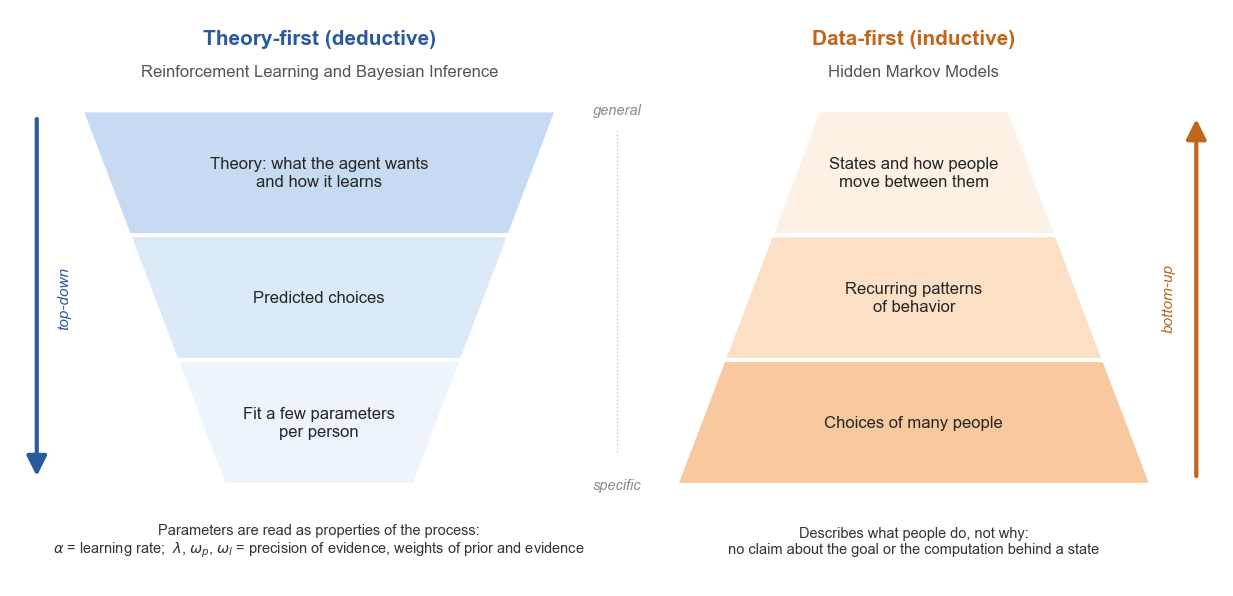

In [7]:
draw_reasoning_triangles()

### Today's behavior is **persistence**: continuing to choose an option that no longer pays off

Our task is **two-armed bandit**: on every trial, the participant chooses one of two arms; one pays off 80% of the time, the other 20%, while the good arm ($g_t$) changes without warning: every 50 trials, the arms swap (a **reversal**).

Suppose a clinical group keeps choosing an arm that has stopped paying off. Two very different explanations fit the same choices:

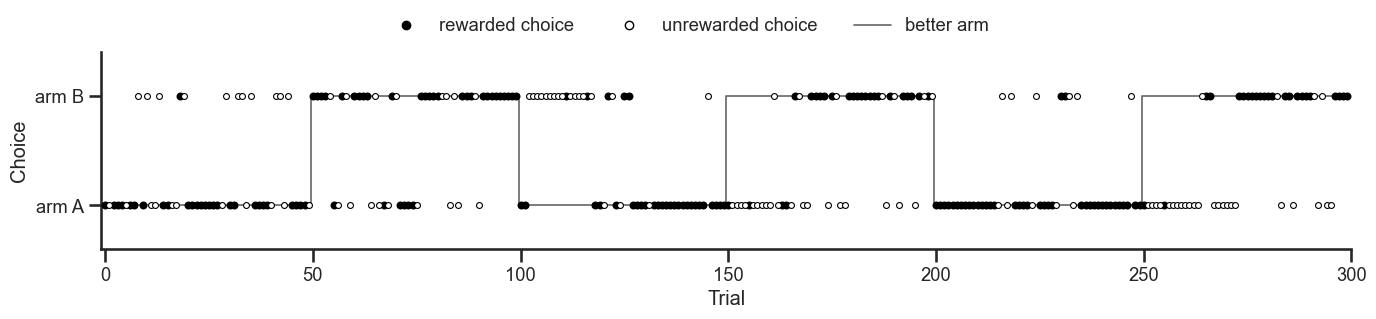

In [9]:
show_example_sessions(states = False) # example participant

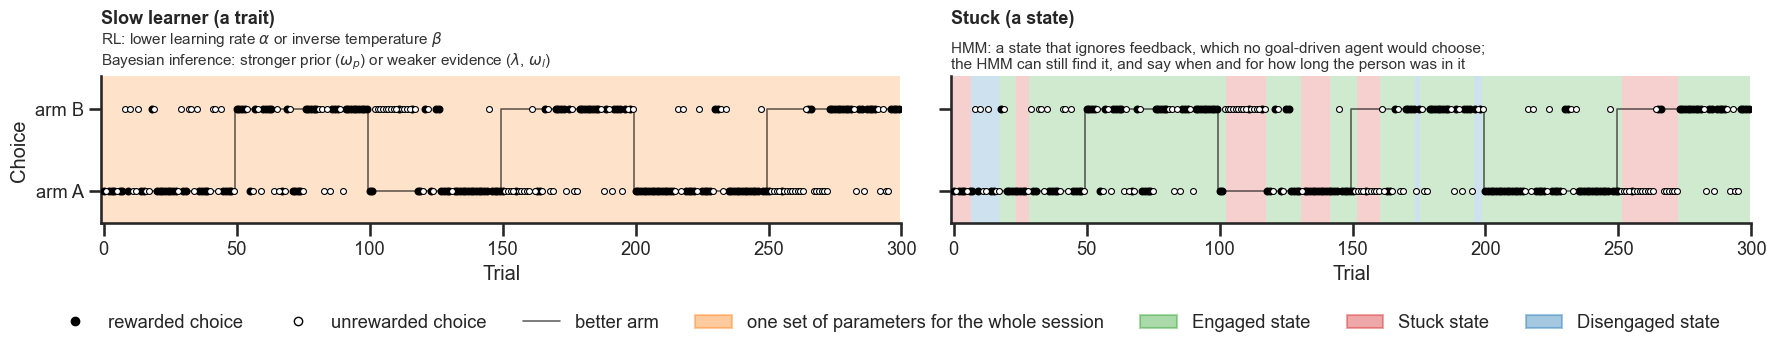

In [10]:
show_example_sessions(states=True, trait=True)   # the same session, read as a trait (left) or as states (right)

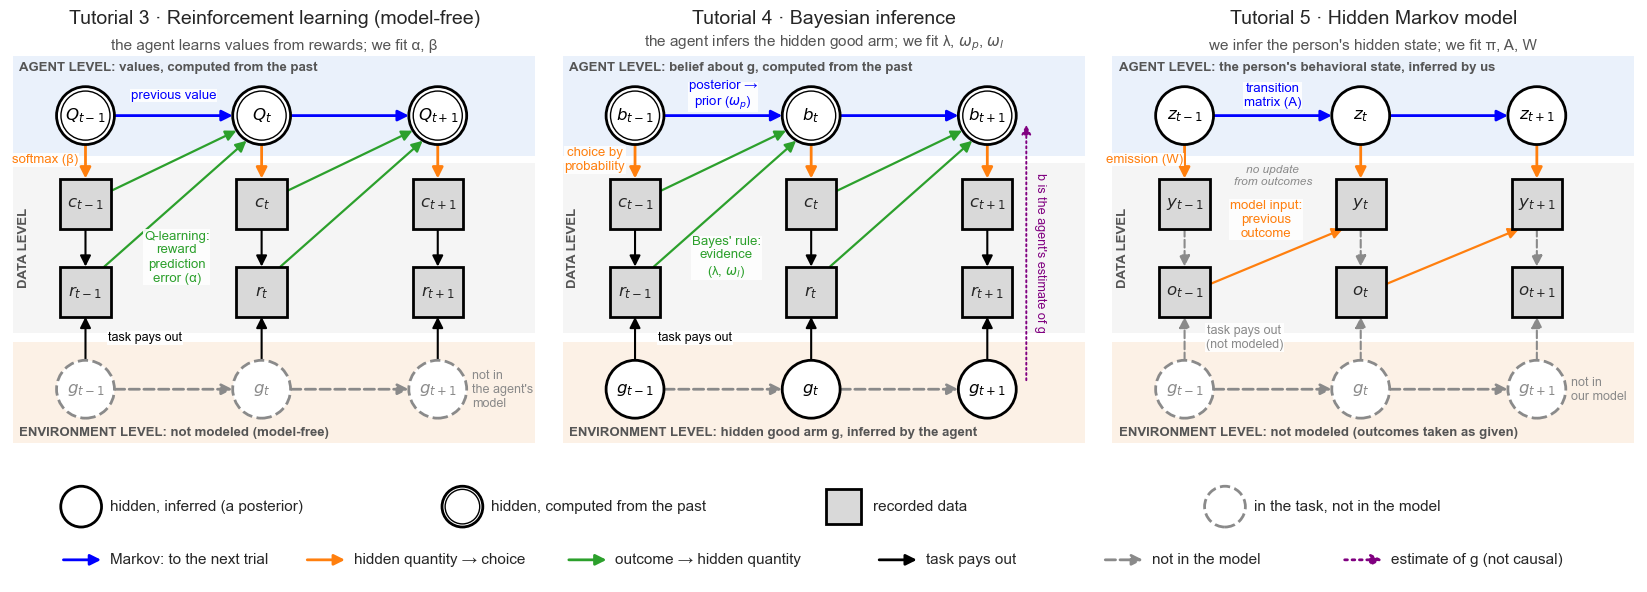

In [11]:
fig = plt.figure(figsize=(21, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.22], hspace=0.05, wspace=0.04)
for i, kind in enumerate(['RL', 'BO', 'HMM']):
    draw_model_family(fig.add_subplot(gs[0, i]), kind)
draw_model_family_key(fig.add_subplot(gs[1, :]))  

| | **Tutorial 3: Reinforcement learning** | **Tutorial 4: Bayesian inference** | **Tutorial 5: Hidden Markov model** |
|---|---|---|---|
| Describes | the **algorithm**: how values are learned | the **computation**: what an ideal observer infers | the **behavior**: which patterns occur, and when |
| Assumed goal | maximize reward | infer the hidden state of the world | not assumed: a state need not serve a goal or be optimal |
| **Agent level** | | | |
| Hidden quantity | values $Q_t$, computed from the past (double circles) | belief $b_t$ about $g$, computed from the past (double circles) | behavioral state $z_t$, inferred by us (single circles) |
| Updated by outcomes? (green) | yes: reward prediction error (Q-learning, $\alpha$) | yes: evidence, no reward needed (Bayes' rule, $\lambda$, $\omega_l$) | no: the HMM makes no claim about how people learn |
| Carried to the next trial (blue) | from the previous value | the posterior becomes the next prior, $\omega_p$ | transition matrix $A$ |
| **Data level** | | | |
| Choice rule (orange) | softmax ($\beta$), one rule for the whole session | choice by probability, one rule for the whole session | one emission per state: a logistic regression on the previous outcome (stay bias $w_0$, reward sensitivity $w_1$) |
| **Environment level** | | | |
| The task | the agent ignores $g$ (dashed circles) | itself an HMM where the agent is trying to learn (purple) | not modeled: the task still pays out (grey dashed), outcomes are taken as given |
| **In practice** | | | |
| A phenotype is | a parameter value ($\alpha$, $\beta$) | a parameter value ($\lambda$, $\omega_p$, $\omega_l$) | how much, how long and how often each state is visited |
| Best suited when | clear goal, stable behavior | clear hidden structure the person can learn | clinical setup/groups, unclear goal/task, or no self-report (e.g., animals) |

## 2. The task, the GLM-HMM and a synthetic cohort

### 2.1 The task: a two-armed probabilistic reversal bandit

Two arms. The *better* arm pays off with probability 0.8 and the other with 0.2. The better arm swaps every 50 trials, and there are 300 trials in total (5 reversals).

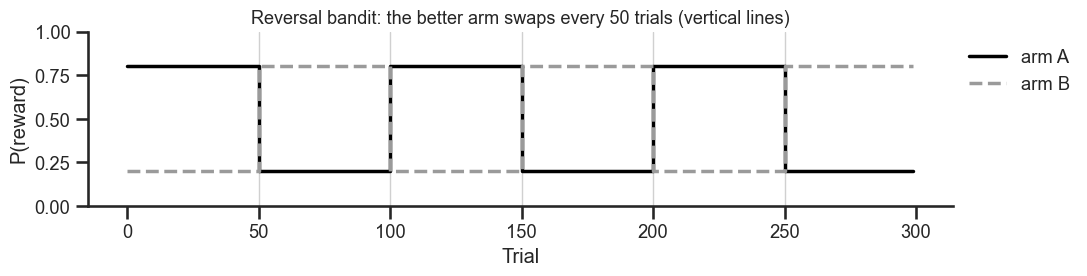

In [15]:
T_TRIALS  = 300      # trials per participant
BLOCK_LEN = 50       # the better arm swaps every 50 trials
P_GOOD    = 0.8      # reward probability of the better arm (the other arm pays 1 - P_GOOD)
REVERSALS = np.arange(BLOCK_LEN, T_TRIALS, BLOCK_LEN)   # trials 50, 100, 150, 200, 250

def better_arm(T=T_TRIALS, block=BLOCK_LEN):
    # Which arm (0 = A, 1 = B) is currently the better one, on every trial.
    return (np.arange(T) // block) % 2

def draw_reward(choice, t, good):
    p = P_GOOD if choice == good[t] else 1 - P_GOOD
    return int(rng.random() < p)

good = better_arm()
fig, ax = plt.subplots(figsize=(11, 3))
ax.step(range(T_TRIALS), np.where(good == 0, P_GOOD, 1 - P_GOOD), where='post', color='black', lw=2.5, label='arm A')
ax.step(range(T_TRIALS), np.where(good == 1, P_GOOD, 1 - P_GOOD), where='post', color='#9a9a9a', lw=2.5, ls='--', label='arm B')
for rv in REVERSALS:
    ax.axvline(rv, color='#d0d0d0', lw=1, zorder=0)
ax.set_ylim(0, 1)
ax.set_xlabel('Trial')
ax.set_ylabel('P(reward)')
ax.set_title('Reversal bandit: the better arm swaps every 50 trials (vertical lines)', fontsize=13)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()

### 2.2 The model's data: observation $y$ and model inputs $x$

For every trial $t \ge 2$, the raw data (choice $c_t$, reward $r_t$) become:

- the **observation** $y_t$, which the model explains: $1$ if the participant repeated the previous choice (stay), $0$ if they switched;
- the **model inputs** $x_t = [\,1,\ o_{t-1}\,]$, which the model conditions on but does not explain: a constant (each state's baseline tendency to stay, like the intercept of a regression) and the **previous outcome** $o_{t-1} = 2\,r_{t-1} - 1$ ($+1$ = win, $-1$ = loss).

**Note**: The outcome of trial $t$ comes from trial $t-1$. The model asks: *given what just happened, does this person repeat their choice?*

Below use one six-trial example: the person wins on A and stays, loses and switches to B, then stays on B through three losses. Trial 1 has no previous outcome, so the model explains five choices (trials 2 to 6).

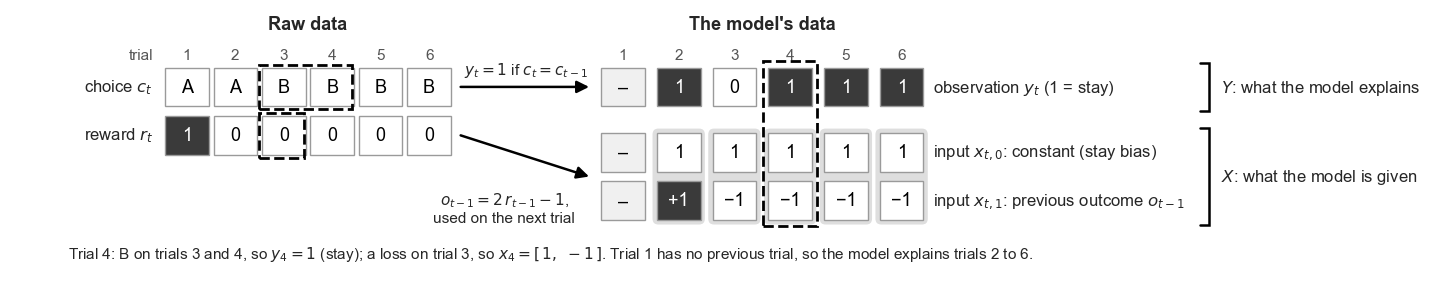

In [17]:
demo_c = np.array([0, 0, 1, 1, 1, 1])     # choices: 0 = arm A, 1 = arm B
demo_r = np.array([1, 0, 0, 0, 0, 0])     # rewards: 1 = win, 0 = loss

def build_design(C, R):
    # Turn choices C and rewards R (participants x trials) into the model's output Y and outcome X.
    # Y[n, t] = 1 if participant n repeated the previous choice (stay), 0 if they switched.
    # X[n, t] = [1, previous outcome], where previous reward = +1 (rewarded) or -1 (not rewarded).
    Y = (C[:, 1:] == C[:, :-1]).astype(float)                          # compare each choice with the one before it
    X = np.stack([np.ones_like(Y), 2.0 * R[:, :-1] - 1.0], axis=-1)     # reward 1/0 -> outcome +1/-1, shifted by one trial
    return X, Y

X_demo, Y_demo = build_design(demo_c[None], demo_r[None])              # [None] adds a 'participant' axis
demo_labels = [f'trial {t}\n{"stay" if y else "switch"}\nafter {"win" if o > 0 else "loss"}' for t, y, o in zip(range(2, 7), Y_demo[0], X_demo[0, :, 1])]       # used to label the figures below

DARK, EMPTY = '#3a3a3a', '#f0f0f0'                                      # dark cell = stay, win or +1; grey cell = no value
def cell(ax, x, y, txt, dark=False, empty=False):
    ax.add_patch(plt.Rectangle((x, y), 0.9, 0.8, fc=DARK if dark else EMPTY if empty else 'white', ec='#9a9a9a', lw=1, zorder=2))
    ax.text(x + 0.45, y + 0.4, txt, ha='center', va='center', fontsize=13, color='white' if dark else 'black', zorder=3)

def bracket(ax, x, y_top, y_bot, label):
    # square bracket opening to the left, with a label on its right
    ax.plot([x, x + 0.2, x + 0.2, x], [y_top, y_top, y_bot, y_bot], color='black', lw=1.8, solid_joinstyle='miter')
    ax.text(x + 0.45, (y_top + y_bot) / 2, label, ha='left', va='center', fontsize=12)

T6, X0, P = len(demo_c), 9.0, 1.15                                      # 6 trials; start and column spacing of the right panel
Y_OBS, Y_X0, Y_X1 = 0, -1.35, -2.35                                     # rows of the right panel
fig, ax = plt.subplots(figsize=(15, 4.6))

# left panel: raw data, trials 1-6
for t in range(T6):
    ax.text(t + 0.45, 1.05, str(t + 1), ha='center', va='center', fontsize=11, color='#555555')
    cell(ax, t, 0, 'AB'[demo_c[t]])
    cell(ax, t, -1, str(demo_r[t]), dark=demo_r[t] == 1)
for y, lab in [(0, 'choice $c_t$'), (-1, 'reward $r_t$')]:
    ax.text(-0.25, y + 0.4, lab, ha='right', va='center', fontsize=12)
ax.text(-0.25, 1.05, 'trial', ha='right', va='center', fontsize=11, color='#555555')
ax.text(T6 / 2 - 0.05, 1.7, 'Raw data', ha='center', va='center', fontsize=13, fontweight='bold')

# right panel: observation y_t and input vector x_t = [1, o_{t-1}] for trials 1-6; trial 1 has no previous trial ('–')
for t in range(T6):
    x = X0 + t * P
    ax.text(x + 0.45, 1.05, str(t + 1), ha='center', va='center', fontsize=11, color='#555555')
    if t == 0:
        for yy in (Y_OBS, Y_X0, Y_X1):
            cell(ax, x, yy, '–', empty=True)
        continue
    y, o = int(Y_demo[0, t - 1]), int(X_demo[0, t - 1, 1])             # Y_demo and X_demo start at trial 2
    cell(ax, x, Y_OBS, str(y), dark=y == 1)
    ax.add_patch(FancyBboxPatch((x - 0.09, Y_X1 - 0.09), 1.08, Y_X0 - Y_X1 + 0.98, boxstyle='round,pad=0,rounding_size=0.12',
                                fc='#dedede', ec='none', zorder=1))     # grey backing: one input vector x_t per trial
    cell(ax, x, Y_X0, '1')
    cell(ax, x, Y_X1, f'{o:+d}'.replace('-', '−'), dark=o > 0)
xr = X0 + (T6 - 1) * P + 1.1                                            # right-hand row labels
row_labels = [ax.text(xr, y + 0.4, lab, ha='left', va='center', fontsize=12) for y, lab in
              [(Y_OBS, 'observation $y_t$ (1 = stay)'), (Y_X0, 'input $x_{t,0}$: constant (stay bias)'),
               (Y_X1, 'input $x_{t,1}$: previous outcome $o_{t-1}$')]]
ax.text(X0 + ((T6 - 1) * P + 0.9) / 2, 1.7, "The model's data", ha='center', va='center', fontsize=13, fontweight='bold')

# arrows: choices -> observations, rewards -> inputs of the next trial
mid = (T6 + X0 - 0.1) / 2
arrow = dict(arrowstyle='-|>', color='black', lw=1.8, shrinkA=0, shrinkB=0, mutation_scale=18)
ax.annotate('', xy=(X0 - 0.25, Y_OBS + 0.4), xytext=(T6 + 0.1, Y_OBS + 0.4), arrowprops=arrow)
ax.text(mid, Y_OBS + 0.55, '$y_t = 1$ if $c_t = c_{t-1}$', ha='center', va='bottom', fontsize=11)
ax.annotate('', xy=(X0 - 0.25, (Y_X0 + Y_X1) / 2 + 0.4), xytext=(T6 + 0.1, -1 + 0.4), arrowprops=arrow)
ax.text(mid - 0.45, -1.75, '$o_{t-1} = 2\\,r_{t-1} - 1$,\nused on the next trial', ha='center', va='top', fontsize=11)

# worked example: trial 4
for (x, y, w, h) in [(1.94, -0.06, 1.92, 0.92), (1.94, -1.06, 0.92, 0.92), (X0 + 3 * P - 0.1, Y_X1 - 0.13, 1.1, Y_OBS - Y_X1 + 1.06)]:
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='black', lw=2, ls='--', zorder=4))
ax.text((X0 + T6 * P) / 2, -2.85, 'Trial 4: B on trials 3 and 4, so $y_4 = 1$ (stay); a loss on trial 3, so $x_4 = [\\,1,\\ -1\\,]$. Trial 1 has no previous trial, so the model explains trials 2 to 6.', ha='center', va='top', fontsize=11)

ax.set_xlim(-3.2, xr + 10.2)
ax.set_ylim(-3.75, 2.0)
ax.set_aspect('equal')
ax.axis('off')
fig.tight_layout()

# brackets for Y and X, just right of the longest row label (measured after layout)
fig.canvas.draw()
xb = max(ax.transData.inverted().transform(lab.get_window_extent().get_points())[1, 0] for lab in row_labels) + 0.3
bracket(ax, xb, Y_OBS + 0.9, Y_OBS - 0.1, '$Y$: what the model explains')
bracket(ax, xb, Y_X0 + 0.9, Y_X1 - 0.1, '$X$: what the model is given')

### 2.3 Parameters of a GLM-HMM (will be inferred)

| Part | Parameters | Question it answers |
|---|---|---|
| (a) Hidden dynamics | initial distribution $\pi_k = P(z_1 = k)$ | What's the first state?|
|  | transition matrix $A_{ij} = P(z_{t+1} = j \mid z_t = i)$ | Which state comes next? |
| (b) Emissions | $B_{t,k} = P(y_t \mid z_t = k,\ x_t)$, the probability of the observed choice under each state | What does each state do? |

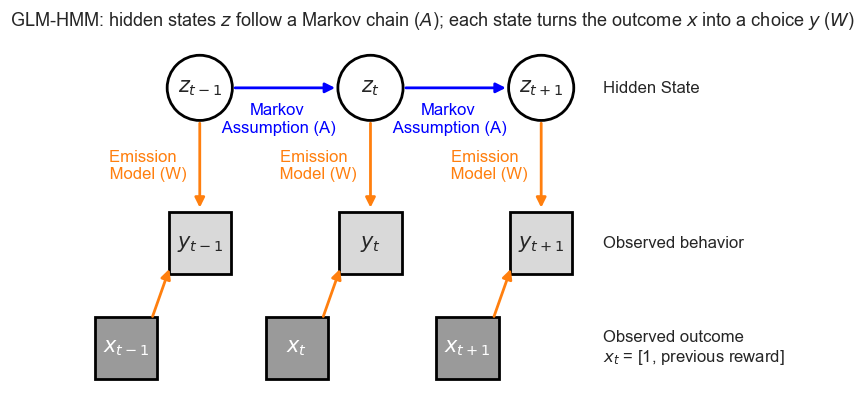

In [19]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
draw_graphical_model(ax, True)
ax.set_title('GLM-HMM: hidden states $z$ follow a Markov chain ($A$); each state turns the outcome $x$ into a choice $y$ ($W$)', fontsize=13)
fig.tight_layout()

#### 2.3a Hidden dynamics: the Markov chain ($\pi$, $A$)

**The Markov property**: the next state depends only on the current one: 
$$P(z_t \mid z_{t-1}, \dots, z_1) = P(z_t \mid z_{t-1}) = A_{z_{t-1}, z_t}$$

Our three states are Engaged, Stuck and Disengaged. Its diagonal is close to 1, so states persist and the chain produces *episodes*. On every trial, state $k$ is left with probability $1 - A_{kk}$, so episode lengths follow a **geometric distribution**:

$$P(D_k = d) = A_{kk}^{\,d-1}\,(1-A_{kk}), \qquad \text{expected dwell time: } E[D_k] = \frac{1}{1 - A_{kk}}$$

Stuck episodes last about $10$ trials ($A_{S \to S} = 0.90$), Engaged episodes about $40$ ($A_{E \to E} = 0.975$).

rows of A sum to [1. 1. 1.]


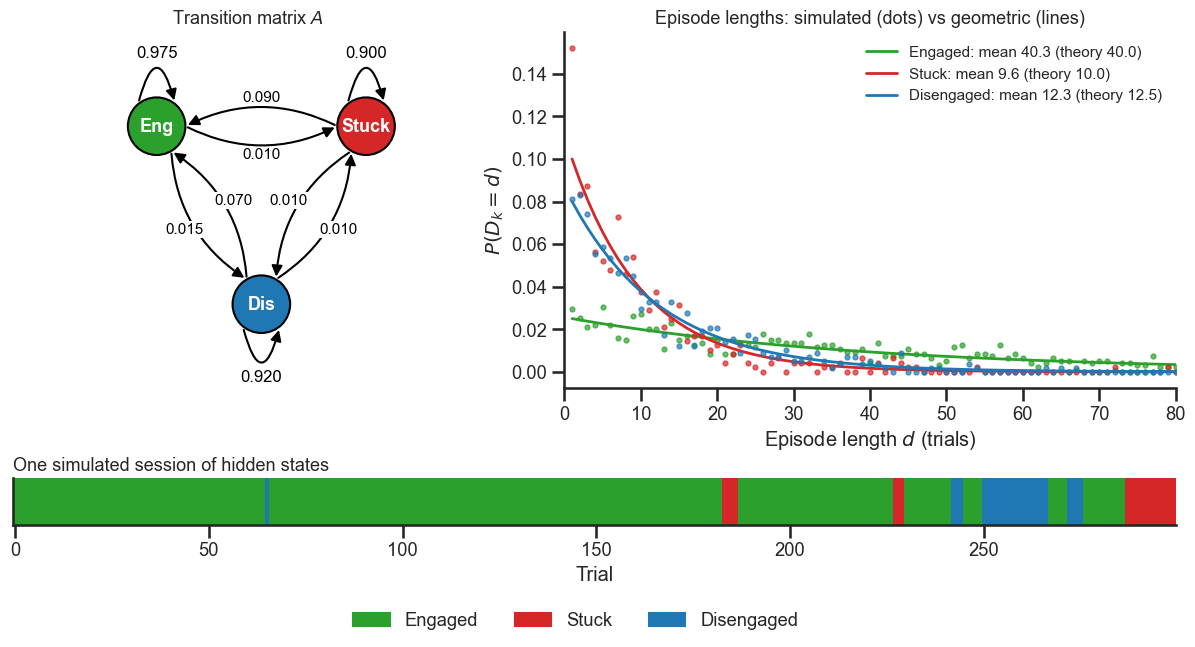

In [21]:
PI_TRUE = np.array([0.8, 0.1, 0.1])              # most people start Engaged
#                  to: Eng    Stuck  Dis
A_HC = np.array([[0.975, 0.010, 0.015],          # from Engaged
                 [0.090, 0.900, 0.010],          # from Stuck
                 [0.070, 0.010, 0.920]])         # from Disengaged
print('rows of A sum to', A_HC.sum(1))

def simulate_markov_chain(pi, A, T):
    # Sample a hidden state sequence z_1..z_T from a Markov chain.
    z = np.zeros(T, int)
    z[0] = rng.choice(len(pi), p=pi)                # first state from the initial distribution
    for t in range(1, T):
        z[t] = rng.choice(len(pi), p=A[z[t-1]])     # next state depends ONLY on the current state
    return z

z_demo = simulate_markov_chain(PI_TRUE, A_HC, T_TRIALS)      # one simulated session
z_long = simulate_markov_chain(PI_TRUE, A_HC, 50000)         # a long chain to estimate dwell times

fig = plt.figure(figsize=(15, 6.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.13], width_ratios=[1, 1.3], hspace=0.45, wspace=0.15)
ax_d, ax_h, ax_s = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
draw_hmm_diagram(ax_d, ['Eng', 'Stuck', 'Dis'], A_HC, STATE_COLORS, fmt='{:.3f}', title='Transition matrix $A$')
d = np.arange(1, 81)
for k in range(3):
    runs = run_lengths(z_long, k)
    ax_h.plot(d, [np.mean(runs == x) for x in d], 'o', color=STATE_COLORS[k], ms=3.5, alpha=0.7)           # simulated
    ax_h.plot(d, (1 - A_HC[k, k]) * A_HC[k, k] ** (d - 1), '-', color=STATE_COLORS[k], lw=2,                # geometric
              label=f'{STATES[k]}: mean {runs.mean():.1f} (theory {1 / (1 - A_HC[k, k]):.1f})')
ax_h.set(xlabel='Episode length $d$ (trials)', ylabel='$P(D_k = d)$', xlim=(0, 80))
ax_h.legend(frameon=False, fontsize=11)
ax_h.set_title('Episode lengths: simulated (dots) vs geometric (lines)', fontsize=13)
shade_states(ax_s, z_demo, alpha=1)
ax_s.set(xlim=(-0.5, T_TRIALS - 0.5), yticks=[], xlabel='Trial')
ax_s.set_title('One simulated session of hidden states', fontsize=13, loc='left')
state_legend(fig, y=0.0, alpha=1)

#### 2.3b Emissions: rule for producing observed behavior from hidden states ($W= [\,w_{0},\ w_{1}\,]$)

Our three ground-truth states:

| State | $w_0$ (stay bias) | $w_1$ (reward sensitivity) |
|---|---|---|
| **Engaged** | 0.5 | 2.0 |
| **Stuck** | 3.0 | 0.0 |
| **Disengaged** | 0.0 | 0.0 |

Three steps turn the inputs into the emission of state $k$ on trial $t$:

**(i) Weighted sum** (the "linear predictor") $u_{t,k} = w_{k} \cdot x_{t} = 1\cdot w_{k,0}  +  o_{t-1} \cdot w_{k,1} $, where $w_{k} = [\,w_{k,0},\ w_{k,1}\,]$.
- $w_{k,0}$ is the baseline tendency to repeat the choice while in state $k$ (**stay bias**).
- $w_{k,1}$ is how strongly, while in state k, a win pushes the person to repeat the choice and a loss pushes them to switch arms (**reward sensitivity**).
  
**(ii) Squash it into a probability** with the logistic (sigmoid) function: $p_{t,k} = \sigma(u_{t,k}) = \dfrac{1}{1 + e^{-u_{t,k}}}$. This is P(stay | state $k$, $x_{t}$).

**(iii) Score what actually happened**: the emission probability is the probability of the observed choice,
$$B_{t,k} = \begin{cases} p_{t,k} & \text{if the person stayed } (y_t = 1) \\ 1 - p_{t,k} & \text{if the person switched } (y_t = 0) \end{cases}$$

The key assumption: $y_t$ depends only on the current state $z_t$ and the inputs $x_t$. 

| State | P(stay \| win) = $\sigma(w_0 + w_1)$ | P(stay \| loss) = $\sigma(w_0 - w_1)$ | Behavior |
|---|---|---|---|
| **Engaged** | 0.92 | 0.18 | win → stay, lose → switch |
| **Stuck** | 0.95 | 0.95 | stays, **regardless of reward** |
| **Disengaged** | 0.50 | 0.50 | coin-flip choices |

Trial 4: previous outcome o = -1 (a loss); observed y = 1 (stayed), so B = P(stay)



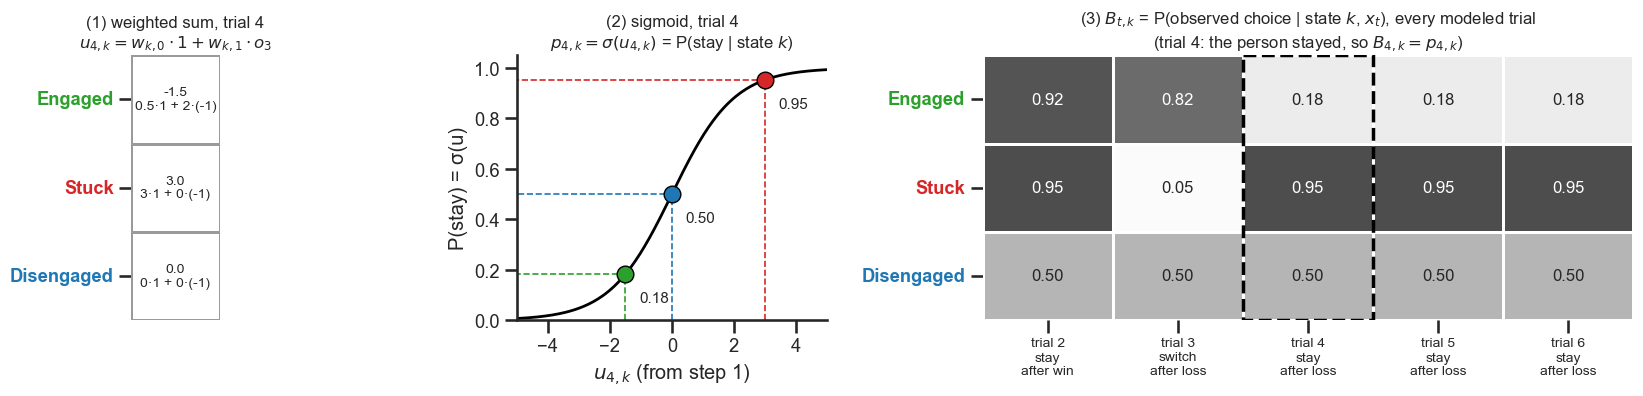

In [23]:
W_TRUE = np.array([[0.5, 2.0],     # Engaged:    [stay bias w0, reward sensitivity w1]
                   [3.0, 0.0],     # Stuck:      strong stay bias, ignores reward
                   [0.0, 0.0]])    # Disengaged: random

def stay_probs(W):
    # P(stay | previous win) and P(stay | previous loss) for each state.
    return expit(W[:, 0] + W[:, 1]), expit(W[:, 0] - W[:, 1])

def emission_probs(X, Y, W):
    # The three steps above, for every participant n, trial t and state k.  X: (N, L, 2), Y: (N, L), W: (K, 2)
    U = X @ W.T                                              # step 1: weighted sum u = w0*1 + w1*o_prev (one per state)
    P_stay = expit(U)                                        # step 2: sigmoid -> P(stay | state, inputs)
    return np.where(Y[..., None] == 1, P_stay, 1 - P_stay)   # step 3: probability of the choice actually made

B_demo = emission_probs(X_demo, Y_demo, W_TRUE)[0]           # (5 modeled trials, 3 states): the table the algorithms use
i4 = 2                                                       # worked example: trial 4 (X and Y start at trial 2, so trial 4 is index 2)
x4 = X_demo[0, i4]
u4 = W_TRUE @ x4                                             # step 1: one weighted sum per state
p4 = expit(u4)                                               # step 2: P(stay | state, x_4)
print(f'Trial 4: previous outcome o = {x4[1]:+.0f} (a loss); observed y = {Y_demo[0, i4]:.0f} (stayed), so B = P(stay)\n')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1.2, 1, 2.1]})
txt = [[f'{u4[k]:.1f}\n{W_TRUE[k, 0]:g}·1 + {W_TRUE[k, 1]:g}·({x4[1]:+.0f})'] for k in range(3)]
sns.heatmap(u4[:, None], annot=np.array(txt), fmt='', cmap=ListedColormap(['white']), cbar=False, square=True, ax=ax[0], xticklabels=False, yticklabels=STATES, annot_kws={'size': 10}, linewidths=1, linecolor='#9a9a9a')
ax[0].set_title('(1) weighted sum, trial 4\n$u_{4,k} = w_{k,0} \\cdot 1 + w_{k,1} \\cdot o_3$', fontsize=12)
color_states(ax[0].get_yticklabels())
ax[0].tick_params(axis='y', rotation=0)

u = np.linspace(-5, 5, 200)
ax[1].plot(u, expit(u), color='black', lw=2, zorder=1)
for k in range(3):
    ax[1].plot([u4[k], u4[k], -5], [0, p4[k], p4[k]], '--', color=STATE_COLORS[k], lw=1.2)    # up from u, across to P(stay)
    ax[1].plot(u4[k], p4[k], 'o', color=STATE_COLORS[k], ms=12, mec='black', zorder=3)
    ax[1].annotate(f'{p4[k]:.2f}', (u4[k], p4[k]), xytext=(10, -20), textcoords='offset points', fontsize=11)
ax[1].set(xlim=(-5, 5), ylim=(0, 1.05), xlabel='$u_{4,k}$ (from step 1)', ylabel='P(stay) = σ(u)')
ax[1].set_title('(2) sigmoid, trial 4\n$p_{4,k} = \\sigma(u_{4,k})$ = P(stay | state $k$)', fontsize=12)

plot_matrix(ax[2], B_demo.T, STATES, demo_labels, '(3) $B_{t,k}$ = P(observed choice | state $k$, $x_t$), every modeled trial\n(trial 4: the person stayed, so $B_{4,k} = p_{4,k}$)', fmt='.2f', vmax=1.25, from_to=False, size=12, title_size=12, linewidths=1, linecolor='white')
color_states(ax[2].get_yticklabels())
ax[2].tick_params(axis='x', labelsize=10, rotation=0)
ax[2].add_patch(plt.Rectangle((i4, 0), 1, 3, fill=False, ec='black', lw=2.5, ls='--'))          # trial 4
fig.tight_layout()

**Note**:
- After a win, Engaged and Stuck both stay $(0.92$ vs $0.95)$. Only losses separate them.
- After a loss, a switch points to Engaged (trial 3: $0.82$ vs $0.05$), and a stay points to Stuck (trials 4 to 6: $0.95$ vs $0.18$, about $5\times$).
- Disengaged gives every choice a probability of $0.5$: it doesn't explains a trial best, and not badly either.

### 2.4 Mechanics of an HMM on six trials (Optional)

| Question | Algorithm | Output |
|---|---|---|
| (a) Evaluation: how likely are the data? | forward | $P(\text{data} \mid \pi, A, W)$ |
| (b) Decoding: which states produced the data? | forward–backward; Viterbi | posteriors $\gamma_t$ and $\xi_t$; the single most likely state path |
| (c) Learning: where do the parameters come from? | Expectation-Maximization (EM) | the parameters $\hat\lambda = (\hat\pi, \hat A, \hat W)$ |

#### 2.4a Evaluation: how likely are the data?

**(i) Brute force.** Multiply out every hidden path ($3^5 = 243$ here), then add them all up:

$$P(\text{path}, \text{data}) = \pi_{z_1} B_{1,z_1} \cdot A_{z_1 z_2} B_{2,z_2} \cdots A_{z_{T-1} z_T} B_{T,z_T}, \qquad P(\text{data}) = \sum_{\text{paths}} P(\text{path}, \text{data})$$

By Bayes' rule:

$$P(\text{path}|\text{data}) =\frac{P(\text{path}, \text{data})}{P(\text{data})}$$

With 3 states and 299 modeled trials there are about $10^{143}$ paths, so brute force is not feasible.

**(ii) Forward algorithm.** $\alpha_t(k) = P(y_1, \dots, y_t,\ z_t = k)$, the probability of the data so far *and* of being in state $k$ now, is updated one trial at a time:

$$\alpha_1(k) = \pi_k B_{1,k}, \qquad \alpha_t(j) = \Big[\sum_i \alpha_{t-1}(i)\, A_{ij}\Big]\, B_{t,j}, \qquad P(\text{data}) = \sum_k \alpha_T(k)$$

In words: (each way to be in $i$ a trial ago) × (move $i \to j$) × ($j$ produces what we saw). The cost is $K^2 T$ instead of $K^T$.

                                    path  P(path, data)  P(path | data)
0      Eng → Eng → Stuck → Stuck → Stuck         0.0041          0.2488
1            Eng → Eng → Eng → Eng → Eng         0.0033          0.2000
2  Stuck → Stuck → Stuck → Stuck → Stuck         0.0026          0.1545
3            Dis → Dis → Dis → Dis → Dis         0.0022          0.1350
4            Eng → Eng → Dis → Dis → Dis         0.0009          0.0564
... and 238 more paths

Brute force: P(data) = 0.01658
Forward:     P(data) = 0.01658   <- identical


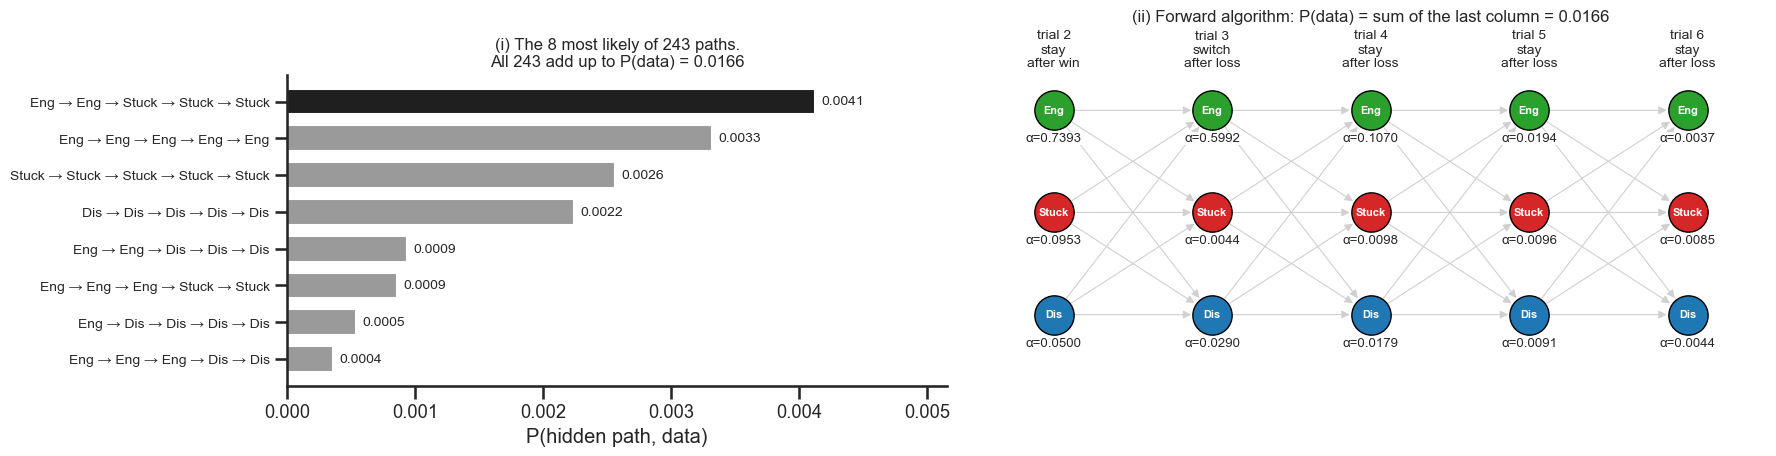

In [27]:
NAMES = ['Eng', 'Stuck', 'Dis']                                     # short state names for tables and figures
T_demo = len(B_demo)

# (i) brute force: all 3^5 = 243 hidden paths
rows = []
for path in product(range(3), repeat=T_demo):
    p = PI_TRUE[path[0]] * B_demo[0, path[0]]                        # start: initial probability x emission
    for t in range(1, T_demo):
        p *= A_HC[path[t-1], path[t]] * B_demo[t, path[t]]           # each step: transition x emission
    rows.append({'path': ' → '.join(NAMES[k] for k in path), 'P(path, data)': p})
paths = pd.DataFrame(rows).sort_values('P(path, data)', ascending=False).reset_index(drop=True)
P_brute = paths['P(path, data)'].sum()

# (ii) forward algorithm
def forward_demo(B, pi, A):
    # Forward algorithm without rescaling (fine for a few trials). B: (T, K) emission table.
    alpha = np.zeros_like(B)
    alpha[0] = pi * B[0]                                             # initialise
    for t in range(1, len(B)):
        alpha[t] = (alpha[t-1] @ A) * B[t]                           # sum over previous states, then emit
    return alpha

alpha_demo = forward_demo(B_demo, PI_TRUE, A_HC)
P_data = alpha_demo[-1].sum()
paths['P(path | data)'] = paths['P(path, data)'] / P_data            # Bayes' rule
print(paths.head(5).to_string(float_format='%.4f'))
print(f'... and {len(paths) - 5} more paths\n')
print(f'Brute force: P(data) = {P_brute:.5f}')
print(f'Forward:     P(data) = {P_data:.5f}   <- identical')

fig, ax = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={'width_ratios': [1, 1.2]})
top = paths.head(8)[::-1]
ax[0].barh(top['path'], top['P(path, data)'], color=['#9a9a9a'] * 7 + ['#1f1f1f'], height=0.7)
for i, p in enumerate(top['P(path, data)']):
    ax[0].text(p + 0.00005, i, f'{p:.4f}', va='center', fontsize=10)
ax[0].set_xlim(0, top['P(path, data)'].max() * 1.25)
ax[0].tick_params(axis='y', labelsize=10)
ax[0].set_xlabel('P(hidden path, data)')
ax[0].set_title(f'(i) The 8 most likely of 243 paths.\nAll 243 add up to P(data) = {P_brute:.4f}', fontsize=12)
draw_trellis(ax[1], alpha_demo, demo_labels, label='α', fmt='.4f', title=f'(ii) Forward algorithm: P(data) = sum of the last column = {P_data:.4f}')
fig.tight_layout()

**Note**: The forward algorithm gives exactly the brute-force answer. The best path (Engaged, Engaged, Stuck, Stuck, Stuck) has only about $25\%$ of the posterior.

#### 2.4b Decoding: which states produced the data?

**(i) Soft, per trial: posterior state probabilities $\gamma$.** A **backward pass**, $\beta_t(k) = P(y_{t+1}, \dots, y_T \mid z_t = k)$, runs from the last trial back: $\beta_T(k) = 1$ and $\beta_t(i) = \sum_j A_{ij}\, B_{t+1,j}\, \beta_{t+1}(j)$. Given $z_t$, the past and the future observations are independent, so

$$\gamma_t(k) = P(z_t = k \mid \text{data}) = \frac{\alpha_t(k)\,\beta_t(k)}{P(\text{data})}$$

In Bayesian terms with $P(\text{data}) = P(\text{past})P(\text{future}|\text{past})$:

$$\gamma_t(k) = \frac{\text{prior: forward belief}\cdot\text{likelihood of the future}}{\text{evidence}} = \frac{P(z_{t}=k|\text{past}) P(\text{future}|z_{t}=k)}{P(\text{future}|\text{past})}$$

**(ii) Soft, per move: posterior transition probabilities $\xi$.** Our main questions are about moves (e.g. how often does someone *enter* Stuck?), and a move spans two trials:

$$\xi_t(i, j) = P(z_t = i,\ z_{t+1} = j \mid \text{data}) = \frac{\alpha_t(i)\; A_{ij}\; B_{t+1,j}\; \beta_{t+1}(j)}{P(\text{data})}$$

Each $\xi_t$ is a $K \times K$ table that sums to 1; its rows sum to $\gamma_t$ and its columns to $\gamma_{t+1}$. $\xi$ is not $A$: $A$ is the model's general rule, and $\xi_t$ is what the model infers for *this* pair of trials.

**(iii) Hard: the single most likely path (Viterbi).** The forward algorithm with max instead of sum. On every trial, each state keeps only its best way of getting there and a *back-pointer* to where it came from:

$$\delta_1(k) = \pi_k B_{1,k}, \qquad \delta_t(j) = \max_i \big[\delta_{t-1}(i)\, A_{ij}\big]\, B_{t,j}$$

At the end, we pick the best final state and follow the back-pointers.

(i) gamma = P(state | all data):
         Engaged  Stuck  Disengaged
trial 2    0.666  0.171       0.163
trial 3    0.624  0.175       0.201
trial 4    0.301  0.448       0.251
trial 5    0.228  0.508       0.264
trial 6    0.225  0.512       0.263 

(ii) xi = P(move | all data); each column of xi sums to 1, each row of A sums to 1:
             trials 2→3  trials 3→4  trials 4→5  trials 5→6  A (rule)
Eng→Eng           0.614       0.300       0.224       0.208     0.975
Eng→Stuck         0.014       0.261       0.054       0.011     0.010
Eng→Dis           0.038       0.063       0.023       0.009     0.015
Stuck→Eng         0.007       0.000       0.002       0.009     0.090
Stuck→Stuck       0.160       0.174       0.445       0.496     0.900
Stuck→Dis         0.003       0.000       0.001       0.003     0.010
Dis→Eng           0.003       0.001       0.003       0.007     0.070
Dis→Stuck         0.001       0.013       0.009       0.005     0.010
Dis→Dis           0.159       0.187

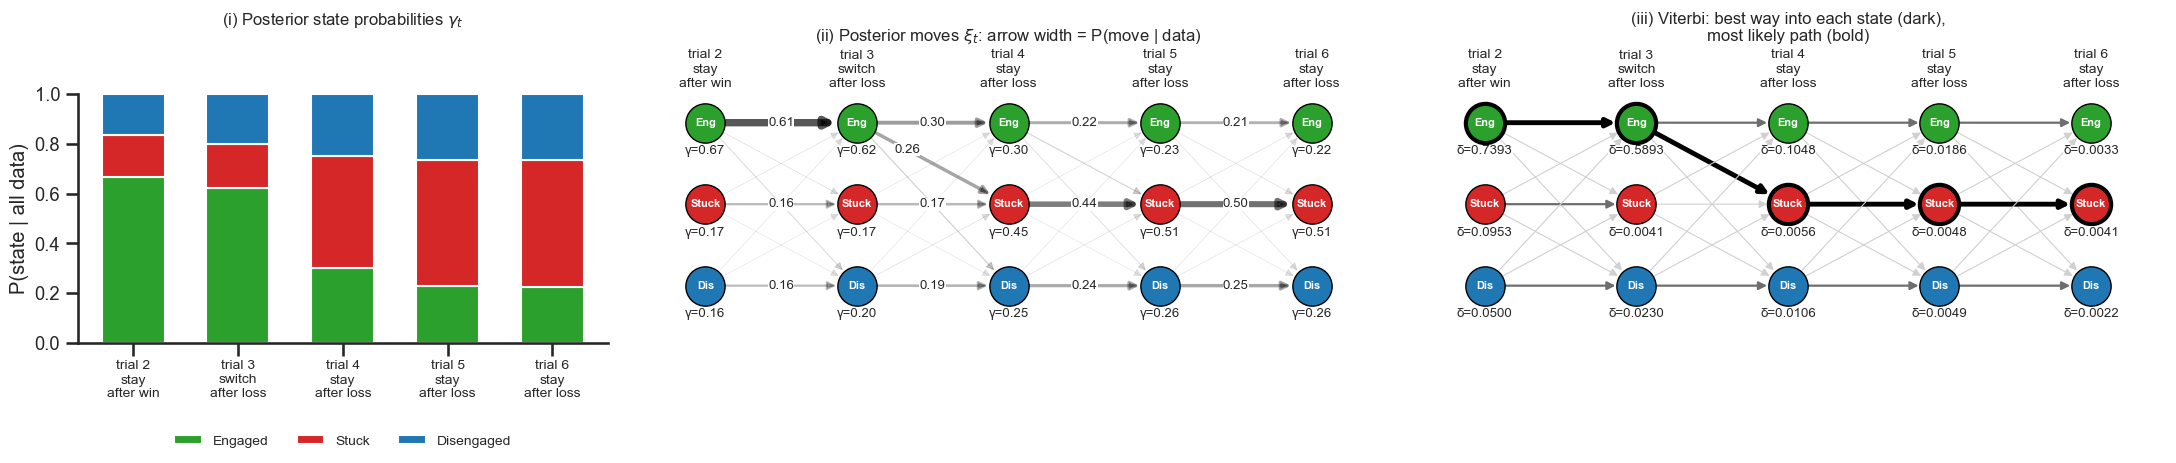

In [30]:
# (i) backward pass, then gamma
beta_demo = np.ones_like(alpha_demo)
for t in range(T_demo - 2, -1, -1):
    beta_demo[t] = A_HC @ (B_demo[t+1] * beta_demo[t+1])                              # backward recursion
gamma_demo = alpha_demo * beta_demo / P_data                                          # P(z_t = k | all data)

# (ii) xi[t, i, j] = P(z_t = i, z_t+1 = j | all data): one K x K table for each pair of neighbouring trials
xi_demo = np.array([alpha_demo[t][:, None] * A_HC * (B_demo[t+1] * beta_demo[t+1])[None, :] / P_data for t in range(T_demo - 1)])

# (iii) Viterbi: max instead of sum, plus back-pointers
def viterbi_demo(B, pi, A):
    T, K = B.shape
    delta, back = np.zeros((T, K)), np.zeros((T, K), int)
    delta[0] = pi * B[0]
    for t in range(1, T):
        scores = delta[t-1][:, None] * A              # scores[i, j] = best way to reach i, then move i -> j
        back[t] = scores.argmax(0)                    # remember the best predecessor of each state j
        delta[t] = scores.max(0) * B[t]
    path = [int(delta[-1].argmax())]                  # best final state...
    for t in range(T - 1, 0, -1):
        path.insert(0, int(back[t, path[0]]))         # ...then follow the back-pointers
    return path, delta, back

vit_path, delta_demo, back_demo = viterbi_demo(B_demo, PI_TRUE, A_HC)

print('(i) gamma = P(state | all data):')
print(pd.DataFrame(gamma_demo, index=[f'trial {t + 2}' for t in range(T_demo)], columns=STATES).round(3).to_string(), '\n')
xi_table = pd.DataFrame(xi_demo.reshape(T_demo - 1, -1).T, index=[f'{a}→{b}' for a in NAMES for b in NAMES],
                        columns=[f'trials {t + 2}→{t + 3}' for t in range(T_demo - 1)])
xi_table['A (rule)'] = A_HC.ravel()
print('(ii) xi = P(move | all data); each column of xi sums to 1, each row of A sums to 1:')
print(xi_table.round(3).to_string(), '\n')
print('(iii) Viterbi path:     ', ' → '.join(NAMES[k] for k in vit_path))
print('     brute-force best path:', paths.path[0])

fig, ax = plt.subplots(1, 3, figsize=(22, 5.4), gridspec_kw={'width_ratios': [0.7, 1, 1]})
bottom = np.zeros(T_demo)
for k in range(3):
    ax[0].bar(np.arange(T_demo), gamma_demo[:, k], bottom=bottom, color=STATE_COLORS[k], width=0.6, label=STATES[k])
    bottom += gamma_demo[:, k]
ax[0].set_xticks(range(T_demo), demo_labels, fontsize=10)
ax[0].set(ylim=(0, 1), ylabel='P(state | all data)')
ax[0].legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=10)
ax[0].set_title('(i) Posterior state probabilities $\\gamma_t$', fontsize=12, pad=50)      # aligned with the trellis titles
draw_trellis(ax[1], gamma_demo, demo_labels, label='γ', fmt='.2f', edges=xi_demo, edge_min=0.1, scale_edges=True,
             title='(ii) Posterior moves $\\xi_t$: arrow width = P(move | data)')
draw_trellis(ax[2], delta_demo, demo_labels, label='δ', fmt='.4f', back=back_demo, best_path=vit_path,
             title='(iii) Viterbi: best way into each state (dark),\nmost likely path (bold)')
fig.tight_layout()

**Note**:
- $\gamma$ moves from Engaged to Stuck as the lose-stays accumulate, but after three of them $P(\text{Stuck})$ is still only about $0.5$. Disengaged keeps $16\%$ to $26\%$, because a coin-flipper can produce any five choices.
- On trial 3, a switch after a loss (probability $0.05$ under Stuck), $P(\text{Stuck})$ is still about $0.17$: the all-Stuck path pays $0.05$ once instead of paying for the rare move Engaged → Stuck ($0.01$). The posterior always weighs the emissions against the transitions.
- The transitio rule, $A$, says moves are rare; the data say when one most likely happened.
- Viterbi returns the best path of the brute-force table and commits to it, although it holds only about $25\%$ of the posterior. Section 3.5 shows what this costs.

#### 2.4c Learning: where do the parameters come from? (EM)

With real data the parameters, $\lambda = (\pi, A, W)$, are unknown. **Expectation-Maximization (EM)**, called **Baum–Welch** for HMMs, learns them:

1. **E-step:** run forward–backward with the current parameters to get soft state labels $\gamma_t(k)$ and soft move counts $\xi_t(i,j)$.
2. **M-step:** re-estimate the parameters as if the soft labels were true: $\pi$ and $A$ from the expected counts (e.g., $A_{ij} \propto \sum_t \xi_t(i, j)$), and each $w_k$ from a **weighted logistic regression** of *stay* on $x_t$, summed over all participants $n$ and trials $t$:

   $$\hat w_k = \arg\max_{w} \; \sum_{n,t} q^{(n)}_t(k)\, \Big[\, y_t \log \sigma(w \cdot x_t) + (1 - y_t) \log\big(1 - \sigma(w \cdot x_t)\big) \Big] \;-\; \frac{\kappa}{2}\,\lVert w \rVert^2$$

3. **Repeat.** The likelihood never goes down, so we stop when it stops improving.

**Note:** The term in brackets is $\log B_{t,k}$. The small L2 penalty, $\kappa $, acts as a Gaussian prior that keeps the weights finite. The trial weight $q_t(k)$ is how much trial $t$ counts toward state $k$: $1$ or $0$ when the states are known, and $\gamma_t(k)$ in EM, so a trial that is 90% likely to be Stuck counts $0.9$ toward the Stuck regression and $0.1$ toward the others.

### 2.5 Ground truth: two groups that differ only in their dynamics

Both groups use the same three policies ($W$) and similar background dynamics: they enter Stuck at the same low rate at random times $(0.01)$. They differ in two ways:
- After a reversal, a loss from the arm that just stopped paying (within the first $3$ trials of the new block) pushes an engaged CLIN participant into Stuck with probability $0.50$ (HC: $0.05$).
- CLIN Stuck episodes last longer ($A_{S\to S}$ $0.95$ vs $0.90$, about $20$ vs $10$ trials): both ways out of Stuck are halved (Stuck→Engaged $0.045$ vs $0.090$, Stuck→Disengaged $0.005$ vs $0.010$).

  HC expected dwell times (trials): Engaged 40.0, Stuck 10.0, Disengaged 12.5 | P(post-reversal loss -> Stuck) = 0.05
CLIN expected dwell times (trials): Engaged 40.0, Stuck 20.0, Disengaged 12.5 | P(post-reversal loss -> Stuck) = 0.50


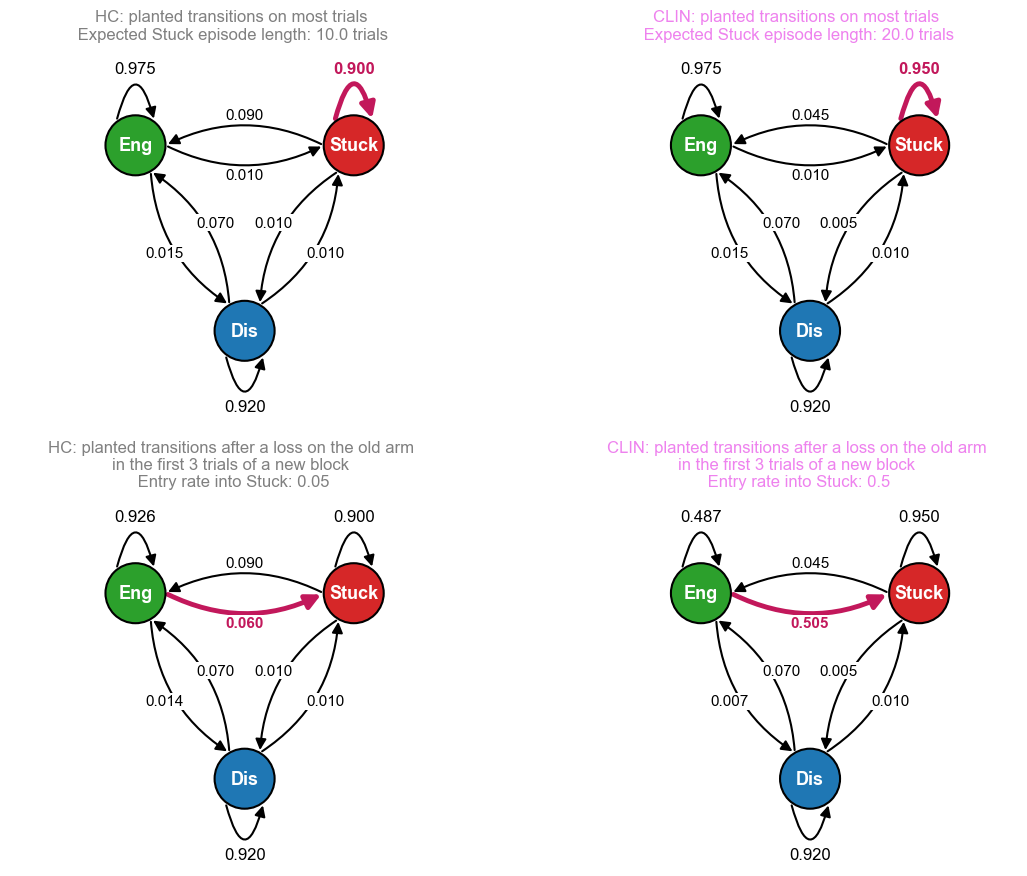

In [34]:
# PI_TRUE and A_HC were defined in Section 2.3a
#                   to: Eng    Stuck  Dis
A_CLIN = np.array([[0.975, 0.010, 0.015],    # same background entry into Stuck as HC ...
                   [0.045, 0.950, 0.005],    # ... but longer stuck episodes
                   [0.070, 0.010, 0.920]])

A_TRUE = {'HC': A_HC, 'CLIN': A_CLIN}

# Reversal-triggered entry: a loss in the first TRIGGER_WIN trials after a reversal can push an Engaged person into Stuck
TRIGGER     = {'HC': 0.05, 'CLIN': 0.50}      # probability per post-reversal loss
TRIGGER_WIN = 3                               # "post-reversal" = trials 0-2 of the new block (the first 3 outcomes after the arms swap)

dtimes= {}
for g in GROUPS:
    print(f'{g:>4} expected dwell times (trials): ' + ', '.join(f'{STATES[k]} {1/(1-A_TRUE[g][k,k]):.1f}' for k in range(3)) + f' | P(post-reversal loss -> Stuck) = {TRIGGER[g]:.2f}')
    dtimes[g] = [1/(1-A_TRUE[g][k,k]) for k in range(3)]
    
HIGHLIGHT = [[(1, 1)],    # row 1, on most trials: Stuck -> Stuck (0.90 in HC vs 0.95 in CLIN)
             [(0, 1)]]    # row 2, after a loss on the old arm: Engaged -> Stuck (the reversal trigger)

fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for c, g in enumerate(GROUPS):
    A_trig = A_TRUE[g].copy()
    A_trig[0] = (1 - TRIGGER[g]) * A_trig[0] + TRIGGER[g] * np.eye(3)[1]      # Engaged row right after a loss on the old arm
    for r, (M, lab) in enumerate([(A_TRUE[g], f'on most trials\n Expected Stuck episode length: {round(dtimes[g][1],0)} trials'), (A_trig, f'after a loss on the old arm\nin the first 3 trials of a new block\n Entry rate into Stuck: {TRIGGER[g]}')]):
        draw_hmm_diagram(ax[r, c], ['Eng', 'Stuck', 'Dis'], M, STATE_COLORS, fmt='{:.3f}', highlight=HIGHLIGHT[r])
        ax[r, c].set_title(f'{g}: planted transitions {lab}', fontsize=12, color=GROUP_COLORS[g], alpha = 1)
fig.tight_layout()

### 2.6 Simulate the cohort

We plant the ground truth. Both groups share the same policies, so any group difference must come from the dynamics. Each participant gets their own transition matrix, a small random nudge around their group's matrix, because people differ. On each trial, the simulated participant (`simulate_glmhmm_agent`) 
- draws its next hidden state from $A$, or from the reversal trigger of Section 2.5
- reads the previous outcome into $x_t$
- stays or switches with its state's logistic policy
- gets paid by the bandit

In [36]:
rng = np.random.default_rng(2026)      # the cohort gets its own generator

N_PER_GROUP = 30

def jitter_transitions(A, sd=0.02):
    # Individual differences: nudge each self-transition a little and keep every row summing to 1.
    A = A.copy()
    for k in range(len(A)):
        stay = np.clip(A[k, k] + rng.normal(0, sd), 0.5, 0.985)
        off = np.delete(A[k], k)
        A[k] = np.insert(off / off.sum() * (1 - stay), k, stay)
    return A

POST_REV = np.zeros(T_TRIALS, bool)
for rv in REVERSALS: 
    POST_REV[rv:rv + TRIGGER_WIN] = True        # trials whose outcome comes right after a reversal

def simulate_glmhmm_agent(A, W, trigger, pi, T):
    good = better_arm(T)
    choice, reward, state = np.zeros(T, int), np.zeros(T, int), np.zeros(T, int)
    state[0]  = rng.choice(len(pi), p=pi)
    choice[0] = rng.integers(2)                                # first choice: coin flip
    reward[0] = draw_reward(choice[0], 0, good)
    for t in range(1, T):
        p = A[state[t-1]]                                      # (1) hidden state evolves (Markov chain) ...
        if state[t-1] == 0 and POST_REV[t-1] and reward[t-1] == 0 and choice[t-1] != good[t-1]:
            p = (1 - trigger) * p + trigger * np.eye(3)[1]     #     ... unless a loss from the arm that just stopped paying pushes Engaged -> Stuck
        state[t] = rng.choice(len(pi), p=p)
        x = np.array([1.0, 2 * reward[t-1] - 1])               # (2) inputs: [bias, previous outcome +1/-1]
        stay = rng.random() < expit(W[state[t]] @ x)           # (3) state-specific logistic policy
        choice[t] = choice[t-1] if stay else 1 - choice[t-1]
        reward[t] = draw_reward(choice[t], t, good)            # (4) the bandit pays out
    return choice, reward, state

C, R, Z_true, group = [], [], [], []                            # choices, rewards, true states, group labels
for g in GROUPS:
    for i in range(N_PER_GROUP):
        c, r, z = simulate_glmhmm_agent(jitter_transitions(A_TRUE[g]), W_TRUE, TRIGGER[g], PI_TRUE, T_TRIALS)
        C.append(c)
        R.append(r)
        Z_true.append(z)
        group.append(g)
C, R, Z_true, group = np.array(C), np.array(R), np.array(Z_true), np.array(group)
N_SUBJ = len(C)

# a tidy trial-level table (one row per participant x trial), handy for pandas/seaborn
df = pd.DataFrame({'subject': np.repeat(np.arange(N_SUBJ), T_TRIALS),
                   'group': np.repeat(group, T_TRIALS),
                   'trial': np.tile(np.arange(T_TRIALS), N_SUBJ),
                   'choice': C.ravel(), 'reward': R.ravel(),
                   'correct': (C == better_arm()).ravel().astype(int),
                   'true_state': np.array(STATES)[Z_true.ravel()]})
df['group'] = pd.Categorical(df['group'], categories=GROUPS)    # explicit categorical coding (HC = reference)
df

,subject,group,trial,choice,reward,correct,true_state
0,0,HC,0,1,0,0,Engaged
1,0,HC,1,1,0,0,Engaged
2,0,HC,2,0,0,1,Engaged
3,0,HC,3,1,0,0,Engaged
4,0,HC,4,0,1,1,Engaged
...,...,...,...,...,...,...,...
17995,59,CLIN,295,1,1,1,Engaged
17996,59,CLIN,296,1,1,1,Engaged
17997,59,CLIN,297,1,1,1,Engaged
17998,59,CLIN,298,1,1,1,Engaged


### 2.7 Look at the raw data first

Always look at the raw data before modeling it.
Dots show choices: filled if rewarded, open if not. The black line is the better arm. The background shows the *true* hidden state, which is only known because we simulated the data.

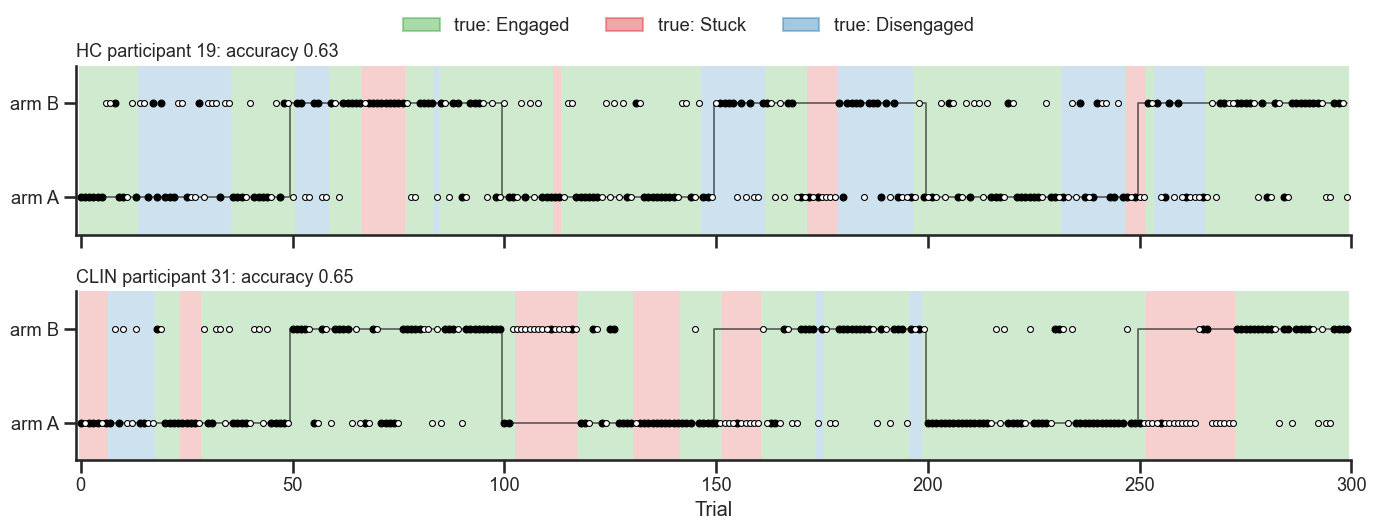

In [38]:
stuck_fo = (Z_true == 1).mean(1)                       # true fraction of trials in Stuck (simulation only)
EX = {}
for g in GROUPS:                                        # example = the participant closest to their group's median
    idx = np.where(group == g)[0]
    EX[g] = int(idx[np.argmin(np.abs(stuck_fo[idx] - np.median(stuck_fo[idx])))])
    
fig, ax = plt.subplots(2, 1, figsize=(14, 5.2), sharex=True)
for a, g in zip(ax, GROUPS):
    s = EX[g]
    plot_participant(a, s, Z_true[s], f'{g} participant {s}: accuracy {np.mean(C[s] == better_arm()):.2f}')
ax[1].set_xlabel('Trial')
state_legend(fig, prefix='true: ', y=1.04, alpha=0.4)
fig.tight_layout()

### 2.8 Model-agnostic summaries: a group difference

Model-agnostic summaries find the group difference but cannot explain it, which sets up the modeling. Three standard per-participant measures: accuracy (choosing the better arm), win-stay and lose-stay. We compare groups with Welch *t*-tests, using one helper function throughout the notebook.

=== Classic measures: CLIN vs HC (Welch t-test) ===
accuracy                 HC=  0.679  CLIN=  0.656  t= -1.47  p=0.1480  d=-0.38  n.s.
win_stay                 HC=  0.862  CLIN=  0.881  t= +1.50  p=0.1398  d=+0.39  n.s.
lose_stay                HC=  0.339  CLIN=  0.465  t= +4.25  p=1.0e-04  d=+1.10  ***
Significant (p < .05): lose_stay
=== P(new better arm), trials 1-10 after the swap: CLIN vs HC (Welch t-test) ===
p_new_1to10              HC=  0.649  CLIN=  0.541  t= -3.57  p=0.0009  d=-0.92  ***
Significant (p < .05): p_new_1to10


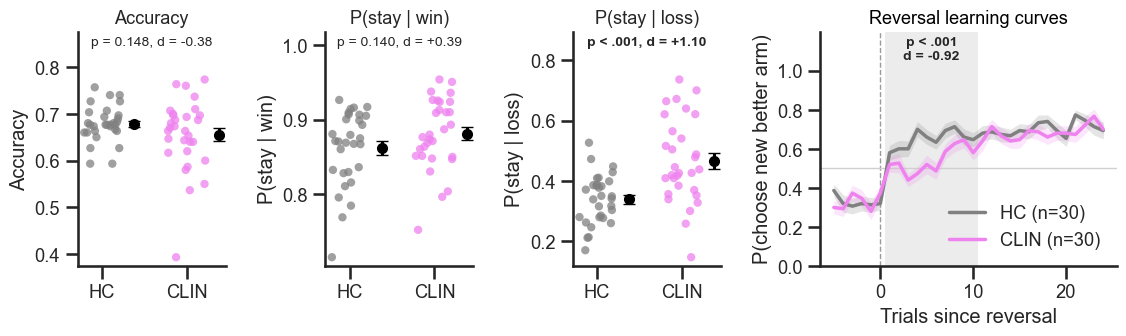

In [40]:
def group_ttests(data, measures, split=None, ref='HC', test='CLIN'):
    # Welch t-test (test vs ref) for each measure, optionally within each level of `split`. Returns a tidy table.
    rows = []
    for lev in ([None] if split is None else list(data[split].unique())):
        sub = data if lev is None else data[data[split] == lev]
        for m in measures:
            a, b = sub.loc[sub.group == test, m].dropna(), sub.loc[sub.group == ref, m].dropna()
            t, p = stats.ttest_ind(a, b, equal_var=False)
            d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)       # Cohen's d
            rows.append({'split': lev, 'measure': m, 'mean_' + ref: b.mean(), 'mean_' + test: a.mean(), 't': t, 'p': p, 'd': d})
    res = pd.DataFrame(rows)
    res['sig'] = pd.cut(res.p, [0, 0.001, 0.01, 0.05, 1], labels=['***', '**', '*', 'n.s.'])
    return res

def print_ttests(res, title):
    print(f'=== {title}: CLIN vs HC (Welch t-test) ===')
    for _, r in res.iterrows():
        lab = f'{r.split} | {r.measure}' if r.split is not None else r.measure
        p_str = f'{r.p:.4f}' if r.p >= 1e-4 else f'{r.p:.1e}'
        print(f'{lab:<24} HC={r.mean_HC:7.3f}  CLIN={r.mean_CLIN:7.3f}  t={r.t:+6.2f}  p={p_str}  d={r.d:+.2f}  {r.sig}')
    sig = res[res.p < 0.05]
    print('Significant (p < .05):', ', '.join((f'{s} | ' if s is not None else '') + m for s, m in zip(sig.split, sig.measure)) or 'none')

def strip_means(ax, data, y, palette=GROUP_COLORS):
    # Strip plot (jittered dots, one per participant) with the group mean ± SEM drawn to the right.
    sns.stripplot(data=data, x='group', y=y, order=GROUPS, hue='group', hue_order=GROUPS, palette=palette, jitter=0.22, size=6, alpha=0.75, legend=False, ax=ax, zorder=1)
    for i, g in enumerate(GROUPS):
        v = data.loc[data.group == g, y].dropna()
        ax.errorbar(i + 0.38, v.mean(), yerr=v.sem(), fmt='o', color='black', ms=7, capsize=4, zorder=3)
    ax.set_xlabel('')

def reversal_curves(weight_fn=None):
    # Rows: one per (participant, reversal); P(choose the NEW better arm) at each lag.
    # weight_fn(s, rv) gives each reversal a weight w (default 1). Section 4.3b uses posterior probabilities as weights.
    WIN = np.arange(-5, 25)          # trials relative to each reversal
    rows = []
    for s in range(N_SUBJ):
        for rv in REVERSALS:
            w = 1.0 if weight_fn is None else weight_fn(s, rv)
            new_good = better_arm()[rv]
            rows.append(pd.DataFrame({'subject': s, 'group': group[s], 'reversal': rv, 'lag': WIN, 'w': w, 'p_new': (C[s, rv + WIN] == new_good).astype(float)}))
    return pd.concat(rows, ignore_index=True)

# per-participant classic measures (loop + row accumulation)
rows = []
for s in range(N_SUBJ):
    stay = C[s, 1:] == C[s, :-1]; prev_r = R[s, :-1]
    rows.append({'subject': s, 'group': group[s], 'accuracy': np.mean(C[s] == better_arm()), 'win_stay': stay[prev_r == 1].mean(), 'lose_stay': stay[prev_r == 0].mean()})
classic = pd.DataFrame(rows)
classic['group'] = pd.Categorical(classic['group'], categories=GROUPS)
res_classic = group_ttests(classic, ['accuracy', 'win_stay', 'lose_stay'])              # Welch t-tests, CLIN vs HC

rc = reversal_curves()
# per participant: fraction of choices of the new better arm in trials 1-10 after the swap, averaged over the 5 reversals
adapt = rc[rc.lag.between(1, 10)].groupby(['subject', 'group']).p_new.mean().rename('p_new_1to10').reset_index()
adapt['group'] = pd.Categorical(adapt['group'], categories=GROUPS)
res_adapt = group_ttests(adapt, ['p_new_1to10'])                       # kept: Section 4.3b shows these curves again

fig, ax = plt.subplots(1, 4, figsize=(11.5, 3.6), gridspec_kw={'width_ratios': [1,1,1,2]})
for a, m, lab in zip(ax, ['accuracy', 'win_stay', 'lose_stay'], ['Accuracy', 'P(stay | win)', 'P(stay | loss)']):
    strip_means(a, classic, m)
    annotate_test(a, res_classic[res_classic.measure == m].iloc[0])                    # p and Cohen's d on top, as in Section 4.1
    a.set_ylabel(lab)
    a.set_title(lab, fontsize=13)
plot_reversal(ax[3], rc, 'Reversal learning curves')
annotate_window(ax[3], 1, 10, res_adapt.iloc[0], headroom=0.2)              # grey = trials 1-10, the window the test uses
ax[3].set_yticks(np.arange(0, 1.01, 0.2))                                   # headroom for the text, ticks only up to 1

fig.tight_layout()
print_ttests(res_classic, 'Classic measures')
print_ttests(res_adapt, 'P(new better arm), trials 1-10 after the swap')

**Note**: 
- CLIN stays after losses more often. Its accuracy is only slightly lower, and the difference is not significant; win-stay does not differ.
- CLIN moves to the new arm more slowly after reversals. For the test, we take each participant's fraction of choices of the new better arm in trials $1$ to $10$ after the swap (trial $0$ is the first trial of the new block), averaged over the five reversals, and compare the groups. The curves and the test do not say *why* CLIN is slower: a learning deficit and stuck episodes both predict this.

### 2.9 Sanity check: known states recover the planted policies (Optional)

Because the data are simulated, we can run the known-states version and compare the fitted weights with the truth. With a single ±1 input, each regression has two weights for two conditions (after a loss, after a win). So its fitted P(stay) matches the fraction of stays actually observed in that state after a loss and after a win, almost exactly.

**Note**: The figure shows the result in two ways: as policies (P(stay) after a loss and after a win), and as points in weight space $(w_0, w_1)$.

X: (60, 299, 2) (participants, trials, inputs) | Y: (60, 299)
            w0 fitted  w1 fitted  w0 true  w1 true
Engaged          0.49       2.03      0.5      2.0
Stuck            3.05      -0.05      3.0      0.0
Disengaged       0.00       0.01      0.0      0.0


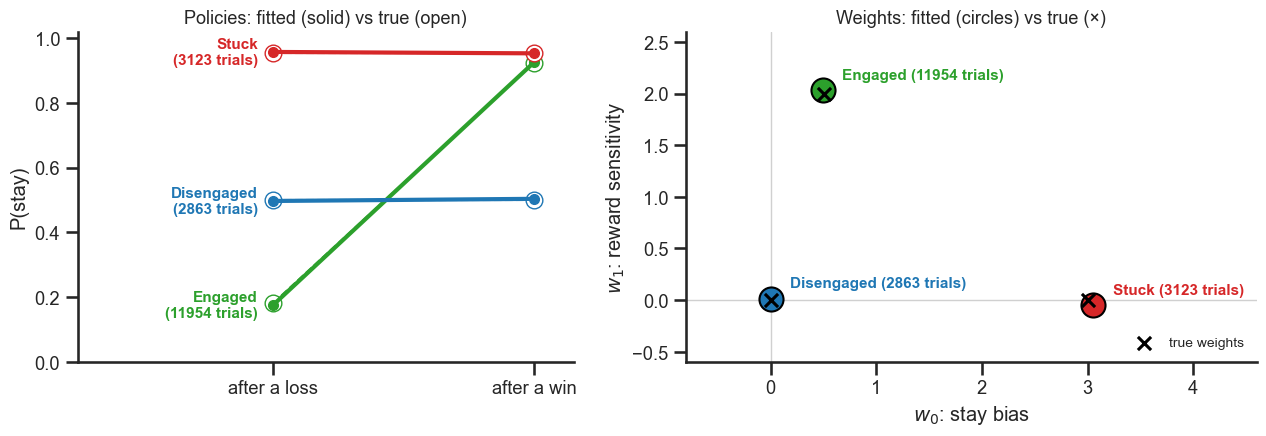

In [43]:
def fit_weights(X, Y, weights, w0, l2=1.0):
    # Weighted logistic regression of Y on X. Each trial counts with its weight (1/0 = known state, or gamma_t(k) in EM).
    # A small L2 penalty (a Gaussian prior on the weights) keeps the estimates finite.
    Xf, Yf, gf = X.reshape(-1, X.shape[-1]), Y.ravel(), weights.ravel()
    def objective(w):
        u = Xf @ w
        nll = -np.sum(gf * (Yf * -np.logaddexp(0, -u) + (1 - Yf) * -np.logaddexp(0, u))) + 0.5 * l2 * w @ w
        grad = -Xf.T @ (gf * (Yf - expit(u))) + l2 * w
        return nll, grad
    return optimize.minimize(objective, w0, jac=True, method='L-BFGS-B').x

X, Y = build_design(C, R)                 # the whole cohort, in the form the model sees.
Z_emit = Z_true[:, 1:]                    # true states aligned with the observations (trial 2 onward)
print('X:', X.shape, '(participants, trials, inputs) | Y:', Y.shape)

# one logistic regression per state, using only that state's trials (weights 1 inside the state, 0 outside)
W_known = np.array([fit_weights(X, Y, (Z_emit == k).astype(float), np.zeros(2)) for k in range(3)])
print(pd.DataFrame(np.c_[W_known, W_TRUE], index=STATES, columns=['w0 fitted', 'w1 fitted', 'w0 true', 'w1 true']).round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})
plot_policies_and_weights(ax, W_known, [f'{STATES[k]}\n({np.sum(Z_emit == k)} trials)' for k in range(3)])
fig.tight_layout()

## 3. Fitting the GLM-HMM and checking it against the truth

### 3.1 The Expectation-Maximization (EM) algorithm

`fit_glmhmm` puts together pieces we have already built.

**(0) Initialize** 

EM needs a starting guess for $\lambda = (\pi, A, W)$.
- **Emission weights $W$:** fit one logistic regression to *all* trials, as if there were a single state (`fit_weights` with weight 1 on every trial). Each state starts from these average weights plus random noise (sd 1), so the states begin slightly different and EM can pull them apart.
- **Transitions $A$:** "sticky". Each state stays put with probability 0.95 or more, and the rest is split at random among the other moves.
- **Initial distribution $\pi$:** uniform, $1/K$ for each state.

**(1) E-step (`forward_backward`): infer the hidden states under the current parameters**
- **Emissions:** `log_emission` gives every trial's emission probability under each state. It is the log of `emission_probs`:
  $\log B_{t,k} = y_t \log \sigma(w_k \cdot x_t) + (1-y_t) \log\big(1-\sigma(w_k \cdot x_t)\big)$.
- **Forward pass**: $\alpha_t(k)$, trial by trial. To avoid numbers underflowing, we normalize $\alpha_t$ on every trial and keep the normalizers $c_t$. As a by-product we get the log-likelihood, $\log P(\text{data}) = \sum_t \log c_t$. This is the number EM tries to increase, and the one we watch to decide when to stop.
- **Backward pass**: $\beta_t(k)$, from the last trial back to the first.
- **Combine** the two passes into:
  - $\gamma_t(k) = P(z_t = k \mid \text{data})$: soft state labels.
  - $\xi_t(i, j) = P(z_t = i,\ z_{t+1} = j \mid \text{data})$: soft moves. Summed over trials and participants, they give the expected transition counts $N_{ij} = \sum_{n,t} \xi^{(n)}_t(i, j)$.

**(2) M-step: re-estimate the parameters as if the soft labels were true**
- $\pi_k \propto \sum_n \gamma^{(n)}_1(k)$: how often each state is the first state.
- $A_{ij} \propto N_{ij} + 1$: expected $i \to j$ moves divided by all expected moves out of $i$. The $+1$ is a small prior that keeps probabilities away from exactly 0.
- $w_k$ = `fit_weights` with weights $\gamma_t(k)$: one weighted logistic regression per state, started from the current $w_k$.

The M-step uses the *soft* posteriors $\gamma$ and $\xi$, not a single decoded path, so every trial counts toward every state in proportion to its posterior. 

**(3) Repeat steps 1–2 with the new parameters** 

The log-likelihood never goes down. Strictly, because of the small priors, it is the penalized log-likelihood that never goes down, but the difference is negligible here. We stop when it improves by less than `tol`, or after `n_iter` iterations. `fit_glmhmm` returns the final $W$, $A$, $\pi$ and the log-likelihood at every iteration.

**Note**: Participants are separate sequences. We pool participants to learn *one* set of parameters, but we never glue their trials into one long sequence. `X` and `Y` keep a participant axis (participants × trials), and the forward and backward passes run along each participant's trial axis separately. Every participant starts from $\pi$ on their own first trial, and $\xi$ only counts moves between two consecutive trials of the same participant. So the model never "moves" from the last trial of participant $n$ to the first trial of participant $n+1$, and $A$ is learned only from real, within-person transitions.

**Note**: With `fix_W=True`, EM skips the $W$ update and re-estimates only $\pi$ and $A$.

**Note**: `viterbi` is not part of EM: it runs only after fitting, to decode the single most likely state path.

In [46]:
def log_emission(X, Y, W):
    # log of emission_probs (Section 2.3b): log P(y_t | z_t = k, x_t) for every participant n, trial t, state k -> (N, L, K).
    U = X @ W.T                                                  # linear predictor w_k . x_t
    log_p1 = -np.logaddexp(0, -U)                                # log sigma(U)      (numerically stable)
    log_p0 = -np.logaddexp(0,  U)                                # log (1 - sigma(U))
    return Y[..., None] * log_p1 + (1 - Y[..., None]) * log_p0

def forward_backward(logE, pi, A, per_trial=False):
    # Scaled forward-backward, vectorized over participants. Returns gamma (N,L,K), xi (K,K), total log-likelihood.
    # Each participant is its own sequence: both passes run along the trial axis only, never from one participant into the next.
    # per_trial=True returns xi for every participant and pair of neighbouring trials, (N, L-1, K, K), instead of the summed (K, K) counts.
    N, L, K = logE.shape
    m = logE.max(-1, keepdims=True)
    lik = np.exp(logE - m)                                       # emission likelihoods (rescaled, safe to exponentiate)
    alpha, c = np.zeros((N, L, K)), np.zeros((N, L))
    a = pi * lik[:, 0]
    c[:, 0] = a.sum(-1); alpha[:, 0] = a / c[:, 0, None]
    for t in range(1, L):                                        # ---- forward pass ----
        a = (alpha[:, t-1] @ A) * lik[:, t]                      # sum over previous states, then emit
        c[:, t] = a.sum(-1); alpha[:, t] = a / c[:, t, None]     # normalize every trial (store the normalizer)
    beta = np.ones((N, L, K))
    for t in range(L - 2, -1, -1):                               # ---- backward pass ----
        beta[:, t] = ((lik[:, t+1] * beta[:, t+1]) @ A.T) / c[:, t+1, None]
    gamma = alpha * beta                                         # posterior P(z_t = k | all data)
    xi_t = np.einsum('ntk,ntj->ntkj', alpha[:, :-1], lik[:, 1:] * beta[:, 1:] / c[:, 1:, None]) * A   # xi_t(i,j) = P(z_t=i, z_t+1=j | data), within each participant
    xi = xi_t.sum((0, 1))                                        # expected i->j counts (summed over trials and participants)
    loglik = np.log(c).sum() + m.sum()
    return gamma, (xi_t if per_trial else xi), loglik

def fit_glmhmm(X, Y, K, n_iter=200, tol=1e-4, seed=0, W_init=None, A_init=None, fix_W=False):
    # Initialization: a 1-state GLM plus noise; 'sticky' transitions.
    rs = np.random.default_rng(seed)
    if W_init is None:
        w_glm = fit_weights(X, Y, np.ones_like(Y), np.zeros(X.shape[-1]))
        W = w_glm + rs.normal(0, 1.0, (K, X.shape[-1]))
    else:
        W = W_init.copy()
    A = 0.95 * np.eye(K) + 0.05 * rs.dirichlet(np.ones(K), K) if A_init is None else A_init.copy()
    A = A / A.sum(1, keepdims=True)
    pi = np.ones(K) / K
    lls = []
    for it in range(n_iter):
        gamma, xi, ll = forward_backward(log_emission(X, Y, W), pi, A)      # E-step
        lls.append(ll)
        if it > 0 and lls[-1] - lls[-2] < tol: 
            break                         # converged
        pi = gamma[:, 0].mean(0) + 1e-8; pi /= pi.sum()                      # M-step: initial distribution
        A = (xi + 1.0) / (xi + 1.0).sum(1, keepdims=True)                    # M-step: transitions
        if not fix_W:
            W = np.array([fit_weights(X, Y, gamma[..., k], W[k]) for k in range(K)])   # M-step: emissions (Section 2.4c, weights = gamma)
    return {'W': W, 'A': A, 'pi': pi, 'lls': np.array(lls), 'loglik': lls[-1]}

def viterbi(logE, pi, A):
    # Most likely state path for every participant (log space, vectorized). Returns (N, L) state indices.
    N, L, K = logE.shape
    logA, back = np.log(A), np.zeros((N, L, K), int)
    delta = np.log(pi) + logE[:, 0]
    for t in range(1, L):
        scores = delta[:, :, None] + logA[None]                  # (N, from, to)
        back[:, t] = scores.argmax(1)
        delta = scores.max(1) + logE[:, t]
    z = np.zeros((N, L), int); z[:, -1] = delta.argmax(-1)
    for t in range(L - 1, 0, -1):
        z[:, t-1] = back[np.arange(N), t, z[:, t]]               # backtrack
    return z

### 3.2 Fit a 3-state model to the pooled cohort

We fit one model to all $60$ participants, so the states mean the same thing for everyone, and then ask how each participant utilizes them dynamically. This has a cost: the groups can then differ only in how they *use* the states ($\pi$, $A$) in terms of their dynamics, not in what the states *do* ($W$). If CLIN's engaged choices followed feedback less, the model could not give CLIN its own Engaged state; it would describe CLIN as spending more time in the other states instead.

EM can get stuck in local optima, so we run 5 random restarts and keep the best one.

5 restarts in 8 s | final log-likelihoods: [-7912.838, -7912.838, -7912.838, -7912.835, -7912.838]


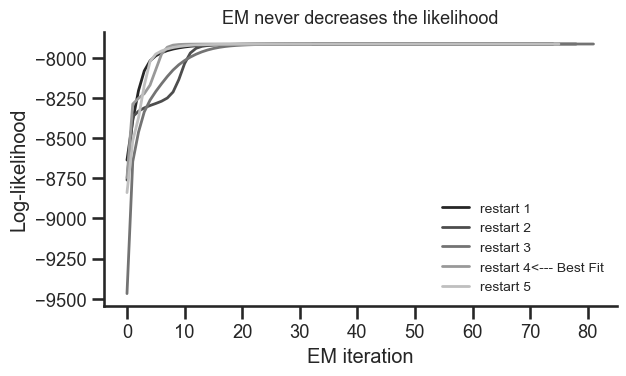

In [48]:
K = 3 # <---- Hyperparameter, we want to find three states

t0 = time.time()
fits = [fit_glmhmm(X, Y, K=K, seed=s) for s in range(5)]
best, best_i = max(fits, key=lambda f: f['loglik']), max(range(len(fits)), key=lambda i: fits[i]['loglik'])
print(f'5 restarts in {time.time() - t0:.0f} s | final log-likelihoods:', [round(float(f['loglik']), 3) for f in fits])

fig, ax = plt.subplots(figsize=(6.5, 4))
for i, f in enumerate(fits):
    ax.plot(f['lls'], lw=2, color=str(0.15 + 0.15 * i), label=f'restart {i+1}<--- Best Fit' if i == best_i else f'restart {i+1}')
ax.set_xlabel('EM iteration')
ax.set_ylabel('Log-likelihood')
ax.set_title('EM never decreases the likelihood', fontsize=13)
ax.legend(frameon=False, fontsize=10)
fig.tight_layout()

### 3.3 Inspect and name the states

EM hands back numbered states $(0, 1, 2)$ with no names, and the numbering is arbitrary: another restart may number the same states differently (**label switching**). So we name the states by what they do, using only their emission weights:

1. **Engaged** = the state with the **largest reward weight** $w_1$. It is the only state whose choices follow wins and losses.
2. **Stuck** = of the two remaining states, the one with the **largest stay bias** $w_0$. It stays regardless of reward.
3. **Disengaged** = the state that is left. Both weights are near 0, so its choices are close to coin flips.

The table lists each named state's fitted weights, choice probabilities, probability of remaining in the state ($A_{kk}$) and initial probability ($\pi_k$), next to the true weights. 

**Note**: With real data this rule is a choice the researchers make and report. It should be checked across restarts and folds, and it may need rethinking if $K$ changes.

Label switching: the same three states come back in a different order in different restarts
  restart 1: stay bias:          w0 of EM states 0, 1, 2 = [0.07 2.99 0.45]  
             reward sensitivity: w1 of EM states 0, 1, 2 = [0.07 0.03 2.02] 

  restart 2: stay bias:          w0 of EM states 0, 1, 2 = [0.45 0.07 2.99]  
             reward sensitivity: w1 of EM states 0, 1, 2 = [2.02 0.07 0.03] 

  restart 3: stay bias:          w0 of EM states 0, 1, 2 = [0.07 2.99 0.45]  
             reward sensitivity: w1 of EM states 0, 1, 2 = [0.07 0.03 2.02] 

  restart 4: stay bias:          w0 of EM states 0, 1, 2 = [2.99 0.07 0.45] <--- Best Fit 
             reward sensitivity: w1 of EM states 0, 1, 2 = [0.03 0.07 2.02] 

  restart 5: stay bias:          w0 of EM states 0, 1, 2 = [0.45 2.99 0.07]  
             reward sensitivity: w1 of EM states 0, 1, 2 = [2.02 0.03 0.07] 


Naming rule applied to the best fit:
Engaged    = EM state 2   (largest reward weight, w1 = 2.02)
Stuck      = EM 

,EM state,w0 (stay bias),w1 (reward sensitivity),P(stay|win),P(stay|loss),P(remain),initial pi,w0 true,w1 true
Engaged,2,0.445156,2.022763,0.921862,0.171135,0.969654,0.922594,0.5,2.0
Stuck,0,2.990772,0.029996,0.953504,0.950770,0.936486,0.077356,3.0,0.0
Disengaged,1,0.068985,0.066841,0.533904,0.500536,0.938164,0.000050,0.0,0.0


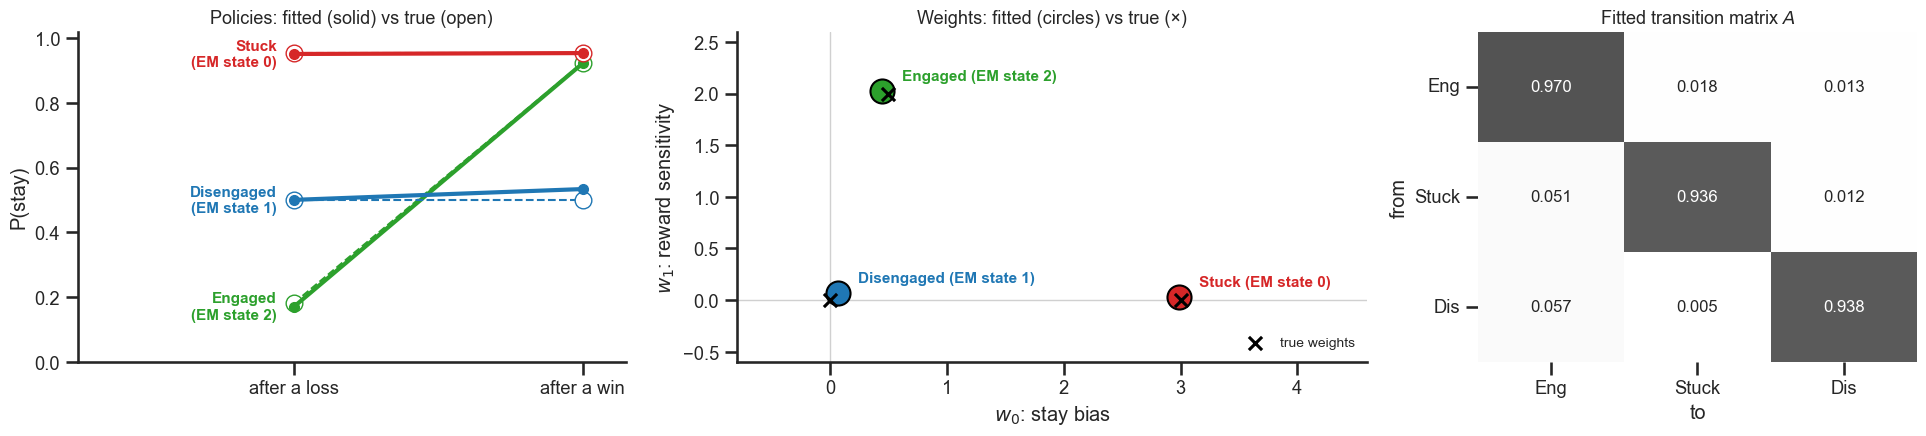

In [50]:
print('Label switching: the same three states come back in a different order in different restarts')
for i, f in enumerate(fits):
    print(f'  restart {i + 1}: stay bias:          w0 of EM states 0, 1, 2 =', np.round(f['W'][:, 0], 2), '<--- Best Fit' if i == best_i else '',
          f'\n             reward sensitivity: w1 of EM states 0, 1, 2 =', np.round(f['W'][:, 1], 2), f'\n')

def name_states(W, verbose=False):
    # Return the fitted state indices in the order [Engaged, Stuck, Disengaged], using only the weights.
    eng = int(np.argmax(W[:, 1]))                                   # step 1: largest reward weight
    rest = [k for k in range(len(W)) if k != eng]
    stuck = rest[int(np.argmax(W[rest, 0]))]                        # step 2: largest stay bias among the rest
    dis = [k for k in rest if k != stuck][0]                        # step 3: the remaining state
    if verbose:
        print(f'Engaged    = EM state {eng}   (largest reward weight, w1 = {W[eng, 1]:.2f})')
        print(f'Stuck      = EM state {stuck}   (largest stay bias of the rest, w0 = {W[stuck, 0]:.2f})')
        print(f'Disengaged = EM state {dis}   (left over; w0 = {W[dis, 0]:.2f}, w1 = {W[dis, 1]:.2f})')
    return [eng, stuck, dis]

raw_W, raw_A, raw_pi = best['W'], best['A'], best['pi']             # the best fit, in EM's own (arbitrary) order
print('\nNaming rule applied to the best fit:')
order = name_states(raw_W, verbose=True)
name_of = {order[i]: STATES[i] for i in range(3)}                  # EM state index -> name
W_hat, A_hat, pi_hat = raw_W[order], raw_A[np.ix_(order, order)], raw_pi[order]   # reorder into named order

fig, ax = plt.subplots(1, 3, figsize=(19.5, 4.6), gridspec_kw={'width_ratios': [1, 1.15, 0.8]})
plot_policies_and_weights(ax[:2], W_hat, [f'{STATES[i]}\n(EM state {order[i]})' for i in range(3)])
plot_matrix(ax[2], A_hat, ['Eng', 'Stuck', 'Dis'], title='Fitted transition matrix $A$')
fig.tight_layout()

pd.DataFrame({'EM state': order, 'w0 (stay bias)': W_hat[:, 0], 'w1 (reward sensitivity)': W_hat[:, 1],
                    'P(stay|win)': expit(W_hat[:, 0] + W_hat[:, 1]), 'P(stay|loss)': expit(W_hat[:, 0] - W_hat[:, 1]),
                    'P(remain)': np.diag(A_hat), 'initial pi': pi_hat, 'w0 true': W_TRUE[:, 0], 'w1 true': W_TRUE[:, 1]},
                   index=STATES)

### 3.4 Soft decoding: posterior state and transition probabilities

With the fitted $\pi$, $A$ and $W$, forward–backward gives every participant's posteriors $\gamma$ and $\xi$ (Section 2.4b), given *all* of that participant's choices. Each turns into per-participant metrics:

- From $\gamma_t(k) = P(z_t = k \mid \text{data})$: the **soft fractional occupancy** (how much), $FO_k = \frac{1}{T} \sum_t \gamma_t(k)$, with $T = 299$ modeled trials.
- From $\xi_t(i, j)$, summed over trials into expected move counts $N_{ij} = \sum_t \xi_t(i, j)$:
  - the **soft self-transition rate** (how long), $p_{kk} = N_{kk} / \sum_j N_{kj}$: this participant's own version of $A_{kk}$;
  - the **soft entry rate** (how often into $k$), $\text{entry}_k = \frac{50}{T-1}\sum_{i\neq k} N_{ik}$: expected switches into $k$ per 50 trials;
  - the **soft switching rate** (how often, any state), $SR = \sum_k \text{entry}_k$: expected switches of any kind per 50 trials.

**Note**:
- Where one $\gamma$ line is close to 1, the model is confident. Lines in between mark behavior that fits more than one state: mostly at the edges of episodes, after wins (where Engaged and Stuck behave alike), and in noisy stretches that fit both Engaged and Disengaged.
- Switch spikes sit where the true strip changes color. Very short true episodes leave little trace in behavior, so some true switches get no spike. Entry and switching rates are counts, so these missed switches pull them below the truth. Self-transition rates stay close to the truth: a few missed switches barely move a number near $1$.

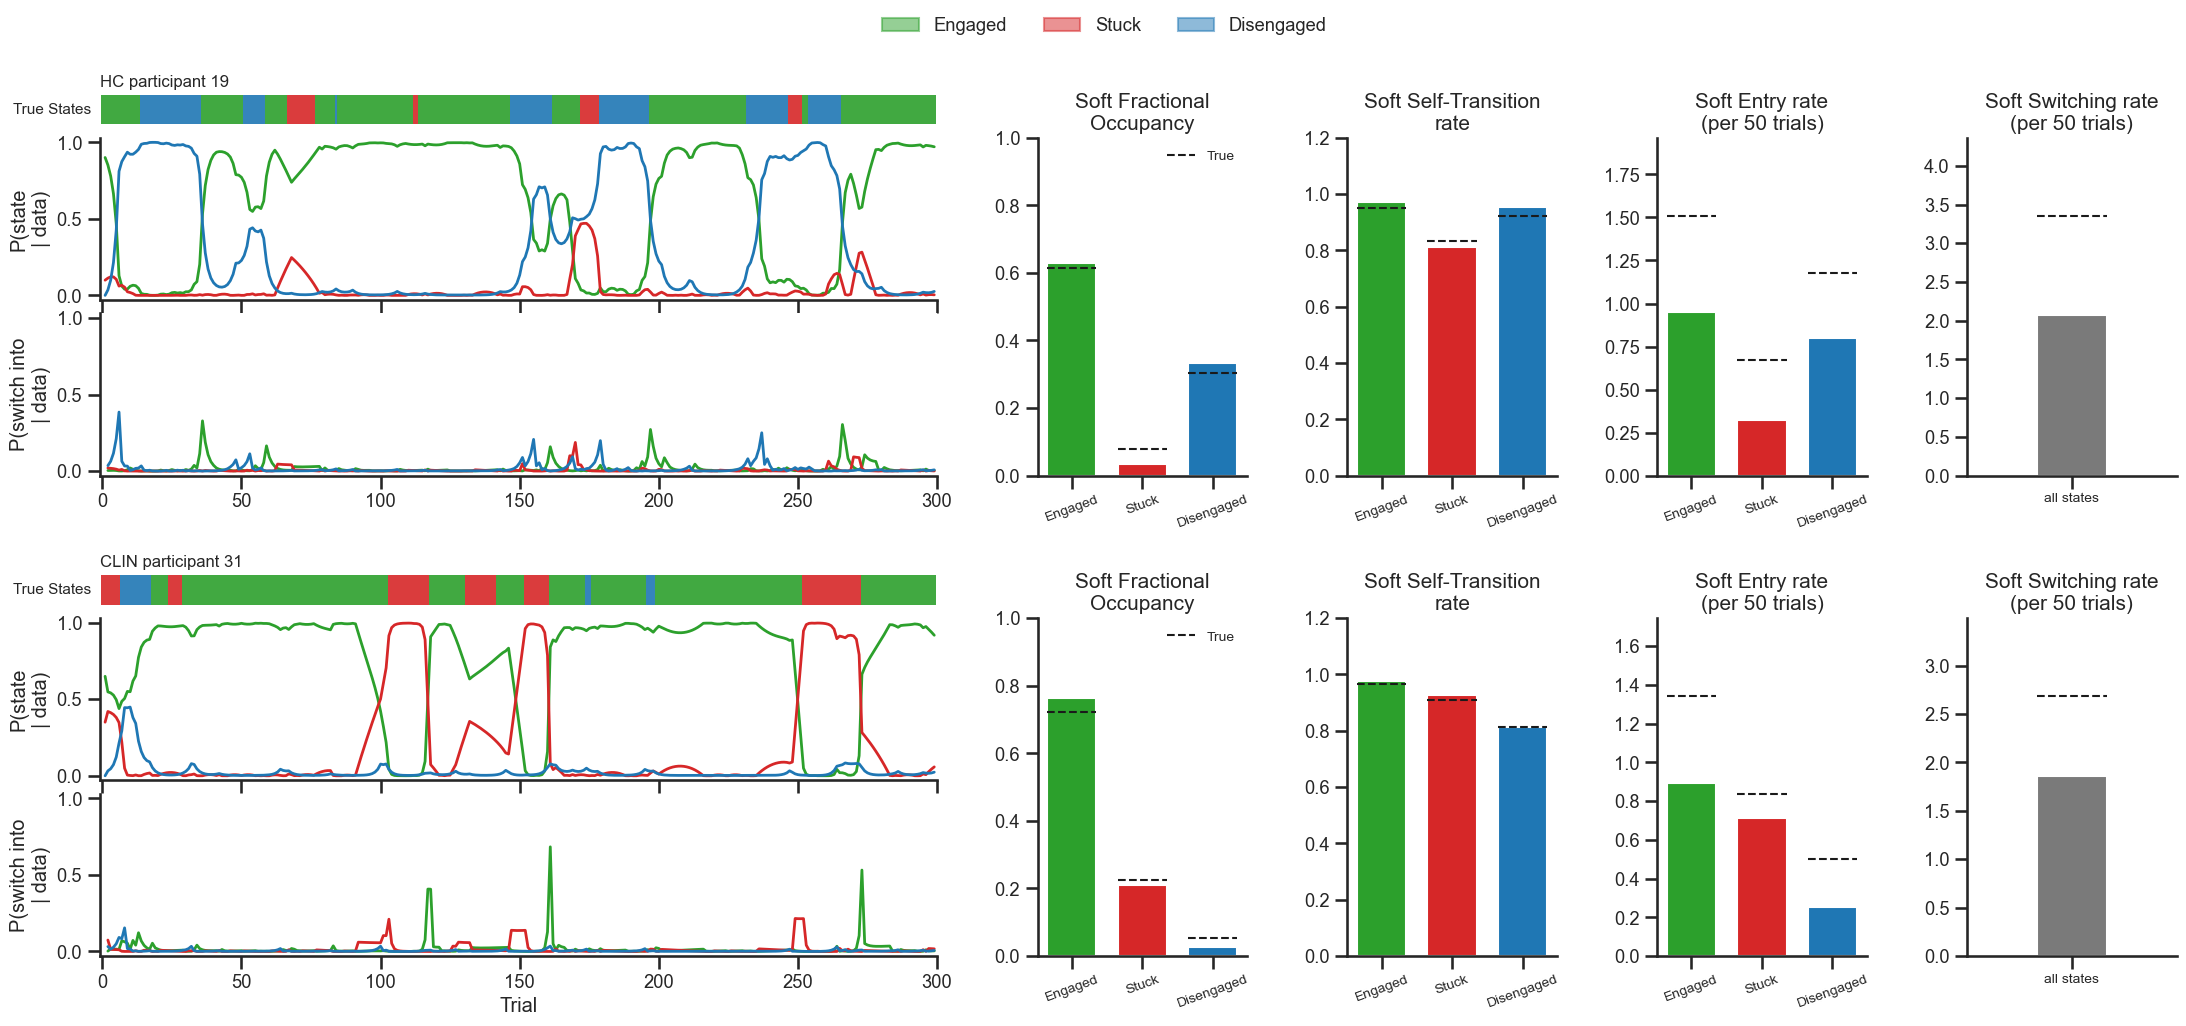

In [52]:
gamma_all, _, _ = forward_backward(log_emission(X, Y, W_hat), pi_hat, A_hat)                 # posteriors with named states
_, xi_all, _ = forward_backward(log_emission(X, Y, W_hat), pi_hat, A_hat, per_trial=True)    # xi_all[n, t, i, j] = P(z_t = i, z_t+1 = j | data)
into = xi_all.sum(2) - np.diagonal(xi_all, axis1=2, axis2=3)                                 # into[n, t, k] = P(switch into state k on this move | data)

fig, rows = participant_grid(4, n_traces=2)
for g, s_, (a_post, a_sw), (a_fo, a_st, a_en, a_sr) in rows:
    plot_state_traces(a_post, np.arange(1, T_TRIALS), gamma_all[s_], 'P(state\n| data)')      # gamma index t-1 = trial t
    plot_state_traces(a_sw, np.arange(2, T_TRIALS), into[s_], 'P(switch into\n| data)')       # plotted at the trial the move arrives
    a_post.set_xticklabels([])
    soft, true = soft_metrics(gamma_all[s_], xi_all[s_]), path_metrics(Z_emit[s_])
    metric_bars(a_fo, soft['FO'], true['FO'], 'Soft Fractional\nOccupancy', top=1, legend=True)
    metric_bars(a_st, soft['p_self'], true['p_self'], 'Soft Self-Transition\nrate')
    metric_bars(a_en, soft['entry'], true['entry'], 'Soft Entry rate\n(per 50 trials)', top=None)
    sr_bar(a_sr, soft['entry'].sum(), true['entry'].sum(), 'Soft Switching rate\n(per 50 trials)')

### 3.5 Hard decoding: the Viterbi path

Sometimes we want a single label per trial: to draw one state sequence, or to count episodes and measure their length directly. `viterbi` (Section 2.4b, in log space) gives the single most likely path of states for each participant. The hard metrics are the soft metrics of Section 3.4 computed on a "posterior" that puts probability $1$ on that path (`onehot_posteriors`): **fractional occupancy**, the **appearance rate** $AR_k$ (decoded switches into $k$ per 50 trials) and the **switching rate**. On a hard path we can count episode lengths directly, so the self-transition rate is replaced by the **dwell time**, the mean length of the decoded episodes of $k$:

$$DT_k = \frac{1}{E_k}\sum_{e=1}^{E_k} d_{k,e} = \frac{T \cdot FO_k}{E_k}$$

where $E_k$ is the number of decoded episodes of $k$ and $d_{k,e}$ the length of episode $e$. On average $DT_k \approx 1/(1-p_{kk})$; episodes cut by the start or end of the session count as shorter, and a participant who never leaves a state gets $DT_k = T$.

**Why Viterbi misses short episodes.** Viterbi has to commit to one path. A short episode costs that path two unlikely transitions (one in, one out), so it enters the path only if the choices inside it outweigh that cost. Weakly supported or very short episodes are dropped, and their trials go to a neighboring episode. The posteriors of Section 3.4 keep these episodes in expectation, as partial switches.

**Note**: Every hard metric inherits this, in both example participants.
- FO overstates Engaged. The HC participant's Stuck episodes are all short, and none survives decoding; the CLIN participant keeps its longest Stuck episodes but loses the shorter ones. The soft FO of Section 3.4 is closer to the truth for both.
- Dwell times come out too long, because the two neighbors of a dropped episode merge into one longer episode. Appearance rates come out too low, because each dropped episode removes two switches.
- The decoded switching rate is about half the soft one, and both are below the truth: the soft rate adds up the switch probability on every move, so partial switches count.
- Where $\gamma$ is close to $1$, Viterbi picks that state. On uncertain trials it can disagree with the most probable state, because it picks the best *path*, not the best state trial by trial.

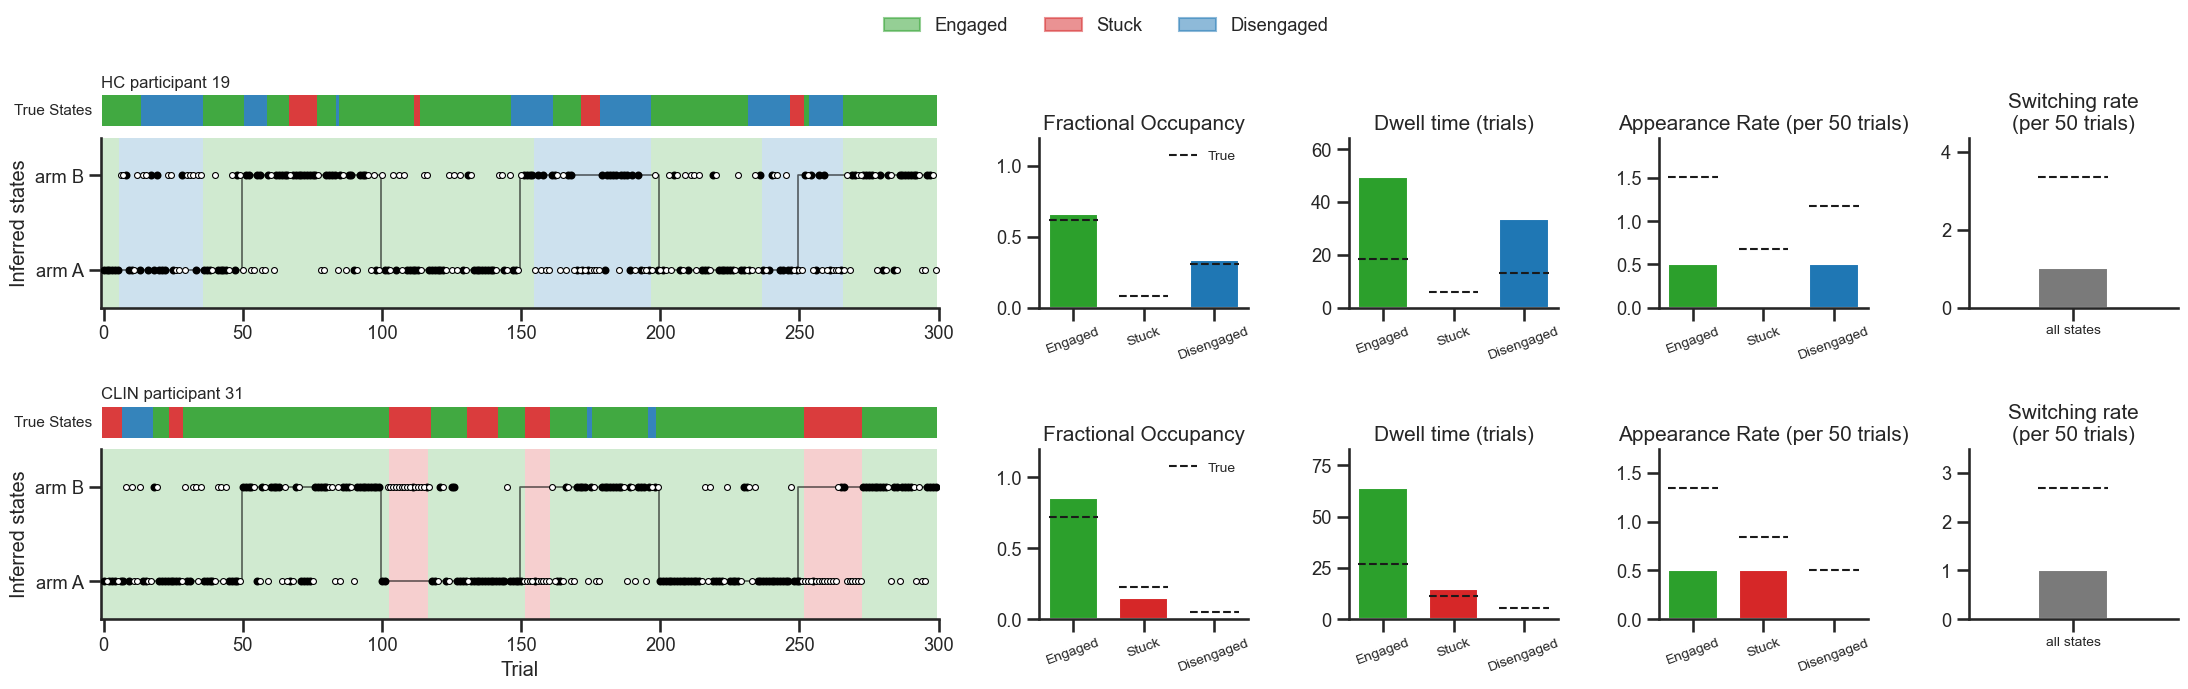

In [54]:
Z_hat = viterbi(log_emission(X, Y, W_hat), pi_hat, A_hat)       # most likely named-state path, every participant

fig, rows = participant_grid(4)
for g, s_, a_dec, (a_fo, a_dt, a_en, a_sr) in rows:
    plot_participant(a_dec, s_, np.r_[Z_hat[s_, 0], Z_hat[s_]])                      # trial 1 has no emission: reuse trial 2's state
    a_dec.set_ylabel('Inferred states')
    hard, true = path_metrics(Z_hat[s_]), path_metrics(Z_emit[s_])                # the same metrics, decoded path vs true path
    metric_bars(a_fo, hard['FO'], true['FO'], 'Fractional Occupancy', legend=True)
    metric_bars(a_dt, hard['DT'], true['DT'], 'Dwell time (trials)', top=None)
    metric_bars(a_en, hard['entry'], true['entry'], 'Appearance Rate (per 50 trials)', top=None)
    sr_bar(a_sr, hard['entry'].sum(), true['entry'].sum(), 'Switching rate\n(per 50 trials)')

### 3.6 Validation: state recovery and the number of states

**State recovery (left).** Because we planted the truth, we can check the decoding directly with a **confusion matrix**. With real data you would instead check held-out prediction, stability across restarts and subsets, and relationships with independent measures.

**How many states? (right).** We assumed $3$ states; **cross-validation** checks whether the data support that choice. Adding states always increases the likelihood of the *training* data, so we test on **held-out participants**. We split the $60$ participants into $5$ folds of $12$ ($6$ HC and $6$ CLIN each). For each $K$ from $1$ to $5$ and each fold, we fit a fresh $K$-state model on the other $48$ participants, freeze it, and compute the log-likelihood of the $12$ held-out participants' choices with the forward algorithm, which sums over their unknown state paths. We report the gain over a $1$-state model (plain logistic regression) on the same fold, in **bits per trial**. The best $K$ is where the gain stops growing.

Cross-validation done in 76 s
     mean     sem
K                
1  0.0000  0.0000
2  0.0557  0.0042
3  0.0824  0.0037
4  0.0820  0.0037
5  0.0818  0.0038


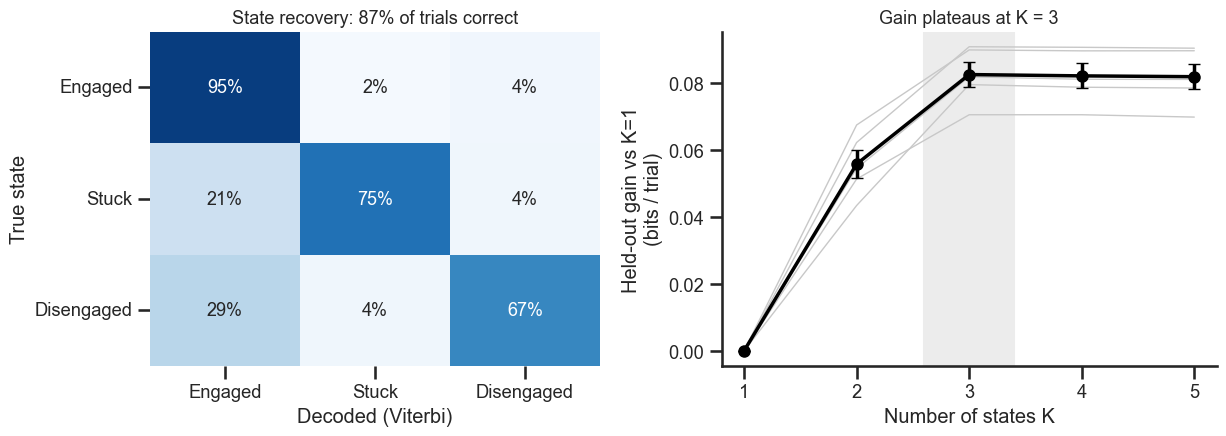

In [56]:
# (left) state recovery: Z_hat (the decoded states) was computed in Section 3.5
conf = np.array([[np.sum((Z_emit == i) & (Z_hat == j)) for j in range(3)] for i in range(3)])
conf_pct = conf / conf.sum(1, keepdims=True)

# (right) cross-validation over the number of states K, on held-out participants
fold_rng = np.random.default_rng(0)                       # own generator for the folds
folds = np.zeros(N_SUBJ, int)
for g in GROUPS:                                          # stratified folds: every fold has both groups
    idx = np.where(group == g)[0]
    fold_rng.shuffle(idx)
    folds[idx] = np.arange(len(idx)) % 5

t0 = time.time()
rows = []
for K_cv in range(1, 6):
    for f in range(5):
        tr, te = folds != f, folds == f
        fit = max([fit_glmhmm(X[tr], Y[tr], K_cv, seed=s, tol=1e-3) for s in range(1 if K_cv == 1 else 2)], key=lambda q: q['loglik'])
        _, _, ll_test = forward_backward(log_emission(X[te], Y[te], fit['W']), fit['pi'], fit['A'])
        rows.append({'K': K_cv, 'fold': f, 'test_ll_per_trial': ll_test / Y[te].size})
cv = pd.DataFrame(rows)
base = cv[cv.K == 1].set_index('fold').test_ll_per_trial                # 1-state model, per fold
cv['gain_bits'] = (cv.test_ll_per_trial - cv.fold.map(base)) / np.log(2)  # nats -> bits
print(f'Cross-validation done in {time.time() - t0:.0f} s')
print(cv.groupby('K').gain_bits.agg(['mean', 'sem']).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1, 1.1]})
plot_matrix(ax[0], conf_pct, STATES, title=f'State recovery: {np.mean(Z_hat == Z_emit):.0%} of trials correct', fmt='.0%', cmap='Blues', vmax=1, from_to=False, size=13)
ax[0].set(xlabel='Decoded (Viterbi)', ylabel='True state')
ax[1].axvspan(2.6, 3.4, color='#ececec', zorder=0)
for f in range(5):
    sub = cv[cv.fold == f]
    ax[1].plot(sub.K, sub.gain_bits, color='#c8c8c8', lw=1, zorder=1)
m = cv.groupby('K').gain_bits
ax[1].errorbar(m.mean().index, m.mean(), yerr=m.sem(), fmt='o-', color='black', lw=2.5, ms=8, capsize=4, zorder=2)
ax[1].set(xlabel='Number of states K', ylabel='Held-out gain vs K=1\n(bits / trial)', xticks=range(1, 6))
ax[1].set_title('Gain plateaus at K = 3', fontsize=13)
fig.tight_layout()

## 4. Group comparison

Back to the main question: do the groups differ in how they learn, or in how they get stuck? Everything in this section is computed from the posteriors of Section 3.4, not from the Viterbi path. The posteriors keep short and uncertain episodes in expectation, while Viterbi drops them; short Stuck episodes are more common in HC, so hard counts would bias the group comparison.

Because the states are shared, we compare how the groups utilize the same three policies temporally. A group difference in a policy itself, such as weaker feedback-following, would show up there as a difference in state dynamics.

In [58]:
# Section 4 uses the posteriors from Section 3.4. Every helper below takes them as arguments.
# Exercise 6: replace the line below with  G, XI = onehot_posteriors(Z_hat)  and rerun Section 4 for the Viterbi-based results.
G, XI = gamma_all, xi_all          # gamma: (participants, trials, K) | xi: (participants, trials - 1, K, K)

### 4.1 Soft state metrics: how much, how long, how often

For all 60 participants, we compute the four soft metrics from their posteriors and compare the groups:

- **Soft fractional occupancy** $FO_k$: how much of the session is spent in $k$?
- **Soft self-transition rate** $p_{kk}$: once in $k$, how likely is the person to still be in $k$ on the next trial (how long)? An episode lasts on average $1/(1-p_{kk})$ trials, so small differences near $1$ are large differences in episode length ($0.90 \to 10$ trials in HC, $0.95 \to 20$ trials in CLIN).
- **Soft entry rate** $\text{entry}_k$: how often does the person enter $k$ (expected entries per $50$ trials)?
- **Soft switching rate** $SR$: the entry rates summed over states: how often does the person change state at all?

The three state metrics are linked. Over a session, the expected number of exits from $k$, $(1-p_{kk})\cdot T \cdot FO_k$, is about the same as the expected number of entries into it, so 
$$FO_k \approx \dfrac{\text{entry}_k}{50\,(1-p_{kk})}: \text{how much} \approx \text{how often} \times \text{how long}$$

**Note**: CLIN spends more time Stuck (higher Stuck $FO$), and the HMM splits this into its two sources: CLIN stays Stuck longer (higher Stuck $p_{kk}$) and enters Stuck more often (higher Stuck $\text{entry}_k$). The extra Stuck time comes mostly out of Engaged, so Engaged $FO$ is lower in CLIN.

**Note**: Each extra Stuck episode cuts an Engaged episode in two, so Engaged episodes are slightly shorter in CLIN. The Disengaged entry rate is lower in CLIN, right at the threshold ($p \approx .05$). We did not plant it directly: Disengaged is entered mostly from Engaged, and CLIN spends less time Engaged, so it has fewer chances to enter it. Treat it as descriptive.

**Note**: The switching rate is the same in both groups. CLIN does not change state more or less often overall: it switches *into Stuck* more often and stays there longer. A single "how often" number for all states hides this.

**Note**: Each soft metric is an *estimate* built from the posteriors, and the posteriors pull every participant toward the pooled model. So the estimates vary less across participants than the behavior they estimate. Group differences shrink less than the spread does, so Cohen's $d$ comes out larger than it would for the true behavior.

=== Soft state metrics (posteriors): CLIN vs HC (Welch t-test) ===
Engaged | FO             HC=  0.700  CLIN=  0.601  t= -2.57  p=0.0128  d=-0.66  *
Engaged | p_self         HC=  0.970  CLIN=  0.964  t= -1.62  p=0.1118  d=-0.42  n.s.
Engaged | entry          HC=  0.956  CLIN=  0.929  t= -0.63  p=0.5332  d=-0.16  n.s.
Stuck | FO               HC=  0.116  CLIN=  0.258  t= +5.27  p=4.4e-06  d=+1.36  ***
Stuck | p_self           HC=  0.888  CLIN=  0.931  t= +3.76  p=0.0004  d=+0.97  ***
Stuck | entry            HC=  0.547  CLIN=  0.658  t= +2.58  p=0.0125  d=+0.67  *
Disengaged | FO          HC=  0.184  CLIN=  0.141  t= -1.52  p=0.1331  d=-0.39  n.s.
Disengaged | p_self      HC=  0.924  CLIN=  0.908  t= -1.52  p=0.1339  d=-0.39  n.s.
Disengaged | entry       HC=  0.564  CLIN=  0.481  t= -2.00  p=0.0500  d=-0.52  n.s.
Significant (p < .05): Engaged | FO, Stuck | FO, Stuck | p_self, Stuck | entry
=== Soft switching rate: CLIN vs HC (Welch t-test) ===
SR                       HC=  2.068  CLIN

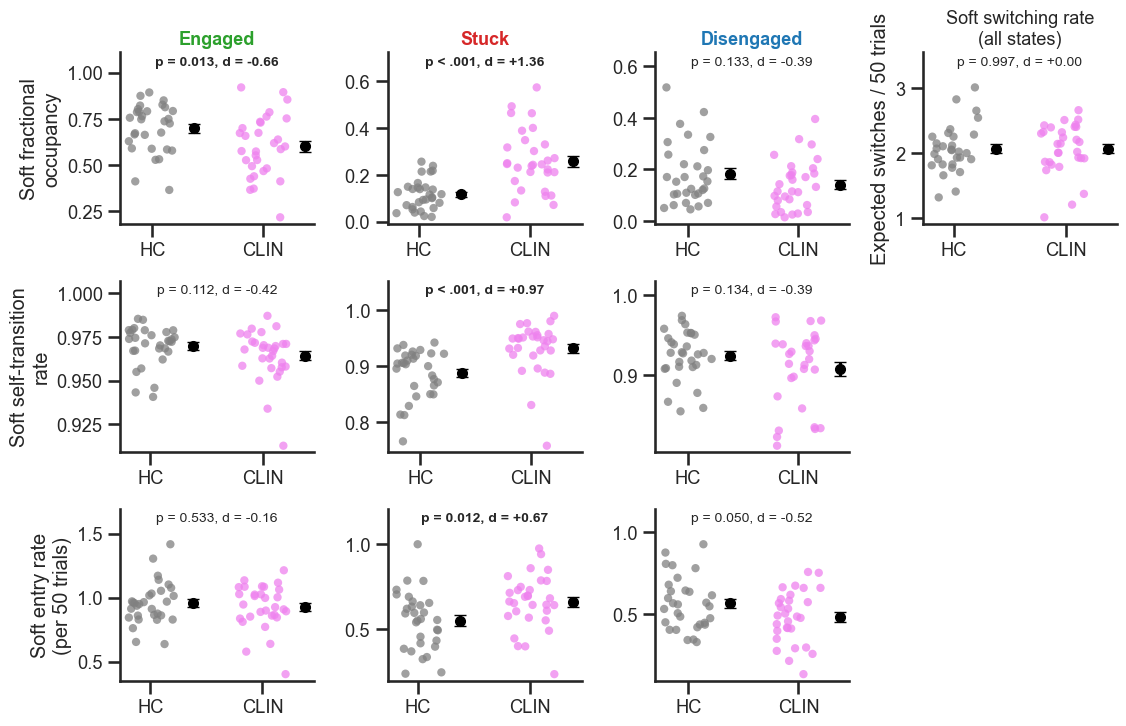

In [60]:
rows, sr_rows = [], []
for s_ in range(N_SUBJ):
    met = soft_metrics(G[s_], XI[s_])                                                  # same helper as Section 3.4
    for k in range(3):
        rows.append({'subject': s_, 'group': group[s_], 'state': STATES[k], 'FO': met['FO'][k], 'p_self': met['p_self'][k], 'entry': met['entry'][k]})
    sr_rows.append({'subject': s_, 'group': group[s_], 'SR': met['entry'].sum()})       # all switches per 50 trials = sum of the entry rates

metrics = pd.DataFrame(rows)
switching = pd.DataFrame(sr_rows)
for d_ in (metrics, switching):
    d_['group'] = pd.Categorical(d_['group'], categories=GROUPS)

res_m = group_ttests(metrics, ['FO', 'p_self', 'entry'], split='state')              # Welch t-tests, CLIN vs HC
res_sr = group_ttests(switching, ['SR'])

fig = plt.figure(figsize=(11.5, 7.5))
gs = fig.add_gridspec(3, 4, width_ratios=[1, 1, 1, 1])
for j, st in enumerate(STATES):
    sub = metrics[metrics.state == st]
    for r, (m, lab) in enumerate([('FO', 'Soft fractional\noccupancy'), ('p_self', 'Soft self-transition\nrate'), ('entry', 'Soft entry rate\n(per 50 trials)')]):
        a = fig.add_subplot(gs[r, j])
        strip_means(a, sub, m)
        annotate_test(a, res_m[(res_m.split == st) & (res_m.measure == m)].iloc[0])
        a.set_ylabel(lab if j == 0 else '')
        if r == 0:
            a.set_title(st, fontsize=13, color=STATE_COLORS[j], fontweight='bold')
a = fig.add_subplot(gs[0, 3])                                                          # all states together
strip_means(a, switching, 'SR')
annotate_test(a, res_sr.iloc[0])
a.set_ylabel('Expected switches / 50 trials')
a.set_title('Soft switching rate\n(all states)', fontsize=13)
fig.tight_layout()

print_ttests(res_m, 'Soft state metrics (posteriors)')
print_ttests(res_sr, 'Soft switching rate')

### 4.2 Participant-level transition matrices

The self-transition rates of Section 4.1 are the diagonal of a full transition matrix. Here we build that matrix for every participant from $\xi$: expected $i \to j$ moves divided by expected moves out of $i$ (`participant_matrices`). The off-diagonals add *where* people go when they leave a state. We average the matrices within each group and compare every transition between the groups.

**Note**: The main result is in the moves between Engaged and Stuck, as planted (Section 2.5): 
- CLIN enters Stuck from Engaged more often and leaves it less often (higher Stuck→Stuck, lower Stuck→Engaged and Stuck→Disengaged; both ways out of Stuck were halved).
- Engaged→Stuck is an average over all trials, so the reversal trigger, which acts only right after a reversal, shows up as a small increase; Section 4.3 shows when the entries happen.

**Note**: Be careful with rare moves. The average participant has less than one expected Stuck→Disengaged move and only about $0.2$ expected Disengaged→Stuck moves (printout). With so little data, a participant's rate is mostly the pooled $A$ (the prior on every move in $\xi$), nudged by the surrounding trials, so the spread across participants is tiny and a t-test can call even a very small difference significant. CLIN's Disengaged→Stuck rate is nudged up because CLIN spends more time Stuck (trials after a Disengaged stretch look more Stuck-like) and less time Disengaged (the leaked probability is divided by fewer Disengaged trials). This reflects time spent in each state, not a more likely move: both groups have the same planted probability ($0.01$). Stuck→Disengaged has the planted direction, but both estimates are about twice the planted values ($0.010$ and $0.005$). Before interpreting a transition, check how many expected moves it rests on.

**Note**: The $9$ tests are not independent (each row sums to $1$). Consider a multiple-comparisons correction (for example Bonferroni, $p < .05/9 \approx .0056$, which stays valid but conservative when tests are correlated). Here all five significant transitions survive it, Disengaged→Stuck included: a correction does not protect against a biased estimate, so the check on expected counts is still needed.

=== Participant-level transition probabilities: CLIN vs HC (Welch t-test) ===
Eng→Eng | prob           HC=  0.970  CLIN=  0.964  t= -1.62  p=0.1118  d=-0.42  n.s.
Eng→Stuck | prob         HC=  0.016  CLIN=  0.022  t= +3.28  p=0.0018  d=+0.85  **
Eng→Dis | prob           HC=  0.014  CLIN=  0.013  t= -0.68  p=0.4967  d=-0.18  n.s.
Stuck→Eng | prob         HC=  0.091  CLIN=  0.056  t= -3.43  p=0.0011  d=-0.89  **
Stuck→Stuck | prob       HC=  0.888  CLIN=  0.931  t= +3.76  p=0.0004  d=+0.97  ***
Stuck→Dis | prob         HC=  0.022  CLIN=  0.012  t= -3.10  p=0.0034  d=-0.80  **
Dis→Eng | prob           HC=  0.072  CLIN=  0.083  t= +1.21  p=0.2312  d=+0.31  n.s.
Dis→Stuck | prob         HC=  0.004  CLIN=  0.008  t= +3.10  p=0.0038  d=+0.80  **
Dis→Dis | prob           HC=  0.924  CLIN=  0.908  t= -1.52  p=0.1339  d=-0.39  n.s.
Significant (p < .05): Eng→Stuck | prob, Stuck→Eng | prob, Stuck→Stuck | prob, Stuck→Dis | prob, Dis→Stuck | prob

HC: expected number of moves per participant (group

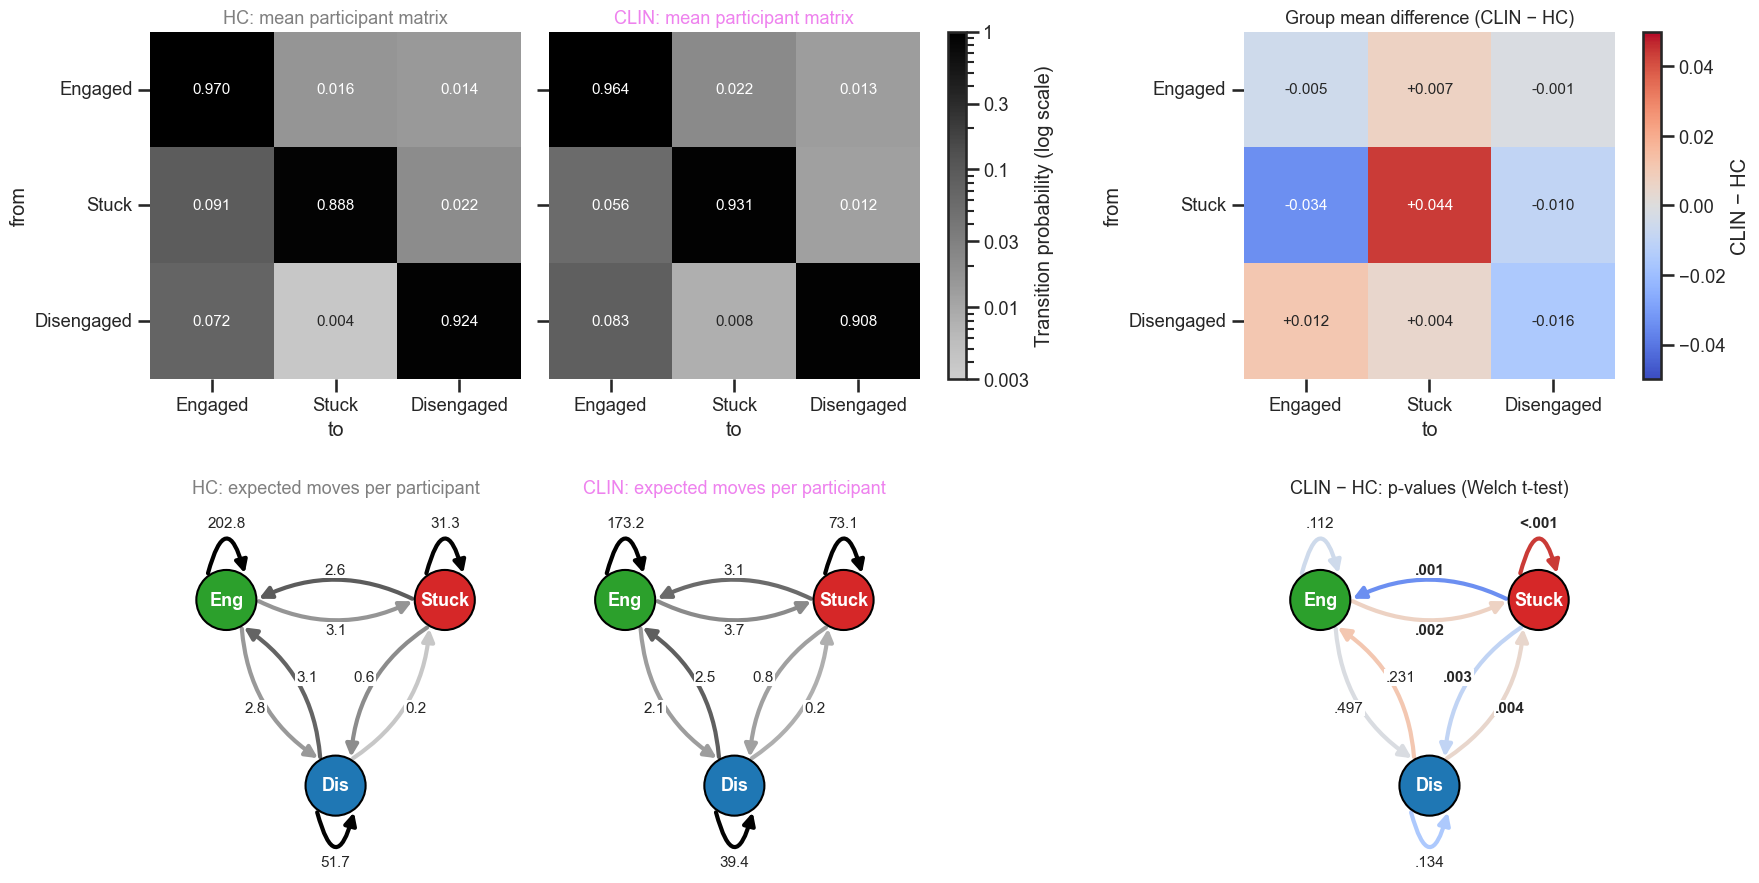

In [62]:
SHORT = ['Eng', 'Stuck', 'Dis']
def transition_tests(A_subj):
    # Welch t-test (CLIN vs HC) for every transition i -> j; NaN rows (state never visited) are dropped by group_ttests
    rows = []
    for s_ in range(N_SUBJ):
        for i in range(3):
            for j in range(3):
                rows.append({'subject': s_, 'group': group[s_], 'transition': f'{SHORT[i]}→{SHORT[j]}', 'prob': A_subj[s_, i, j]})
    trans = pd.DataFrame(rows)
    trans['group'] = pd.Categorical(trans['group'], categories=GROUPS)
    return group_ttests(trans, ['prob'], split='transition').set_index('split')

A_subj = participant_matrices(XI)                         # (participants, K, K): expected i -> j moves / expected moves out of i
res_tr = transition_tests(A_subj)
p_mat = np.array([[res_tr.loc[f'{SHORT[i]}→{SHORT[j]}', 'p'] for j in range(3)] for i in range(3)])
A_mean = {g: np.nanmean(A_subj[group == g], axis=0) for g in GROUPS}                    # group-mean participant matrices
A_diff = A_mean['CLIN'] - A_mean['HC']                                                   # group mean difference, CLIN - HC
n_moves = XI.sum(1)                                       # expected number of each move, per participant
n_mean = {g: n_moves[group == g].mean(0) for g in GROUPS}

# colors: a log scale for the probabilities (rare moves stay visible), a symmetric diverging scale for the difference
prob_cmap = ListedColormap(plt.cm.Greys(np.linspace(0.3, 1, 256)))                      # light grey (rare) -> black (common)
prob_norm = LogNorm(vmin=0.003, vmax=1)
diff_cmap = plt.cm.coolwarm                                                               # blue = lower in CLIN, red = higher
lim = np.ceil(np.abs(A_diff).max() * 100) / 100
diff_norm = Normalize(vmin=-lim, vmax=lim)

fig = plt.figure(figsize=(19.5, 11))
gs = fig.add_gridspec(2, 6, width_ratios=[1, 1, 0.05, 0.6, 1, 0.05], height_ratios=[1, 1.1], wspace=0.12, hspace=0.32)
top = [fig.add_subplot(gs[0, c]) for c in (0, 1, 4)]                 # columns 2 and 5 hold the colorbars, column 3 is a spacer
bottom = [fig.add_subplot(gs[1, c]) for c in (0, 1, 4)]

# top row: matrices
for a, g in zip(top, GROUPS):
    plot_matrix(a, A_mean[g], STATES, title=f'{g}: mean participant matrix', size=11, cmap=prob_cmap, vmin=None, vmax=None, norm=prob_norm)
    a.title.set_color(GROUP_COLORS[g])
top[1].set(ylabel='', yticklabels=[])                                                   # same rows as the HC matrix
plot_matrix(top[2], A_diff, STATES, title='Group mean difference (CLIN − HC)', fmt='+.3f', size=11, cmap=diff_cmap, vmin=None, vmax=None, norm=diff_norm)
cb = fig.colorbar(ScalarMappable(prob_norm, prob_cmap), cax=fig.add_subplot(gs[0, 2]))          # shared by both groups
cb.set_ticks([0.003, 0.01, 0.03, 0.1, 0.3, 1], labels=['0.003', '0.01', '0.03', '0.1', '0.3', '1'])
cb.set_label('Transition probability (log scale)')
cb = fig.colorbar(ScalarMappable(diff_norm, diff_cmap), cax=fig.add_subplot(gs[0, 5]))
cb.set_label('CLIN − HC')

# bottom row: the same transitions as diagrams; arrows colored as in the matrix above
for a, g in zip(bottom, GROUPS):
    draw_transition_diagram(a, SHORT, A_mean[g], np.vectorize('{:.1f}'.format)(n_mean[g]), prob_cmap, prob_norm, STATE_COLORS,
                            title=f'{g}: expected moves per participant')
    a.title.set_color(GROUP_COLORS[g])
p_lab = np.vectorize(lambda p: '<.001' if p < 0.001 else f'{p:.3f}'.lstrip('0'))(p_mat)               # compact: .231, <.001
draw_transition_diagram(bottom[2], SHORT, A_diff, p_lab, diff_cmap, diff_norm, STATE_COLORS, bold=p_mat < 0.05,
                        title='CLIN − HC: p-values (Welch t-test)')

print_ttests(res_tr.reset_index(), 'Participant-level transition probabilities')
for g in GROUPS:
    print(f'\n{g}: expected number of moves per participant (group mean; row = from, column = to)')
    print(pd.DataFrame(n_mean[g], index=SHORT, columns=SHORT).round(1).to_string())

### 4.3 Around the reversals: learning deficit or getting stuck?

This is the direct test of "*slow learning*" versus "*stuck episodes*" on the behavior that started the story.

#### 4.3a Whether and when people get stuck?

The HMM never sees when the reversals happen: its only inputs are the *observations*, *stay bias* and the *previous reward*. It can still find reversal-triggered Stuck episodes, because a triggered episode shows up in behavior as a run of lose-stays on the arm that just stopped paying. 

We align two posterior quantities to the five reversals and average them within, then across, participants.

- **Whether:** $P(\text{Stuck} \mid \text{data}) = \gamma_t(\text{Stuck})$ on each trial. *Test:* each participant's mean in trials $1$ to $10$ minus their mean in trials $-5$ to $-1$ (baseline).
- **When:** the probability of *entering* Stuck on trial $t$, $\sum_{i \neq \text{Stuck}} \xi_{t-1}(i, \text{Stuck})$ (`entries_into`). *Test:* each participant's expected number of entries in trials $1$ to $5$.

**Note**: Both tests find the group difference, but the posterior is only approximate about *when* episodes start. We know from the simulation (Section 2.5) that nothing makes Stuck more likely as a swap approaches: before the swap, people enter Stuck only at the background rate, the same in both groups, and the trigger acts on losses in trials $0$ to $2$, so a triggered episode starts on trial $1$ at the earliest. Yet in CLIN, $P(\text{Stuck})$ rises from about $0.24$ at trial $-5$ to $0.31$ at trial $0$, and almost as much entry probability lands on trials $-5$ to $0$ as on trials $1$ to $5$. Three things pull the estimated starts earlier:
- *The start of an episode is uncertain.* Once lose-stays after the swap show that someone is Stuck, the posterior must also decide when the episode began. The trials just before a swap are mostly win-stays on the good arm, which barely tell Stuck from Engaged ($0.95$ vs $0.92$), so the posterior spreads the start back over them.
- *Nearby episodes are joined.* When one episode ends a few trials before the swap and a new one starts right after, the win-stays in between carry little evidence, and joining the two saves two unlikely transitions. The posterior then shows one long episode, with no exit before the swap and no entry after it.
- *The fitted $A$ is the same on every trial*, so nothing tells the model that entries are much more likely right after a swap.

So the posterior answers *whether* well (more Stuck after swaps in CLIN) and *when* only to within a few trials. Use windows of several trials, as the tests here do, rather than the entry probability of a single trial.

=== Rise in P(Stuck) after a reversal (trials 1-10 minus -5 to -1): CLIN vs HC (Welch t-test) ===
stuck_rise               HC=  0.008  CLIN=  0.132  t= +3.74  p=0.0005  d=+0.97  ***
Significant (p < .05): stuck_rise
=== Expected entries into Stuck, trials 1-5 after a reversal: CLIN vs HC (Welch t-test) ===
stuck_entries            HC=  0.060  CLIN=  0.157  t= +4.58  p=3.4e-05  d=+1.18  ***
Significant (p < .05): stuck_entries


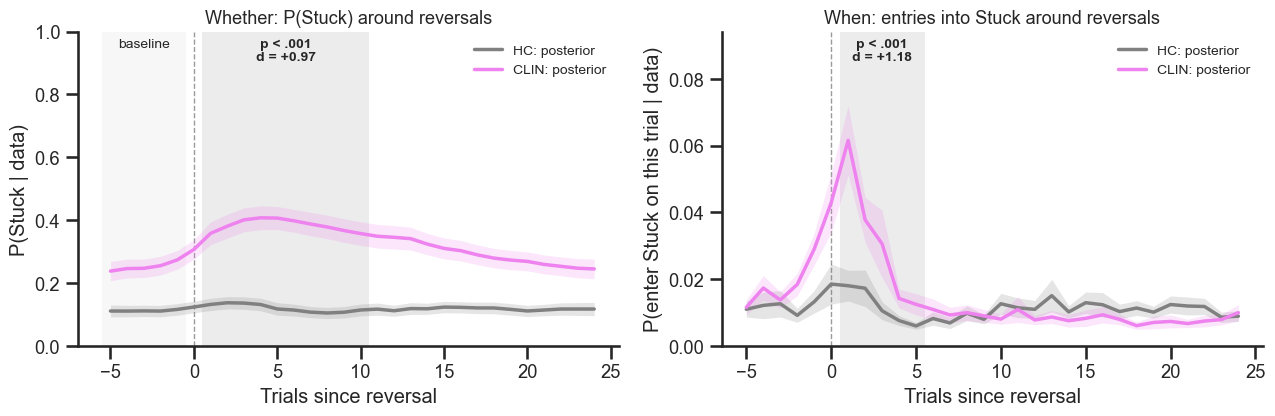

In [65]:
LAGS = np.arange(-5, 25)                                           # trials relative to each reversal (0 = first trial of the new block)

# (left) whether: P(Stuck | data) on each trial, and the true Stuck state (simulation only)
peri = peri_reversal(G[:, :, 1], (Z_emit == 1).astype(float), LAGS)

# (right) when: P(enter Stuck on trial t | data) = sum over i != Stuck of xi_{t-1}(i, Stuck), and the true entries (simulation only)
enter_post = entries_into(XI, 1)                                   # index t-1 corresponds to trial t, as for gamma
enter_true = entries_into(onehot_posteriors(Z_emit)[1], 1)         # the same helper on the true path
peri_enter = peri_reversal(enter_post, enter_true, LAGS)

# test (left): rise in P(Stuck) after the reversal (trials 1-10) relative to just before it (trials -5 to -1)
wide = peri.pivot_table(index=['subject', 'group'], columns='lag', values='hmm')
rise = (wide.loc[:, 1:10].mean(axis=1) - wide.loc[:, -5:-1].mean(axis=1)).rename('stuck_rise').reset_index()
rise['group'] = pd.Categorical(rise['group'], categories=GROUPS)
res_rise = group_ttests(rise, ['stuck_rise'])

# test (right): expected number of entries into Stuck in trials 1-5 after a reversal (averaged over the 5 reversals)
entries = peri_enter[peri_enter.lag.between(1, 5)].groupby(['subject', 'group']).hmm.sum().rename('stuck_entries').reset_index()
entries['group'] = pd.Categorical(entries['group'], categories=GROUPS)
res_entries = group_ttests(entries, ['stuck_entries'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
plot_peri(ax[0], peri, 'P(Stuck | data)', 'Whether: P(Stuck) around reversals', est_label='posterior')
annotate_window(ax[0], -5, -1, text='baseline', color='#f7f7f7')   # lighter grey = baseline window (trials -5 to -1)
annotate_window(ax[0], 1, 10, res_rise.iloc[0])                    # grey = test window (trials 1-10)
plot_peri(ax[1], peri_enter, 'P(enter Stuck on this trial | data)', 'When: entries into Stuck around reversals', truth_label='true entries', est_label='posterior', ylim=(0, None))
annotate_window(ax[1], 1, 5, res_entries.iloc[0], headroom=0.25)   # grey = test window (trials 1-5)
fig.tight_layout()

print_ttests(res_rise, 'Rise in P(Stuck) after a reversal (trials 1-10 minus -5 to -1)')
print_ttests(res_entries, 'Expected entries into Stuck, trials 1-5 after a reversal')

#### 4.3b How fast people adapt with and without a stuck episode?

The two accounts disagree about the reversals on which CLIN does *not* get stuck: a slow learner adapts slowly after every reversal, while a person who gets stuck is slow only after the reversals followed by a Stuck episode. So we sort the reversals by what happened right after them, and compare the groups within each kind.

**Step 1: sort the reversals (softly).** For each participant and reversal, the posterior gives the probability of three kinds (`reversal_weights`):

| Kind | What happened | Probability |
|---|---|---|
| **stayed Engaged** | Engaged on trial $0$ and not Stuck on trials $1$ to $5$ | $p_\text{eng} = P(z_0 = \text{Engaged},\ z_1, \dots, z_5 \neq \text{Stuck} \mid \text{data})$ |
| **got stuck** | Stuck on at least one of trials $1$ to $5$ (including an episode that began before the swap and carried over) | $p_\text{stuck} = 1 - P(z_1, \dots, z_5 \neq \text{Stuck} \mid \text{data})$ |
| **other** | neither (mostly Disengaged on trial $0$, then not Stuck) | $1 - p_\text{stuck} - p_\text{eng}$ |

Each reversal counts toward each kind *in proportion to* its probability: a reversal with $p_\text{stuck} = 0.7$ adds $0.7$ to "got stuck" and its remaining $0.3$ to the other two kinds.

**Step 2: compare the groups within each kind.** Participants whose weights for a kind add up to less than half a reversal are left out (the $n$ in each panel).
- *Top row, learning curves:* each participant's curve is the average of their five reversal curves, weighted by that kind's probability. *Test:* the weighted fraction of choices of the new better arm in trials $1$ to $10$.
- *Bottom row, feedback sensitivity in the same trials:* the reward weight $w_1$ of the weighted logistic regression of Section 2.4c, fitted to trials $1$ to $10$ after each swap with the kind's probability as the trial weight. The dashed and dotted lines are the pooled Engaged and Stuck weights (Section 3.3).

Share of reversals of each kind (posterior-weighted):
       stayed Engaged  got Stuck  other
group                                  
HC              0.595      0.174  0.231
CLIN            0.373      0.452  0.175 

Participants with at least half a reversal of each kind: stayed Engaged: HC 30, CLIN 28 | got Stuck: HC 20, CLIN 29 | other: HC 23, CLIN 17 

=== P(new better arm), trials 1-10, reversals where people stayed Engaged: CLIN vs HC (Welch t-test) ===
p_new_1to10              HC=  0.725  CLIN=  0.739  t= +0.65  p=0.5178  d=+0.17  n.s.
Significant (p < .05): none
=== Reward weight w1, trials 1-10, stayed Engaged: CLIN vs HC (Welch t-test) ===
w1                       HC=  1.852  CLIN=  1.840  t= -0.06  p=0.9495  d=-0.02  n.s.
Significant (p < .05): none
=== P(new better arm), trials 1-10, reversals where people got Stuck: CLIN vs HC (Welch t-test) ===
p_new_1to10              HC=  0.482  CLIN=  0.397  t= -1.05  p=0.2978  d=-0.31  n.s.
Significant (p < .05): none
=== Reward weight

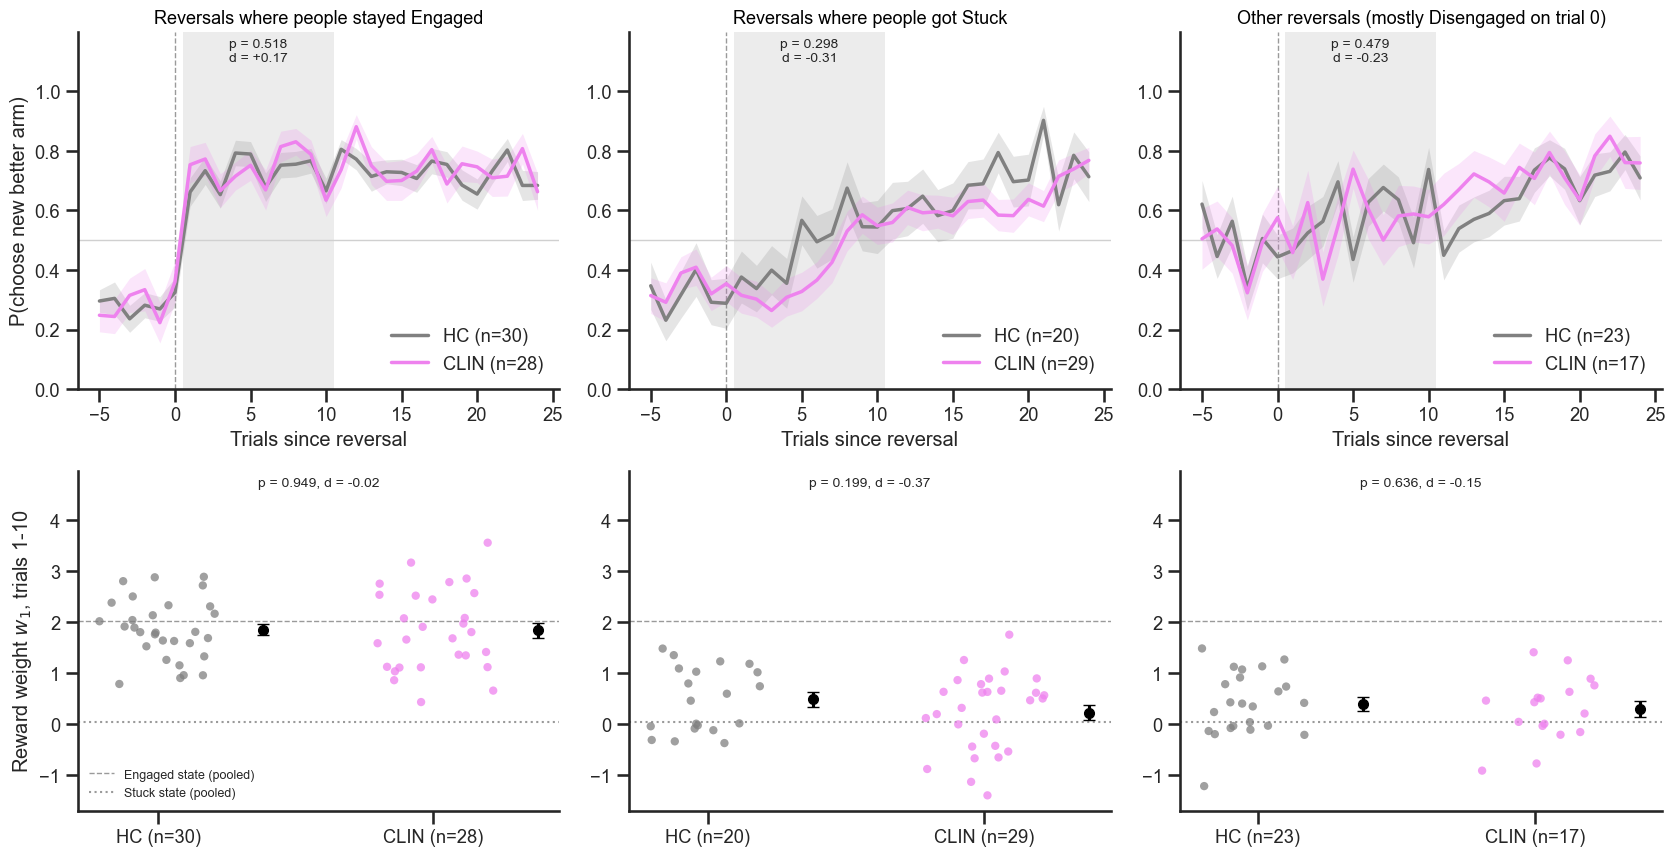

In [67]:
def path_prob(gamma, xi, s_, start, stop, allowed):
    # P(z_t is in allowed[t] for every index t in start..stop-1 | data), for participant s_.
    # Given the data, the hidden states form a Markov chain with transitions xi_t(i, j) / gamma_t(i); we follow it across the window.
    # allowed: {index: list of allowed states}; indices not listed allow every state. One-hot gamma/xi (a Viterbi path) give 0 or 1.
    K = gamma.shape[-1]
    ok = lambda t: np.isin(np.arange(K), allowed.get(t, range(K)))
    v = gamma[s_, start] * ok(start)
    for t in range(start, stop - 1):
        step = np.divide(xi[s_, t], gamma[s_, t][:, None], out=np.zeros((K, K)), where=gamma[s_, t][:, None] > 0)
        v = (v @ step) * ok(t + 1)
    return v.sum()

def reversal_weights(gamma, xi, s_, rv, win=5):
    # Two posterior probabilities for one reversal (trial t after the swap is index rv + t - 1, so trial 0 is index rv - 1):
    #   p_stuck: Stuck on at least one of trials 1..win            = 1 - P(not Stuck on any of trials 1..win)
    #   p_eng:   Engaged on trial 0 and not Stuck on trials 1..win
    not_stuck = {t: [0, 2] for t in range(rv, rv + win)}
    p_stuck = 1 - path_prob(gamma, xi, s_, rv, rv + win, not_stuck)
    p_eng = path_prob(gamma, xi, s_, rv - 1, rv + win, {rv - 1: [0], **not_stuck})
    return p_stuck, p_eng

W_REV = {(s_, rv): reversal_weights(G, XI, s_, rv) for s_ in range(N_SUBJ) for rv in REVERSALS}     # (p_stuck, p_eng) per reversal
weight_of = {'Engaged': lambda s_, rv: W_REV[s_, rv][1],                    # stayed Engaged
             'Stuck':   lambda s_, rv: W_REV[s_, rv][0],                    # got stuck
             'other':   lambda s_, rv: 1 - sum(W_REV[s_, rv])}              # the rest (mostly Disengaged on trial 0)
KIND = {'Engaged': 'stayed Engaged', 'Stuck': 'got Stuck', 'other': 'other'}
rcs = {k: reversal_curves(fn) for k, fn in weight_of.items()}               # weighted reversal curves, one table per kind
share = pd.DataFrame({k: rc[rc.lag == 0].groupby('group').w.mean() for k, rc in rcs.items()})        # share of each group's reversals

def kind_measures(kind, l2=0.1):
    # Per participant, for one kind of reversal: the weighted fraction of choices of the new better arm in trials 1-10 after the
    # swap, and the reward weight w1 of a logistic regression fitted to those trials (trial weight = the kind's probability).
    # Participants with less than half a reversal of this kind are left out, as in plot_reversal.
    rows = []
    for s_ in range(N_SUBJ):
        w_rev = np.array([weight_of[kind](s_, rv) for rv in REVERSALS])     # one weight per reversal
        if w_rev.sum() < 0.5:
            continue
        p_new = np.array([np.mean(C[s_, rv + 1:rv + 11] == better_arm()[rv]) for rv in REVERSALS])
        g_t = np.zeros(Y.shape[1])
        for rv, w in zip(REVERSALS, w_rev):
            g_t[rv:rv + 10] = w                                              # trials 1-10 after the swap = model indices rv..rv+9
        w1 = fit_weights(X[s_:s_ + 1], Y[s_:s_ + 1], g_t[None], np.zeros(2), l2=l2)[1]
        rows.append({'subject': s_, 'group': group[s_], 'p_new_1to10': w_rev @ p_new / w_rev.sum(), 'w1': w1})
    d = pd.DataFrame(rows)
    d['group'] = pd.Categorical(d['group'], categories=GROUPS)
    return d

meas = {k: kind_measures(k) for k in KIND}
res_p = {k: group_ttests(meas[k], ['p_new_1to10']) for k in KIND}          # top row tests
res_w = {k: group_ttests(meas[k], ['w1']) for k in KIND}                   # bottom row tests

fig, ax = plt.subplots(2, 3, figsize=(17, 8.8), gridspec_kw={'height_ratios': [1, 0.95]})
w_lo = min(d.w1.min() for d in meas.values()) - 0.3
w_hi = max(d.w1.max() for d in meas.values()) + 0.3
for j, (k, name) in enumerate(KIND.items()):
    plot_reversal(ax[0, j], rcs[k], f'Reversals where people {name}' if k != 'other' else 'Other reversals (mostly Disengaged on trial 0)')
    annotate_window(ax[0, j], 1, 10, res_p[k].iloc[0], headroom=0.2)         # grey = trials 1-10, the window the tests use
    ax[0, j].set_yticks(np.arange(0, 1.01, 0.2))
    strip_means(ax[1, j], meas[k], 'w1')
    ax[1, j].axhline(W_hat[0, 1], color='#9a9a9a', ls='--', lw=1, zorder=0, label='Engaged state (pooled)')
    ax[1, j].axhline(W_hat[1, 1], color='#9a9a9a', ls=':', lw=1.5, zorder=0, label='Stuck state (pooled)')
    ax[1, j].set_ylim(w_lo, w_hi)                                            # same scale in all three columns
    annotate_test(ax[1, j], res_w[k].iloc[0])
    ax[1, j].set_xticks([0, 1], [f'{g_} (n={np.sum(meas[k].group == g_)})' for g_ in GROUPS])
    ax[1, j].set_ylabel('Reward weight $w_1$, trials 1-10' if j == 0 else '')
    if j > 0:
        ax[0, j].set_ylabel('')
ax[1, 0].legend(frameon=False, fontsize=9, loc='lower left')
fig.tight_layout()

print('Share of reversals of each kind (posterior-weighted):')
print(share.rename(columns=KIND).loc[GROUPS].round(3).to_string(), '\n')
print('Participants with at least half a reversal of each kind:',
      ' | '.join(f"{KIND[k]}: HC {np.sum(meas[k].group == 'HC')}, CLIN {np.sum(meas[k].group == 'CLIN')}" for k in KIND), '\n')
for k, name in KIND.items():
    print_ttests(res_p[k], f'P(new better arm), trials 1-10, reversals where people {name}' if k != 'other' else 'P(new better arm), trials 1-10, other reversals')
    print_ttests(res_w[k], f'Reward weight w1, trials 1-10, {name}')

**Step 3: what if CLIN got stuck as rarely as HC? (Optional)** The figure repeats the learning curves and test of Section 2.8 (all reversals, solid) and adds a counterfactual (dashed): CLIN's own weighted curve for each kind of reversal, added in **HC's** shares ($60\%$ stayed Engaged, $17\%$ got stuck, $23\%$ other) instead of CLIN's own. The dashed curve changes only the mix of reversals: in effect, a got-stuck reversal counts $0.38$ times ($17\% / 45\%$) and a stayed-Engaged one $1.59$ times ($60\% / 37\%$). 

*Test (dashed vs HC):* the same reweighting is applied to each CLIN participant's own reversals, and their weighted fraction of choices of the new better arm in trials $1$ to $10$ is compared with HC's.

All reversals, trials 1-10: HC 0.649, CLIN 0.541, CLIN stuck as rarely as HC 0.636 (88% of the gap closes)
=== P(new better arm), trials 1-10: CLIN stuck as rarely as HC (shown as CLIN) vs HC: CLIN vs HC (Welch t-test) ===
p_new_1to10              HC=  0.649  CLIN=  0.625  t= -1.02  p=0.3099  d=-0.26  n.s.
Significant (p < .05): none


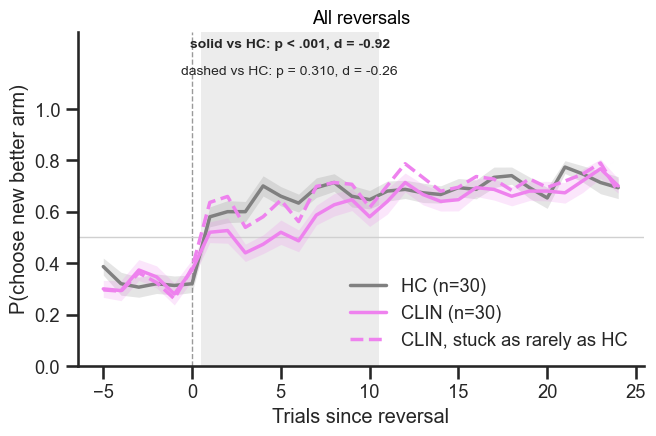

In [69]:
# CLIN's own curve for each kind of reversal (pooled over all CLIN reversals), recombined with HC's share of each kind
clin_curve = {k: rc[rc.group == 'CLIN'].assign(wp=lambda d: d.w * d.p_new).groupby('lag')[['wp', 'w']].sum().pipe(lambda d: d.wp / d.w)
              for k, rc in rcs.items()}
cf = sum(share.loc['HC', k] * clin_curve[k] for k in rcs)
p_all = reversal_curves().query('lag >= 1 and lag <= 10').groupby('group').p_new.mean()     # Section 2.8, trials 1-10
closed = (cf.loc[1:10].mean() - p_all['CLIN']) / (p_all['HC'] - p_all['CLIN'])

# test (dashed vs HC): the same reweighting for each CLIN participant. Each reversal counts sum_kind p(kind) * share_HC / share_CLIN
# (a got-stuck reversal counts less, a stayed-Engaged one more); then the weighted fraction of new-arm choices in trials 1-10.
ratio = {k: share.loc['HC', k] / share.loc['CLIN', k] for k in rcs}
cf_rows = []
for s_ in np.where(group == 'CLIN')[0]:
    omega = np.array([sum(weight_of[k](s_, rv) * ratio[k] for k in rcs) for rv in REVERSALS])     # one weight per reversal
    p_new = np.array([np.mean(C[s_, rv + 1:rv + 11] == better_arm()[rv]) for rv in REVERSALS])
    cf_rows.append({'subject': s_, 'group': 'CLIN', 'p_new_1to10': omega @ p_new / omega.sum()})
cf_subj = pd.concat([adapt[adapt.group == 'HC'], pd.DataFrame(cf_rows)], ignore_index=True)
cf_subj['group'] = pd.Categorical(cf_subj['group'], categories=GROUPS)
res_cf = group_ttests(cf_subj, ['p_new_1to10'])                              # 'CLIN' here = CLIN, stuck as rarely as HC

def test_label(r):
    return ('p < .001' if r.p < 0.001 else f'p = {r.p:.3f}') + f', d = {r.d:+.2f}'

fig, ax = plt.subplots(figsize=(6.8, 4.6))
plot_reversal(ax, reversal_curves(), 'All reversals')
ax.plot(cf.index, cf.values, '--', color=GROUP_COLORS['CLIN'], lw=2.5, label='CLIN, stuck as rarely as HC')
ax.legend(frameon=False, loc='lower right')
annotate_window(ax, 1, 10, headroom=0.3)                                     # grey = trials 1-10, the window the tests use
for y, lab, r in [(0.98, 'solid', res_adapt.iloc[0]), (0.90, 'dashed', res_cf.iloc[0])]:       # each vs HC
    ax.text(5.5, y, f'{lab} vs HC: {test_label(r)}', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, fontweight='bold' if r.p < 0.05 else 'normal')
ax.set_yticks(np.arange(0, 1.01, 0.2))                                       # headroom for the text, ticks only up to 1
fig.tight_layout()

own = sum(share.loc['CLIN', k] * clin_curve[k] for k in rcs)                 # sanity check: CLIN's own shares give back the solid curve
print(f"All reversals, trials 1-10: HC {p_all['HC']:.3f}, CLIN {p_all['CLIN']:.3f}, CLIN stuck as rarely as HC {cf.loc[1:10].mean():.3f} ({closed:.0%} of the gap closes)")
print_ttests(res_cf, 'P(new better arm), trials 1-10: CLIN stuck as rarely as HC (shown as CLIN) vs HC')

**Summary:**
- *Stayed Engaged* (left column above): no group difference in how often people chose the new better arm (HC $0.73$, CLIN $0.74$; $p = .52$), nor in how strongly their choices followed feedback ($w_1$: $1.85$ vs $1.84$; $p = .95$). When CLIN stays engaged, it learns as fast as HC: there is no learning deficit.
- *Got stuck* (middle column): both groups adapt slowly ($0.48$ vs $0.40$; $p = .30$), and their choices barely follow feedback ($w_1$: $0.48$ vs $0.22$, close to the Stuck state's; $p = .20$). CLIN tends to be slower here because its Stuck episodes last longer, but with only $20$ HC participants contributing, this is a trend at most.
- *Other* (right column): no group difference ($p = .48$ and $p = .64$).
- *All reversals together* (solid curves, Section 2.8): CLIN adapts more slowly ($0.54$ vs $0.65$; $p < .001$, $d = -0.92$).

Within each kind of reversal the groups behave alike, yet over all reversals they differ. Both hold because the overall curve is a mix of the three kinds, weighted by how often each happens, and CLIN's mix contains far more of the stuck kind: CLIN got stuck after $45\%$ of its reversals, HC after $17\%$. Reweighted to HC's mix closes the gap and the group difference is no longer significant (dashed vs HC: $0.63$ vs $0.65$; $p = .31$).

## 5. Wrap-up

### What we learned
- An HMM describes behavior as a sequence of hidden states, each with its own policy, and transition probabilities between them.
- The forward algorithm gives the likelihood of the data, forward–backward gives trial-by-trial state probabilities, Viterbi gives the single most likely state path, and EM learns the parameters.
- A GLM-HMM lets each state's policy depend on task inputs, here the previous outcome.
- In the simulated cohort, the classic measures showed that CLIN stays after losses more often and adapts more slowly after reversals, but not why (Section 2.8). The HMM's posteriors answered it:
  - **How much, how long, how often (Section 4.1):** CLIN spent more time Stuck because it entered Stuck more often *and* stayed longer once there. The overall switching rate did not differ.
  - **Which moves (Section 4.2):** CLIN moved from Engaged into Stuck more often and left Stuck less often, as planted.
  - **Whether and when (Section 4.3a):** $P(\text{Stuck})$ rose after reversals in CLIN only, and CLIN entered Stuck about $2.6$ times as often in the first five trials after a swap.
  - **Slow or stuck (Section 4.3b):** On reversals where participants stayed Engaged, CLIN adapted as fast as HC and followed feedback as strongly ($w_1$: $1.84$ vs $1.85$). This is the test that would have found a learning deficit (Exercise 1), and it found none: CLIN is stuck, not slow. CLIN got stuck after $45\%$ of reversals (HC: $17\%$), and most of the adaptation gap closes when CLIN is given HC's share.
    
### Caveats

**What a state is**
- HMM states are statistical summaries of behavior. A state groups the trials on which choices follow the same rule. Reading it as a certain behavior needs independent evidence: neural or physiological measures, self-report, or manipulations that should move people in and out of the state (Versteijnen & Heimel, 2026).
- States are defined relative to what the model sees. Change the observations or the inputs, and the states change. If the only input is the previous outcome, fatigue, a lapse of attention and a wrong idea of the task can all produce the same behavioral state. Choose inputs that separate the explanations you care about.
- State names come from the researcher, not the model. EM returns states in an arbitrary order, so states must be matched across restarts, folds, groups or participants with an explicit, reported rule before they are compared.

**Assumptions built into the standard HMM**
- Dwell times are geometric: a state is left with the same probability on every trial, so the most likely episode length is one trial. If episodes have a typical length, a hidden semi-Markov model can model dwell times explicitly (Yu, 2010).
- Transitions are the same on every trial. If switching depends on task events, time on task or fatigue, let the transition probabilities depend on inputs (Calhoun, Pillow & Murthy, 2019). Otherwise the model blurs when switches happen.
  
**Choosing and fitting the model**
- The number of states is a modeling choice. The training likelihood always grows with more states, so use held-out likelihood (cross-validation) and check that extra states are stable and interpretable (Pohle, Langrock, van Beest & Schmidt, 2017).
- EM finds local optima. Use many restarts, compare their final log-likelihoods, and check that the best solutions agree.
- Identifiability needs data (Exercise 2). Each state must be visited often enough, and so must the conditions that tell states apart: two states that differ only after losses are separated only by loss trials. With few trials per person, pool across participants or use hierarchical models, and design tasks in which the candidate states make different predictions.

**Reading the results**
- Prefer posterior (soft) quantities to a single decoded path. The most likely path drops short or uncertain episodes, which biases counts of episodes and switches.
- Run posterior predictive checks: simulate from the fitted model and compare statistics it was not fitted to, such as run lengths or learning curves around task events. A model can fit the likelihood well and still miss the behavior you care about.

**HMMs and other models**
- HMMs and process models answer different questions and can be combined. A state can contain a learning model, such as RL-style learning inside an engaged state (Guo, Zeng & Wang, 2025), or the states can be different strategies (Le et al., 2023).

### Project ideas
1. **A true learning deficit.** Fit reward weights differently for each group: give CLIN a smaller Engaged reward weight (e.g., `w1 = 1.0`) but the *same* transition matrix and reversal trigger as HC, which will make CLIN truely a slow learner whose dynamics are the same as HC. Rerun everything. What does the HMM say now, how would this compare with RL or BI?
2. **Fewer trials** Set `T_TRIALS = 150` (two reversals). How do the state recovery and the group effects change?
3. **Vary states.** Fit `K=2` and `K=4`. Which states get merged or split, and what happens to the group comparison? (`name_states` and the plotting helpers assume three states, so name the states by hand.)
4. **More inputs.** Add the outcome from *two* trials back to `X`. Does the Engaged state use it?
5. **Soft vs hard metrics.** Rerun Section 4 on the Viterbi path. A decoded path is a posterior that puts probability 1 on one path. At the top of Section 4, replace `G, XI = gamma_all, xi_all` with `G, XI = onehot_posteriors(Z_hat)` and rerun the section. Every soft metric becomes its hard version: FO, the decoded self-transition rate, the appearance rate and the switching rate (add the dwell time with `path_metrics(Z_hat[s_])['DT']`). Which group differences get larger, which get smaller or disappear, and why?
   *Hint:* Viterbi drops short episodes (Section 3.5). Which group has more short Stuck episodes? Which metrics count episodes, and which count trials? Look in particular at the Stuck entry rate, the Stuck self-transition rate, and Disengaged→Stuck.

### Key references
- Versteijnen & Heimel (2026). Interpreting neural and behavioral data using Hidden Markov Models. *Brain Research*.
- Ashwood, Roy, Stone, IBL, Urai, Churchland, Pouget & Pillow (2022). Mice alternate between discrete strategies during perceptual decision-making. *Nature Neuroscience*.
- Chen, Knep, Han, Ebitz & Grissom (2021). Sex differences in learning from exploration. *eLife*.
- Le et al. (2023). Mixtures of strategies underlie rodent behavior during reversal learning. *PLoS Computational Biology*.
- Guo, Zeng & Wang (2025). HMM for discovering decision-making dynamics using reinforcement learning experiments. *Biostatistics*.
- Yu (2010). Hidden semi-Markov models. *Artificial Intelligence*.
- Pohle, Langrock, van Beest & Schmidt (2017). Selecting the number of states in hidden Markov models: pragmatic solutions illustrated using animal movement. *Journal of Agricultural, Biological and Environmental Statistics*.
- Calhoun, Pillow & Murthy (2019). Unsupervised identification of the internal states that shape natural behavior. *Nature Neuroscience*.